# ASL 50-Word Model: Executed Training Results

This notebook is the executed companion to `word_50_training.ipynb`. It preserves the Kaggle T4 outputs, metrics, and figures from the final 50-class experiment so the recorded results can be reviewed without rerunning training.

For a clean rerunnable source, use `word_50_training.ipynb`. Curated model artifacts are stored under `models/word/web-50/`, while exported reports and figures are under `notebooks/word_50_results/`.


In [1]:
# ---------------------------------------------------------------------------
# KONFIGURASYON
# ---------------------------------------------------------------------------
# Bu hücre notebook'un kontrol panelidir.
#
# Deneyin temel kararları burada toplanır:
# - Hangi kütüphaneler kullanılacak?
# - Çıktılar hangi klasöre kaydedilecek?
# - Eğitim kaç epoch sürecek?
# - Model hangi boyutlarda kurulacak?
# - MediaPipe landmark diziliminde hangi noktalar kullanılacak?
#
# Bu düzenin amacı ayarları dağınık bırakmamaktır. Batch size, epoch sayısı,
# dosya yolu ve çıktı adı gibi kritik değerler tek yerde durduğu için notebook
# daha kolay incelenir, hata ayıklamak kolaylaşır ve deney tekrar edilebilir olur.
# ---------------------------------------------------------------------------

# Standart Python kütüphaneleri:
# - os / glob / pathlib: Dosya ve klasör yollarını bulmak için kullanılır.
# - json: Sonuçları web uygulamasının okuyabileceği JSON dosyalarına yazmak için kullanılır.
# - zipfile: Tüm çıktıları tek indirilebilir zip paketine koymak için kullanılır.
# - hashlib: Dosya bütünlüğünü kontrol etmek için sha256 özetleri üretir.
# - time: Eğitim ve veri hazırlama sürelerini ölçer.
# - traceback: Bir deney hata verirse hatanın nereden geldiğini göstermek için kullanılır.
import os, json, time, warnings, glob, math, traceback, hashlib, zipfile, gc

# Veri işleme ve sayısal hesaplama kütüphaneleri:
# - numpy: Modelin göreceği sayısal diziler burada tutulur.
# - pandas: train.csv ve parquet dosyaları gibi tablo formatındaki veriler okunur.
# Basit anlatım: pandas veriyi tablo gibi okur, numpy modeli besleyecek sayılara çevirir.
import numpy as np
import pandas as pd

# PyTorch: Yapay sinir ağını kurmak, eğitmek ve GPU'da çalıştırmak için kullanılır.
# nn: model katmanlarını tanımlamak için, F: loss/aktivasyon gibi fonksiyonlar için kullanılır.
# DataLoader: veriyi batch adı verilen küçük gruplar halinde modele verir.
# autocast ve GradScaler: GPU'da mixed precision eğitim için kullanılır; bu yöntem belleği azaltıp eğitimi hızlandırabilir.
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler

# sklearn metrikleri model sonucunu ölçmek için kullanılır.
# accuracy genel doğru tahmin oranıdır.
# macro F1 her kelime sınıfını eşit sayar; bu projede ana karar metriği budur.
# confusion matrix hangi kelimelerin birbirine karıştığını gösterir.
from sklearn.metrics import (accuracy_score, f1_score,
                              classification_report, confusion_matrix)

# matplotlib ve seaborn grafik üretmek için kullanılır.
# pathlib.Path dosya yollarını daha okunur ve güvenli yönetmeyi sağlar.
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

warnings.filterwarnings("ignore")

# Notebook uzun çalıştığı için bazı kütüphaneler çok fazla uyarı basabilir.
# Bu uyarıların çoğu kritik değildir ve çıktıyı kalabalıklaştırır.
# Gerçek hata olursa yine exception olarak durur; yani önemli hataları gizlemiyoruz.

# Matplotlib grafik ayarları.
# Bu ayarlar tüm grafiklerde ortak görünüm sağlar:
# - DPI yüksek tutulur: Görseller raporda ve dokümantasyonda bulanık olmasın.
# - Font boyutları sabitlenir: Grafikler farklı hücrelerde farklı görünmesin.
# - Arka plan beyaz yapılır: Kaggle çıktısı, rapor ve zip içinde temiz görünür.
# Bu bölüm modelin skorunu değiştirmez; sadece üretilen grafiklerin okunabilirliğini standartlaştırır.
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 220,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "savefig.bbox": "tight",
    "savefig.facecolor": "white",
})

# --- Cikti ve Raporlama Ayarlari ---
# Kaggle'da tum indirilebilir dosyalar /kaggle/working altinda gorunur.
# ASL_OUTPUT_DIR sadece lokal test icin vardir; Kaggle'da varsayilan yol kullanilir.
OUTPUT_DIR = Path(os.environ.get("ASL_OUTPUT_DIR", "/kaggle/working"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ZIP_NAME = "asl_word_model_outputs.zip"

# Bu liste zip'e girmesi beklenen grafiklerin resmi kontrol listesidir.
# Neden liste kullanıyoruz?
# Kaggle'da daha önce çalıştırılmış eski PNG dosyaları /kaggle/working içinde kalabilir.
# Eğer "klasördeki bütün png'leri zip'e koy" dersek eski veya alakasız grafikler de pakete girer.
# Bu liste sayesinde sadece bu notebook'un üretmesi gereken 10 grafik pakete alınır.
FIGURE_FILES = [
    "01_kelime_dagilimi.png",
    "02_sekans_uzunluk.png",
    "03_feature_ablasyonu.png",
    "03_sekans_karsilastirma.png",
    "04_model_karsilastirma.png",
    "05_full_training_egrileri.png",
    "06_kelime_bazli_f1.png",
    "07_confusion_matrix.png",
    "08_tum_deneyler_ozet.png",
    "09_confusion_top_pairs.png",
]

# Model, JSON ve metin rapor gibi grafik disi ana dosyalar.
# Bu liste son paket kontrolunde hangi dosyalarin mutlaka olmasi gerektigini gosterir.
CORE_ARTIFACT_FILES = [
    "word_model.onnx",
    "final_model.pt",
    "temperature.json",
    "word_to_idx.json",
    "per_word_stats.json",
    "curriculum.json",
    "confusion_pairs.json",
    "all_experiment_results.json",
    "classification_report.txt",
    "README_EXPORT.txt",
    "manifest.json",
]


def artifact_path(filename):
    """Bir çıktı dosyası için standart Kaggle çıktı yolunu döndürür.

    Bütün dosyalar aynı fonksiyonla yazıldığı için notebook içinde farklı farklı
    `/kaggle/working/...` yolu kullanmaya gerek kalmaz. Bu, paketleme sırasında
    dosya eksikliği veya yanlış klasöre yazma riskini azaltır.
    """
    # Tüm çıktılar tek merkezden yönetilir; böylece dosya yolu mantığı dağılmaz.
    return OUTPUT_DIR / filename


def save_figure(fig, filename):
    """Grafiği standart kaliteyle kaydeder ve belleği temizler.

    Bu fonksiyon her grafik için aynı kayıt ayarını kullanır. Böylece raporda
    ve zip paketinde grafiklerin çözünürlüğü, kenar boşlukları ve arka planı tutarlı olur.
    """
    path = artifact_path(filename)
    # dpi=220, grafiklerin dokümantasyonda okunabilir kalması için seçildi.
    fig.savefig(path, dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    # Kaggle uzun notebook koşularında açık kalan figure nesneleri gereksiz bellek kullanır.
    plt.close(fig)
    print(f"[Gorsel] {filename} kaydedildi.")
    print(f"         Anlam: Bu PNG rapor/zip paketi icin uretildi ve {path} yoluna yazildi.")
    return path


def write_json_artifact(filename, data):
    """Web ve rapor tarafından okunacak JSON çıktısını yazar.

    JSON dosyaları modelin kelime listesi, sıcaklık kalibrasyonu, curriculum ve
    hata analizi gibi yapılandırılmış bilgilerini taşır. Web uygulaması bu dosyaları
    doğrudan okuyabileceği için formatın düzenli olması önemlidir.
    """
    path = artifact_path(filename)
    # ensure_ascii=False Türkçe karakterleri ve kelime isimlerini dosyada okunabilir tutar.
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2, ensure_ascii=False)
    print(f"[JSON] {filename} kaydedildi.")
    print(f"       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.")
    return path


def write_text_artifact(filename, text):
    """Zip paketine girecek insan-okunur metin raporunu yazar.

    README ve classification report gibi dosyalar sonuçları hızlı incelemek için
    kullanılır. Bu dosyalar kod çalıştırmadan da modelin ne ürettiğini anlamayı sağlar.
    """
    path = artifact_path(filename)
    # README ve classification report gibi insan-okunur raporlar burada yazılır.
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
    print(f"[Metin] {filename} kaydedildi.")
    print(f"        Anlam: Bu dosya zip icinde okunabilir rapor/aciklama olarak yer alacak.")
    return path


# --- Cihaz ve Ortam ---
SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PIN_MEMORY = DEVICE.type == "cuda"
DATALOADER_WORKERS = 2


def clear_gpu_memory():
    """GPU ve Python bellegini bosalt. Her faz sonunda cagrilir.

    Kaggle notebook'unda uzun deney zinciri ayni oturumda calistigi icin eski
    tensor, model ve figure referanslari bellek baskisi yaratabilir. CUDA varsa
    GPU cache temizlenir; her ortamda Python garbage collector cagrilir.
    """
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()


def clear_cuda_cache():
    """Geriye uyumluluk icin eski isim; asil is clear_gpu_memory icindedir."""
    clear_gpu_memory()


def make_dataloader(dataset, batch_size, shuffle=False):
    """DataLoader ayarlarını tek yerden yönetir.

    DataLoader, veri setindeki örnekleri modele küçük gruplar halinde verir.
    Bu gruplara batch denir. Batch kullanmak GPU'nun aynı anda birçok örneği
    işlemesini sağlar ve eğitimi hızlandırır.

    persistent_workers sadece num_workers > 0 iken geçerlidir. Bu ayarı burada
    merkezi yönetmek, Kaggle GPU ve lokal CPU ortamlarında aynı kodun bozulmadan
    çalışmasına yardım eder.
    """
    # batch_size: bir eğitim adımında modele kaç video verileceğini belirler.
    # shuffle=True sadece train için kullanılır; val/test sıralı kalır.
    # pin_memory GPU'ya veri kopyalamayı hızlandırır, CPU'da gerekli değildir.
    kwargs = {
        "batch_size": batch_size,
        "shuffle": shuffle,
        "num_workers": DATALOADER_WORKERS,
        "pin_memory": PIN_MEMORY,
    }
    # persistent_workers worker process'lerini epochlar arasinda acik tutar.
    # Bu ayar hiz kazandirir; ama num_workers=0 iken kullanilamaz.
    if DATALOADER_WORKERS > 0:
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


def make_grad_scaler():
    """PyTorch sürüm farklarına uyumlu AMP GradScaler oluşturur.

    AMP, mixed precision eğitim anlamına gelir. GPU'da bazı hesapları float16 ile
    yaparak belleği azaltabilir ve eğitimi hızlandırabilir. GradScaler ise float16
    kullanılırken gradyanların sayısal olarak bozulmasını önlemeye yardım eder.
    """
    if DEVICE.type != "cuda":
        return GradScaler(enabled=False)
    try:
        return GradScaler(device="cuda", enabled=True)
    except TypeError:
        # Bazı PyTorch sürümleri device keyword'ü yerine positional argüman bekler.
        return GradScaler("cuda", enabled=True)

# Veri seti yolu (Kaggle ortaminda farkli yollarda olabilir).
# Kaggle'da veri seti bazen farkli klasor adlariyla mount edilir.
# Bu yuzden once bilinen iki yolu deniyoruz, sonra train.csv dosyasini genel arama ile buluyoruz.
DATA_DIR = Path("/kaggle/input/asl-signs")
if not DATA_DIR.exists():
    DATA_DIR = Path("/kaggle/input/competitions/asl-signs")
if not DATA_DIR.exists():
    train_csv_candidates = glob.glob("/kaggle/input/*/train.csv")
    if train_csv_candidates:
        DATA_DIR = Path(train_csv_candidates[0]).parent

assert DATA_DIR.exists() and (DATA_DIR / "train.csv").exists(), \
    f"Veri seti bulunamadi. Beklenen yol: {DATA_DIR}"

# --- Egitim Parametreleri ---
QUICK_EPOCHS = 25           # Bolum A ve B icin (hizli tarama)
FULL_EPOCHS = 100           # Bolum C icin (tam egitim)
BATCH_SIZE = 64
LR_GRU = 1e-3               # GRU tabanli modeller icin
LR_TRANSFORMER = 5e-4       # Transformer daha hassas olduğu için daha düşük learning rate kullanılır.
WEIGHT_DECAY = 1e-4         # Ağırlıkları aşırı büyümekten koruyan düzenlileştirme katsayısı.
PATIENCE_QUICK = 10         # Hızlı deneylerde validation F1 iyileşmezse beklenen epoch sayısı.
PATIENCE_FULL = 20          # Final eğitimde erken durdurma için daha uzun bekleme süresi.
DROPOUT_GRU = 0.4           # Dropout, bazı bağlantıları geçici kapatarak ezberleme riskini azaltır.
DROPOUT_TRANSFORMER = 0.3
GRAD_CLIP = 1.0             # Gradient clipping, aşırı büyük gradyanları sınırlayarak eğitimi stabil tutar.

# --- Model Boyutlari ---
GRU_HIDDEN = 128
GRU_LAYERS = 2
TRANSFORMER_D = 128
TRANSFORMER_HEADS = 4
TRANSFORMER_LAYERS = 2

# --- Sekans Uzunluklari ---
SEQ_30 = 30
SEQ_45 = 45

# --- Progressive Augmentation ---
AUG_START_EPOCH = 30        # Ilk 30 epoch aug kapali, sonra acik

# --- Landmark Sabitleri ---
# MediaPipe Holistic ciktisindaki 107 landmark secimi
# 21 sag el + 21 sol el + 40 yuz + 25 govde = 107 x 3 = 321D
FINGER_TIPS = [4, 8, 12, 16, 20]
FINGER_MCPS = [1, 5, 9, 13, 17]
FINGER_PIPS = [2, 6, 10, 14, 18]
FINGER_DIPS = [3, 7, 11, 15, 19]
WRIST = 0

FACE_INDICES = [
    61, 146, 91, 181, 84, 17, 314, 405, 321, 375,    # Dudak dis (10)
    78, 191, 80, 13, 312, 308,                         # Dudak ic (6)
    33, 133, 159, 145, 263, 362, 386, 374,             # Goz (8)
    70, 63, 105, 66, 300, 293, 334, 296,               # Kas (8)
    1, 2, 98, 327, 168, 197, 195, 5,                   # Burun + alin (8)
]
NUM_FACE = 40

POSE_INDICES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16,
                23, 24, 25, 26, 27, 28, 29, 30]
NUM_POSE = 25

NUM_RIGHT = 21
NUM_LEFT = 21
NUM_TOTAL = (NUM_RIGHT + NUM_LEFT + NUM_FACE + NUM_POSE) * 3  # 321
FEATURE_DIM = 168  # Compact feature dim

# Tutarlilik kontrolu
assert len(FACE_INDICES) == NUM_FACE, f"FACE_INDICES uzunlugu {NUM_FACE} olmali"
assert len(POSE_INDICES) == NUM_POSE, f"POSE_INDICES uzunlugu {NUM_POSE} olmali"
assert NUM_TOTAL == 321, f"NUM_TOTAL 321 olmali, su an {NUM_TOTAL}"


def set_seed(seed=SEED):
    """Tekrarlanabilirlik icin tum rastgele sayi ureteclerini sabitle.

    Not: cudnn.deterministic=True ve benchmark=False secildi.
    Bu ayar hizdan biraz feragat eder, fakat deneylerin tekrar edilebilirligini
    artirir. Deney kaydinda ayni seed ile ayni akisi yeniden kosmak daha kolay olur.
    """
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed()
print("=" * 72)
print("ORTAM VE TEMEL AYARLAR")
print("=" * 72)
print(f"Kullanilan cihaz: {DEVICE}")
if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    print(f"Bulunan GPU sayisi: {gpu_count}")
    for gpu_idx in range(gpu_count):
        gpu_name = torch.cuda.get_device_name(gpu_idx)
        gpu_mem = torch.cuda.get_device_properties(gpu_idx).total_memory / 1024**3
        active = "aktif" if gpu_idx == 0 else "yedek"
        print(f"  GPU {gpu_idx}: {gpu_name} ({gpu_mem:.1f} GB) [{active}]")
    if gpu_count > 1:
        print("Yorum: T4x2 ortaminda iki GPU gorunebilir; bu notebook tek model akisi kullandigi icin cuda:0 yeterlidir.")
else:
    print("Yorum: GPU bulunamadi; egitim CPU'da cok daha yavas calisir.")
print(f"Seed: {SEED} -> Sonuclarin tekrar uretilebilir olmasi icin sabitlendi.")
print(f"Veri yolu: {DATA_DIR}")
print(f"Cikti yolu: {OUTPUT_DIR} -> Kaggle'da indirilecek dosyalar burada olusur.")
print(f"Feature boyutu: {FEATURE_DIM}D compact -> Her video frame'i bu sayisal temsile donusecek.")


ORTAM VE TEMEL AYARLAR
Kullanilan cihaz: cuda
Bulunan GPU sayisi: 2
  GPU 0: Tesla T4 (14.6 GB) [aktif]
  GPU 1: Tesla T4 (14.6 GB) [yedek]
Yorum: T4x2 ortaminda iki GPU gorunebilir; bu notebook tek model akisi kullandigi icin cuda:0 yeterlidir.
Seed: 42 -> Sonuclarin tekrar uretilebilir olmasi icin sabitlendi.
Veri yolu: /kaggle/input/competitions/asl-signs
Cikti yolu: /kaggle/working -> Kaggle'da indirilecek dosyalar burada olusur.
Feature boyutu: 168D compact -> Her video frame'i bu sayisal temsile donusecek.


## Kelime Secimi ve Signer-Independent Split

Bu bolumde 50 kelime secilir ve veri kisi bazli train, validation ve test bolumlerine ayrilir. Kelime seciminde iki kriter kullanilir: en az 300 ornek bulunmasi ve mumkun oldugunca gunluk iletisim degeri tasimasi.

Signer-independent split bu proje icin kritiktir. Random split kullanilirsa ayni kisinin videolari hem egitim hem test bolumune girebilir. Bu durumda model isareti genellemeyi degil, kisinin el yapisini, kamera acisini veya hareket tarzini ezberlemeyi ogrenebilir. Ethiopian SL (Nature, 2025) calismasinda random split yaklasik yuzde 94, signer-independent split ise yaklasik yuzde 73 raporlanmistir; bu fark degerlendirmenin ne kadar degisebildigini gosterir.

| Split | Hedef Oran | Kullanimi |
|---|---:|---|
| Train | yuzde 70 | Model agirliklarini ogrenmek |
| Validation | yuzde 15 | Early stopping ve deney secimi |
| Test | yuzde 15 | Sadece raporlama ve final olcum |

Split sonrasi class coverage kontrolu yapilir. 50 sinifin train, validation ve test bolumlerinde bulunmasi gerekir. Eksik sinif varsa notebook erken durur; boylece daha sonra anlasilmesi zor metrik hatalari engellenir.


In [2]:
# ---------------------------------------------------------------------------
# KELIME SECIMI VE VERI BOLME
# ---------------------------------------------------------------------------

# train.csv her videonun etiketini, parquet yolunu ve participant_id bilgisini tutar.
# Bu tablo olmadan hangi dosyanin hangi kelimeye ait oldugunu bilemeyiz.
train_df = pd.read_csv(DATA_DIR / "train.csv")
print("=" * 72)
print("VERI SETI OKUNDU")
print("=" * 72)
print(f"Toplam video: {len(train_df):,}")
print(f"Toplam kelime sinifi: {train_df['sign'].nunique()}")
print(f"Toplam katilimci: {train_df['participant_id'].nunique()}")
print("Yorum: Bu tablo hangi kelimelerin secilecegini ve kisi bazli split'in nasil kurulacagini belirler.")

# --- 50 Kelime Secimi ---
# Once her kelimenin kac ornegi oldugunu sayiyoruz.
# Az ornekli kelimeler modele yeterli tekrar sunmadigi icin daha kararsiz olabilir.
# Bu yuzden ilk filtre: en az 300 ornegi olan kelimeler.
word_counts = train_df["sign"].value_counts()
eligible_words = word_counts[word_counts >= 300].index.tolist()

# Tercih edilen kelimeler (gunluk iletisim, oncelikli)
preferred = [
    "hello", "yes", "no", "please", "thankyou", "bye",
    "mom", "dad", "child", "brother",
    "water", "food", "drink", "eat", "hungry",
    "happy", "sad", "sick", "sleep", "home",
    "go", "give", "look", "wait", "open", "finish",
    "talk", "book", "dog", "hot", "cold",
    "like", "have", "can", "want", "need",
    "help", "friend", "good", "all", "before",
    "big", "different", "new", "more", "name",
    "work", "come", "day", "again",
]

# Tercih edilenlerden veri setinde olanlari al.
# Yani hem gunluk kullanima uygun hem de yeterli ornegi olan kelimeler one geciyor.
selected = [w for w in preferred if w in eligible_words]

# 50'ye tamamla: tercih listesi 50'yi doldurmazsa veri sayisi yeterli diger
# kelimeler eklenir. Boylece model tam 50 sinifla egitilir.
for w in eligible_words:
    if len(selected) >= 50:
        break
    if w not in selected:
        selected.append(w)

# Alfabetik siralama label indekslerini stabil yapar.
# Ayni veriyle tekrar calistirinca word_to_idx ayni kalir.
SELECTED_WORDS = sorted(selected[:50])
NUM_CLASSES = len(SELECTED_WORDS)
if NUM_CLASSES != 50:
    raise RuntimeError(
        f"50 kelime secilemedi; sadece {NUM_CLASSES} uygun kelime bulundu. "
        "preferred listesi veya min ornek kosulu kontrol edilmeli."
    )

word_to_idx = {w: i for i, w in enumerate(SELECTED_WORDS)}
idx_to_word = {i: w for w, i in word_to_idx.items()}

print("\nKELIME SECIMI")
print("-" * 72)
print(f"Secilen kelime sayisi: {NUM_CLASSES}")
print(f"Ilk 10 kelime: {', '.join(SELECTED_WORDS[:10])}")
print("Yorum: Oncelik gunluk iletisimde kullanilabilecek ve veri sayisi yeterli kelimelere verildi.")

# --- Signer-Independent Split ---
filtered_df = train_df[train_df["sign"].isin(SELECTED_WORDS)].copy()
filtered_df["label"] = filtered_df["sign"].map(word_to_idx)

# Split islemi kisi listesi uzerinden yapilir, video listesi uzerinden degil.
# Boylece ayni kisinin farkli videolari train ve test'e dagilmaz.
# Bu nokta cok kritiktir: aksi halde model kisiyi ezberleyip gercekten iyiymis gibi gorunebilir.
set_seed()
signers = filtered_df["participant_id"].unique().copy()
np.random.shuffle(signers)

# Yaklasik oranlar: %70 train, %15 validation, %15 test.
# Kalan kisim otomatik olarak test'e gider; boylece tum kisiler kullanilmis olur.
n_train = int(len(signers) * 0.70)
n_val = int(len(signers) * 0.15)

train_signers = set(signers[:n_train])
val_signers = set(signers[n_train:n_train + n_val])
test_signers = set(signers[n_train + n_val:])

# Overlap kontrolu (kritik — ayni kisi birden fazla split'te OLAMAZ)
assert len(train_signers & val_signers) == 0
assert len(train_signers & test_signers) == 0
assert len(val_signers & test_signers) == 0

train_split = filtered_df[filtered_df["participant_id"].isin(train_signers)].reset_index(drop=True)
val_split = filtered_df[filtered_df["participant_id"].isin(val_signers)].reset_index(drop=True)
test_split = filtered_df[filtered_df["participant_id"].isin(test_signers)].reset_index(drop=True)

print("\nKISI BAZLI VERI BOLME (SIGNER-INDEPENDENT SPLIT)")
print("-" * 72)
print(f"Train: {len(train_split):,} ornek, {len(train_signers)} kisi -> Model bu kisilerden ogrenir.")
print(f"Val:   {len(val_split):,} ornek, {len(val_signers)} kisi -> Egitimde model secimi icin kullanilir.")
print(f"Test:  {len(test_split):,} ornek, {len(test_signers)} kisi -> Final performans olcumudur.")
print("Yorum: Ayni kisi birden fazla bolume girmedigi icin sonuc random split'e gore daha gercekcidir.")

# Her split'te tum kelimeler var mi?
# Bu kontrol artik uyarida kalmaz; 50 sinifin 3 split'te de bulunmasi gerekir.
# Eksik sinif varsa macro F1 yorumu zayiflar ve deney secimi guvenilir olmaz.
for split_name, split_df in [("train", train_split), ("val", val_split), ("test", test_split)]:
    present_classes = set(split_df["label"].unique())
    missing_classes = set(range(NUM_CLASSES)) - present_classes
    assert len(missing_classes) == 0,         f"{split_name} split'te {len(missing_classes)} sinif eksik: {missing_classes}"
    print(f"  {split_name}: {len(present_classes)}/{NUM_CLASSES} sinif mevcut")
print("Yorum: Class coverage tam; her split 50 kelimenin tamamini temsil ediyor.")


VERI SETI OKUNDU
Toplam video: 94,477
Toplam kelime sinifi: 250
Toplam katilimci: 21
Yorum: Bu tablo hangi kelimelerin secilecegini ve kisi bazli split'in nasil kurulacagini belirler.

KELIME SECIMI
------------------------------------------------------------------------
Secilen kelime sayisi: 50
Ilk 10 kelime: all, before, bird, book, brother, brown, bye, can, child, cow
Yorum: Oncelik gunluk iletisimde kullanilabilecek ve veri sayisi yeterli kelimelere verildi.

KISI BAZLI VERI BOLME (SIGNER-INDEPENDENT SPLIT)
------------------------------------------------------------------------
Train: 12,776 ornek, 14 kisi -> Model bu kisilerden ogrenir.
Val:   2,658 ornek, 3 kisi -> Egitimde model secimi icin kullanilir.
Test:  3,923 ornek, 4 kisi -> Final performans olcumudur.
Yorum: Ayni kisi birden fazla bolume girmedigi icin sonuc random split'e gore daha gercekcidir.
  train: 50/50 sinif mevcut
  val: 50/50 sinif mevcut
  test: 50/50 sinif mevcut
Yorum: Class coverage tam; her split 50 keli

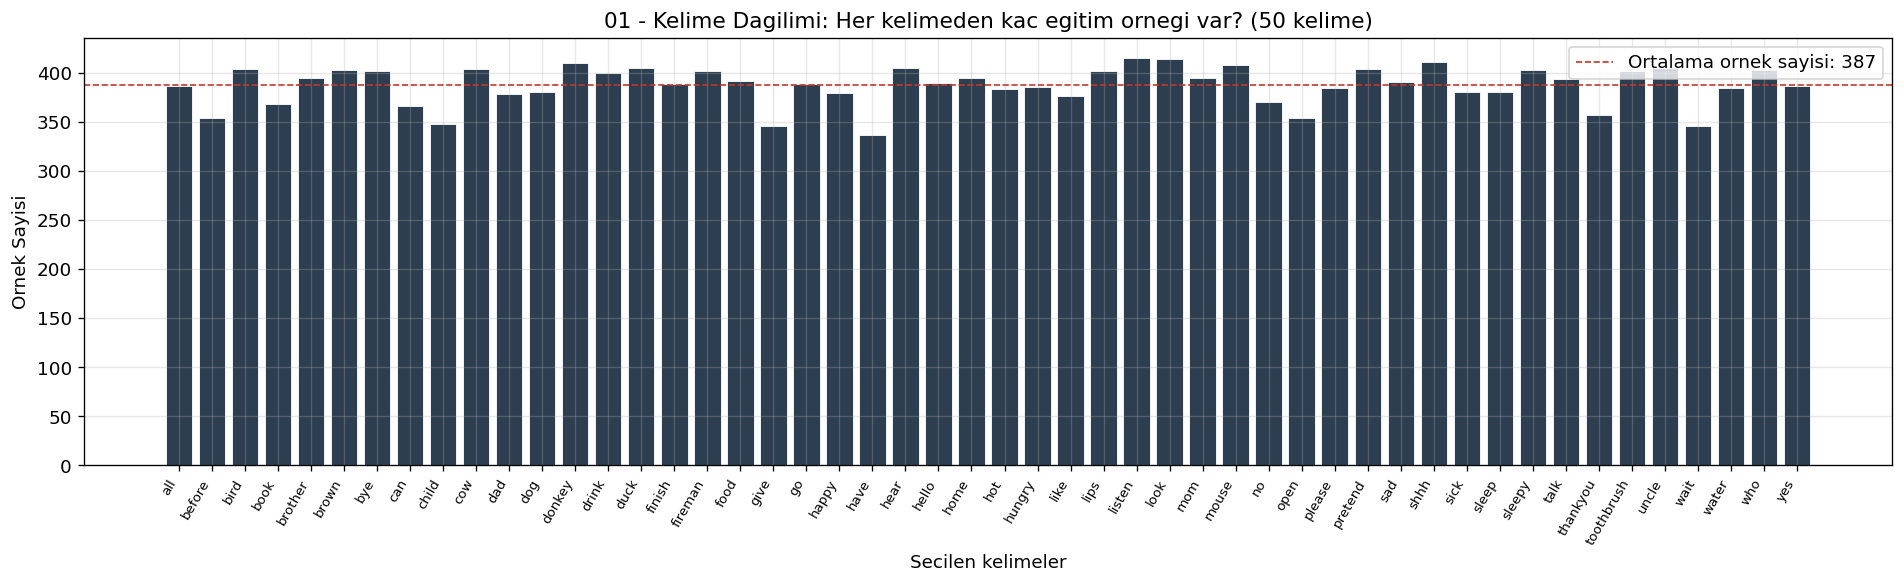

[Gorsel] 01_kelime_dagilimi.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/01_kelime_dagilimi.png yoluna yazildi.

01 - KELIME DAGILIMI GRAFIGI YORUMU
------------------------------------------------------------------------
Ortalama ornek sayisi: 387
En az ornek: 337 (have)
En cok ornek: 415 (listen)
Anlam: Cubuklar birbirine yakin kaldikca veri dengesi daha iyidir.
Not: Kucuk dengesizlikler Focal Loss ile azaltilacak; cok dusuk kelimeler ise zor sinif olabilir.


In [3]:
# ---------------------------------------------------------------------------
# KELIME DAGILIMI GORSELI
# Her kelime icin kac ornek oldugunu gosterir.
# Dengesiz dagilim varsa Focal Loss ile telafi edilecek.
# ---------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(16, 5))
counts = filtered_df["sign"].value_counts().reindex(SELECTED_WORDS)
colors = ["#2c3e50"] * len(counts)
ax.bar(range(len(counts)), counts.values, color=colors, edgecolor="white", linewidth=0.5)
ax.set_xticks(range(len(counts)))
ax.set_xticklabels(counts.index, rotation=60, ha="right", fontsize=8)
ax.set_xlabel("Secilen kelimeler")
ax.set_ylabel("Ornek Sayisi")
ax.set_title(f"01 - Kelime Dagilimi: Her kelimeden kac egitim ornegi var? ({NUM_CLASSES} kelime)")
ax.axhline(y=counts.mean(), color="#c0392b", linestyle="--", linewidth=1,
           label=f"Ortalama ornek sayisi: {counts.mean():.0f}")
ax.legend()
plt.tight_layout()
save_figure(fig, "01_kelime_dagilimi.png")

print("\n01 - KELIME DAGILIMI GRAFIGI YORUMU")
print("-" * 72)
print(f"Ortalama ornek sayisi: {counts.mean():.0f}")
print(f"En az ornek: {counts.min()} ({counts.idxmin()})")
print(f"En cok ornek: {counts.max()} ({counts.idxmax()})")
print("Anlam: Cubuklar birbirine yakin kaldikca veri dengesi daha iyidir.")
print("Not: Kucuk dengesizlikler Focal Loss ile azaltilacak; cok dusuk kelimeler ise zor sinif olabilir.")


## Veri Formati ve On-Isleme

Google ASL Signs veri setinde her video parquet dosyasi olarak gelir. Parquet dosyalari long format kullanir: her satir belirli bir frame, landmark tipi, landmark indeksi ve x/y/z koordinatini tasir.

| Alan | Anlam |
|---|---|
| frame | Video icindeki zaman adimi |
| type | face, pose, right_hand veya left_hand |
| landmark_index | MediaPipe landmark numarasi |
| x, y, z | Normalize koordinatlar |

MediaPipe Holistic toplam 543 landmark uretir. Bu notebook 107 landmark secer: 21 sag el, 21 sol el, 40 yuz ve 25 govde noktasi. Boylece her frame 107 x 3 = 321D ham vektore donusur. El landmarklari isaretin ana bilgisini tasir; yuz ve govde referanslari ise elin agiz, burun, alin ve omuzlara gore konumunu anlamak icin kullanilir.

On-isleme adimlari sunlardir:

| Adim | Neden Gerekli | Referans Notu |
|---|---|---|
| Eksik frame interpolasyonu | Kisa landmark kopmalarini yumusatmak | PeerJ 2024 |
| Omuz/govde normalizasyonu | Kisi boyu ve kamera uzakligi etkisini azaltmak | Roh et al. 2024 |
| Bos frame temizligi | Tamamen anlamsiz girdileri egitimden cikarmak | Veri kalitesi kontrolu |
| Pad veya truncate | Modelin sabit uzunlukta sekans almasini saglamak | Deney tasarimi |

Bu bolumdeki fonksiyonlar sonraki feature ve model deneylerinin temelidir. Bu nedenle mevcut yukleme ve normalizasyon mantigi korunur.


In [4]:
# ---------------------------------------------------------------------------
# PARQUET YUKLEME FONKSIYONLARI
#
# Google ASL Signs veri setinde her video parquet dosyası olarak saklanır.
# Parquet, büyük tabloları hızlı okuyup yazmak için kullanılan sıkıştırılmış bir veri formatıdır.
# Bu dosyalarda veri genellikle long format gelir:
#   frame | row_id | type | landmark_index | x | y | z
#
# Long format şu anlama gelir: Her satır tek bir landmark noktasını anlatır.
# Model ise her frame'i tek satırda görmek ister. Bu yüzden veriyi (T, 321)
# şekline çeviriyoruz. T video frame sayısıdır, 321 ise seçilen 107 landmarkın
# x, y, z koordinatlarıdır.
#
# PERFORMANS: pivot_table ile vektörize yükleme kullanılır.
# Python içindeki çok katmanlı for-loop aynı işi yapabilir ama çok yavaştır.
# pivot_table aynı dönüşümü pandas içinde daha hızlı yaptığı için Kaggle süresini ciddi azaltır.
# ---------------------------------------------------------------------------

def build_target_columns():
    """Wide format için beklenen sütun isimlerini üretir.

    Normal Kaggle verisi long format gelir. Yine de farklı bir kaynakta wide format
    görülebilir. Wide formatta her landmark koordinatı ayrı sütun olarak durur.
    Bu fonksiyon, böyle bir durumda okunması gereken x/y/z sütun adlarını hazırlar.
    """
    target_columns = []
    body_part_specs = [
        ("right_hand", list(range(NUM_RIGHT))),
        ("left_hand", list(range(NUM_LEFT))),
        ("face", FACE_INDICES),
        ("pose", POSE_INDICES),
    ]
    for body_part_name, landmark_indices in body_part_specs:
        for landmark_index in landmark_indices:
            target_columns.extend([
                f"x_{body_part_name}_{landmark_index}",
                f"y_{body_part_name}_{landmark_index}",
                f"z_{body_part_name}_{landmark_index}",
            ])
    return target_columns


TARGET_COLS = build_target_columns()


def normalize_shoulders(frame_data):
    """Omuz-merkezli normalizasyon uygular.

    Normalizasyon, farklı kişilerin ve kamera uzaklıklarının etkisini azaltmak için
    sayıları ortak bir ölçeğe getirme işlemidir. Bu fonksiyonda iki omuzun ortası
    merkez kabul edilir ve tüm görünür landmarklar omuz genişliğine bölünür.

    Sonuç: Kullanıcı kameraya biraz yakın veya uzak dursa bile model daha benzer
    sayılar görür. Böylece model kişinin boyunu veya kadrajdaki yerini değil,
    işaretin göreli şeklini öğrenmeye daha çok odaklanır.
    """
    normalized_frame = frame_data.copy()
    pose_start_index = (NUM_RIGHT + NUM_LEFT + NUM_FACE) * 3

    # Omuz landmark'lari pose index 11 ve 12'dir.
    # Bu iki nokta varsa vucut olcegini guvenilir sekilde hesaplayabiliriz.
    if 11 in POSE_INDICES and 12 in POSE_INDICES:
        left_shoulder_position = POSE_INDICES.index(11)
        right_shoulder_position = POSE_INDICES.index(12)
        left_shoulder = normalized_frame[
            pose_start_index + left_shoulder_position*3 : pose_start_index + left_shoulder_position*3 + 3
        ]
        right_shoulder = normalized_frame[
            pose_start_index + right_shoulder_position*3 : pose_start_index + right_shoulder_position*3 + 3
        ]

        if np.any(left_shoulder != 0) and np.any(right_shoulder != 0):
            shoulder_center = (left_shoulder + right_shoulder) / 2.0
            shoulder_width = np.linalg.norm(left_shoulder - right_shoulder)
            if shoulder_width > 1e-6:
                landmarks_3d = normalized_frame.reshape(-1, 3)
                visible_landmarks = np.any(landmarks_3d != 0, axis=1)
                landmarks_3d[visible_landmarks] = (
                    landmarks_3d[visible_landmarks] - shoulder_center
                ) / shoulder_width
                return landmarks_3d.flatten().astype(np.float32)

    # Fallback: omuzlar bulunamazsa basit min-max normalizasyon kullanilir.
    # Bu ana yol degil, sadece veri bozuksa notebook'un tamamen kirilmasini engeller.
    nonzero_values = normalized_frame[normalized_frame != 0]
    if len(nonzero_values) > 0:
        min_value, max_value = nonzero_values.min(), nonzero_values.max()
        value_range = max_value - min_value
        if value_range > 1e-6:
            normalized_frame = np.where(
                normalized_frame == 0,
                0.0,
                (normalized_frame - min_value) / value_range,
            )
    return normalized_frame.astype(np.float32)


def _load_long_format_fast(df):
    """Long format parquet verisini frame bazlı matrise çevirir.

    Long formatta her satır tek bir landmark noktasını taşır. Model için bu yapı
    kullanışlı değildir; model her frame için tek bir sayısal vektör bekler.

    Bu fonksiyonun yaptığı dönüşüm:
    - Aynı frame'e ait landmark satırlarını bir araya getirir.
    - Sadece projede kullanılacak el, yüz ve gövde noktalarını seçer.
    - Sonuçta (T, 321) şeklinde bir numpy array üretir.

    T, videodaki frame sayısıdır. 321 ise 107 landmark * 3 koordinattır.
    pivot_table kullanılmasının sebebi hızdır; pandas bu tablo dönüşümünü Python
    döngülerinden çok daha verimli yapar.
    """
    frames = sorted(df["frame"].unique())
    if len(frames) < 5:
        return None

    frame_count = len(frames)
    landmark_matrix = np.full((frame_count, NUM_TOTAL), np.nan, dtype=np.float32)
    frame_to_row = {frame_number: row_index for row_index, frame_number in enumerate(frames)}

    column_start = 0
    body_part_specs = [
        ("right_hand", NUM_RIGHT, list(range(NUM_RIGHT))),
        ("left_hand", NUM_LEFT, list(range(NUM_LEFT))),
        ("face", NUM_FACE, FACE_INDICES),
        ("pose", NUM_POSE, POSE_INDICES),
    ]
    for body_part_name, landmark_count, landmark_indices in body_part_specs:
        body_part_df = df[df["type"] == body_part_name]
        if body_part_df.empty:
            column_start += landmark_count * 3
            continue

        # pivot: index=frame, columns=landmark_index, values=x/y/z.
        # Her koordinat ayri pivot edilir; sonra hedef 321D matrise yazilir.
        for coordinate_offset, coordinate_name in enumerate(["x", "y", "z"]):
            pivot_table = body_part_df.pivot_table(
                index="frame", columns="landmark_index",
                values=coordinate_name, aggfunc="first",
            )
            for local_landmark_index, landmark_index in enumerate(landmark_indices):
                if landmark_index in pivot_table.columns:
                    coordinate_values = pivot_table[landmark_index]
                    for frame_number, coordinate_value in coordinate_values.items():
                        if frame_number in frame_to_row and not np.isnan(coordinate_value):
                            row_index = frame_to_row[frame_number]
                            column_index = column_start + local_landmark_index*3 + coordinate_offset
                            landmark_matrix[row_index, column_index] = coordinate_value
        column_start += landmark_count * 3

    return landmark_matrix


def load_single_parquet(row, data_dir=None):
    """Tek parquet dosyasini yukle ve (T, 321) numpy array'e donustur.

    Adimlar:
    1. Parquet oku
    2. Format tespiti (long / wide)
    3. Eksik degerleri linear interpolation + ffill/bfill ile doldur (PeerJ 2024)
    4. Sifir frame'leri kaldir
    5. Her frame'i omuz-merkezli normalize et
    """
    if data_dir is None:
        data_dir = DATA_DIR
    try:
        path = data_dir / row["path"]
        if not path.exists():
            return None

        df = pd.read_parquet(path)

        # --- Format Tespiti ---
        if "type" in df.columns and "landmark_index" in df.columns:
            landmark_sequence = _load_long_format_fast(df)
            if landmark_sequence is None:
                return None
        elif any(c in df.columns for c in ["x_right_hand_0", "x_left_hand_0"]):
            # Wide format yolu.
            # Normal Kaggle formatında beklenmez; farklı veri kaynağı gelirse kodun bozulmaması için tutulur.
            available_columns = [c for c in TARGET_COLS if c in df.columns]
            if len(available_columns) < NUM_TOTAL * 0.3:
                return None
            landmark_sequence = np.full((len(df), NUM_TOTAL), np.nan, dtype=np.float32)
            for column_index, column_name in enumerate(TARGET_COLS):
                if column_name in df.columns:
                    landmark_sequence[:, column_index] = df[column_name].values
        else:
            return None

        # --- NaN Doldurma ---
        # NaN, "burada sayı yok" anlamına gelir. MediaPipe eli, yüzü veya gövdeyi
        # kısa süreli kaybettiğinde bazı koordinatlar NaN olabilir.
        #
        # Lineer interpolasyon eksik noktayı önceki ve sonraki frame arasından tahmin eder.
        # Örneğin 10. frame ve 12. frame varsa, 11. frame aradaki geçişe göre doldurulur.
        # Bu yöntem kısa süreli kopmaları yumuşatır; uzun süreli kayıpları tamamen çözmez.
        #
        # ffill/bfill videonun başında veya sonunda kalan boşlukları en yakın geçerli
        # değerle tamamlar. Böylece model NaN içeren bir giriş görmez.
        landmark_df = pd.DataFrame(landmark_sequence)
        landmark_df = landmark_df.interpolate(method="linear", limit_direction="both")
        landmark_df = landmark_df.ffill().bfill()
        landmark_sequence = landmark_df.values.astype(np.float32)
        landmark_sequence = np.nan_to_num(landmark_sequence, nan=0.0)

        # Sifir frame'leri kaldir.
        # Tamamen sifir frame genellikle landmark bulunamadigi anlamina gelir.
        # Bu frame'leri tutmak modele "bos goruntu" ogretebilir, bu nedenle temizlenir.
        valid_frame_mask = np.any(landmark_sequence != 0, axis=1)
        landmark_sequence = landmark_sequence[valid_frame_mask]

        if len(landmark_sequence) < 5:
            return None

        # Her frame'i omuz-merkezli normalize et.
        # Buradaki amaç mutlak ekran koordinatlarını azaltmaktır. Mutlak koordinat,
        # elin ekranda nerede durduğunu söyler; fakat işaret için daha önemli olan
        # elin vücuda göre konumu, şekli ve hareketidir.
        #
        # Bu nedenle model "kişi kameraya yakın mı?" bilgisini ezberlemek yerine
        # "işaret nasıl yapılıyor?" bilgisini öğrenmeye yönlendirilir.
        normalized_sequence = np.zeros_like(landmark_sequence)
        for frame_index in range(len(landmark_sequence)):
            if np.any(landmark_sequence[frame_index] != 0):
                normalized_sequence[frame_index] = normalize_shoulders(landmark_sequence[frame_index])

        # Cikti sekli: T frame, her frame 321 sayi.
        # Sonraki feature engineering adimi bu diziyi 168D compact feature'a cevirir.
        return normalized_sequence  # (T, 321)
    except Exception:
        return None


def pad_or_truncate(sequence, target_len):
    """Sekansi hedef uzunluga getir.

    - Video hedef uzunluktan uzunsa esit aralikli frame secilir.
    - Video hedef uzunluktan kisaysa sona sifir frame eklenir.

    Bu fonksiyon modelin her videoda ayni sekil input almasini saglar.
    """
    sequence_len = len(sequence)
    if sequence_len == target_len:
        return sequence
    elif sequence_len > target_len:
        selected_indices = np.linspace(0, sequence_len - 1, target_len, dtype=int)
        return sequence[selected_indices]
    else:
        padding = np.zeros((target_len - sequence_len, sequence.shape[1]), dtype=np.float32)
        return np.vstack([sequence, padding])


print("Parquet okuma ve on-isleme fonksiyonlari hazir.")
print("Anlam: Her video dosyasi okunacak, eksik landmarklar doldurulacak ve omuz merkezli normalize edilecek.")


Parquet okuma ve on-isleme fonksiyonlari hazir.
Anlam: Her video dosyasi okunacak, eksik landmarklar doldurulacak ve omuz merkezli normalize edilecek.


In [5]:
# ---------------------------------------------------------------------------
# VERI YUKLEME (PARALEL)
#
# Bu hücre train, validation ve test bölümlerindeki parquet dosyalarını okur.
# Paralel yükleme kullanılır: aynı anda birden fazla dosya okunur.
# Bu yöntem tek tek okumaya göre daha hızlıdır, çünkü parquet okuma CPU ağırlıklı bir iştir.
#
# Burada henüz videolar 30 veya 45 frame'e sabitlenmez. Sekanslar önce kendi
# doğal uzunluklarıyla saklanır; frame seçimi sonraki deney bölümünde yapılır.
# ---------------------------------------------------------------------------

from multiprocessing import Pool, cpu_count

NUM_WORKERS = min(4, cpu_count())


def _load_one(load_args):
    """Tek dosya yukleme (multiprocessing uyumlu)."""
    row_dict, data_dir_str = load_args
    landmark_sequence = load_single_parquet({"path": row_dict["path"]}, Path(data_dir_str))
    if landmark_sequence is not None and len(landmark_sequence) >= 5:
        return (landmark_sequence, row_dict["label"])
    return None


def load_split(df_split, name=""):
    """Bir split'in tum verisini paralel yukle."""
    load_args = [({"path": row["path"], "label": row["label"]}, str(DATA_DIR))
                 for _, row in df_split.iterrows()]

    print(f"{name}: {len(load_args):,} dosya okunuyor ({NUM_WORKERS} worker)...", end=" ")
    t0 = time.time()

    # Parquet okuma CPU-agir bir is oldugu icin multiprocessing kullanilir.
    # Her worker farkli dosyalari okur; boylece binlerce video sirayla beklemek zorunda kalmaz.
    # Burada model egitimi yapilmiyor, sadece ham dosyalar temiz numpy dizilerine cevriliyor.
    with Pool(NUM_WORKERS) as pool:
        load_results = pool.map(_load_one, load_args)

    # Okunamayan, cok kisa veya tamamen bos dosyalar None doner.
    # Bunlar egitime alinmaz; boylece model bozuk girdi gormez.
    valid_results = [result for result in load_results if result is not None]
    sequences = [result[0] for result in valid_results]
    labels = np.array([result[1] for result in valid_results], dtype=np.int64)

    skipped_count = len(load_args) - len(valid_results)
    elapsed = time.time() - t0
    print(f"{len(sequences):,} gecerli video yuklendi, {skipped_count:,} dosya atlandi "
          f"(%{skipped_count/max(len(load_args),1)*100:.1f}), sure: {elapsed:.0f} sn")
    return sequences, labels


print("=" * 72)
print("HAM VIDEO DOSYALARI YUKLENIYOR")
print("=" * 72)
print(f"Paralel worker sayisi: {NUM_WORKERS}")
print("Yorum: Bu adim Parquet dosyalarini landmark dizilerine cevirir; atlanan dosyalar okunamayan veya cok kisa kayitlardir.\n")
t_start = time.time()

train_seqs_raw, train_labels = load_split(train_split, "Train")
val_seqs_raw, val_labels = load_split(val_split, "Val")
test_seqs_raw, test_labels = load_split(test_split, "Test")

# Parquet yukleme sonrasi class coverage tekrar kontrol edilir.
# Split dataframe tam olsa bile bozuk/atlanan dosyalar bir sinifi tamamen silebilir.
for split_name, labels_array in [("train", train_labels), ("val", val_labels), ("test", test_labels)]:
    present_classes = set(np.unique(labels_array))
    missing_classes = set(range(NUM_CLASSES)) - present_classes
    assert len(missing_classes) == 0,         f"{split_name} split'te parquet yukleme sonrasi {len(missing_classes)} sinif eksik: {missing_classes}"
    print(f"  {split_name}: {len(present_classes)}/{NUM_CLASSES} sinif mevcut")
print("Yorum: Yukleme sonrasi da 50 sinif korunuyor; deneyler tam class coverage ile baslayabilir.")

total_time = time.time() - t_start
print("\nYUKLEME OZETI")
print("-" * 72)
print(f"Toplam sure: {total_time/60:.1f} dakika")
print(f"Toplam gecerli video: {len(train_seqs_raw) + len(val_seqs_raw) + len(test_seqs_raw):,}")
print("Anlam: Bundan sonraki adimlarda bu temizlenmis landmark dizileri kullanilacak.")

split_lengths = {
    "Train": len(train_seqs_raw),
    "Val": len(val_seqs_raw),
    "Test": len(test_seqs_raw),
}
# Bu kontrol Kaggle run'inda gec fark edilecek buyuk hatalari erkenden yakalar.
# Ornegin veri yolu yanlissa veya split tamamen bos kalirsa sonraki grafik/model
# hucrelerinde anlasilmasi zor hatalar almak yerine burada acik hata aliriz.
empty_splits = [name for name, count in split_lengths.items() if count == 0]
if empty_splits:
    raise RuntimeError(
        "Bos veri bolumu bulundu: " + ", ".join(empty_splits) +
        ". Split veya parquet yukleme adimi kontrol edilmeli."
    )

assert len(train_seqs_raw) == len(train_labels), "Train sekans/label sayisi uyumsuz"
assert len(val_seqs_raw) == len(val_labels), "Val sekans/label sayisi uyumsuz"
assert len(test_seqs_raw) == len(test_labels), "Test sekans/label sayisi uyumsuz"


HAM VIDEO DOSYALARI YUKLENIYOR
Paralel worker sayisi: 4
Yorum: Bu adim Parquet dosyalarini landmark dizilerine cevirir; atlanan dosyalar okunamayan veya cok kisa kayitlardir.

Train: 12,776 dosya okunuyor (4 worker)... 12,723 gecerli video yuklendi, 53 dosya atlandi (%0.4), sure: 501 sn
Val: 2,658 dosya okunuyor (4 worker)... 2,658 gecerli video yuklendi, 0 dosya atlandi (%0.0), sure: 96 sn
Test: 3,923 dosya okunuyor (4 worker)... 3,918 gecerli video yuklendi, 5 dosya atlandi (%0.1), sure: 169 sn
  train: 50/50 sinif mevcut
  val: 50/50 sinif mevcut
  test: 50/50 sinif mevcut
Yorum: Yukleme sonrasi da 50 sinif korunuyor; deneyler tam class coverage ile baslayabilir.

YUKLEME OZETI
------------------------------------------------------------------------
Toplam sure: 12.8 dakika
Toplam gecerli video: 19,299
Anlam: Bundan sonraki adimlarda bu temizlenmis landmark dizileri kullanilacak.


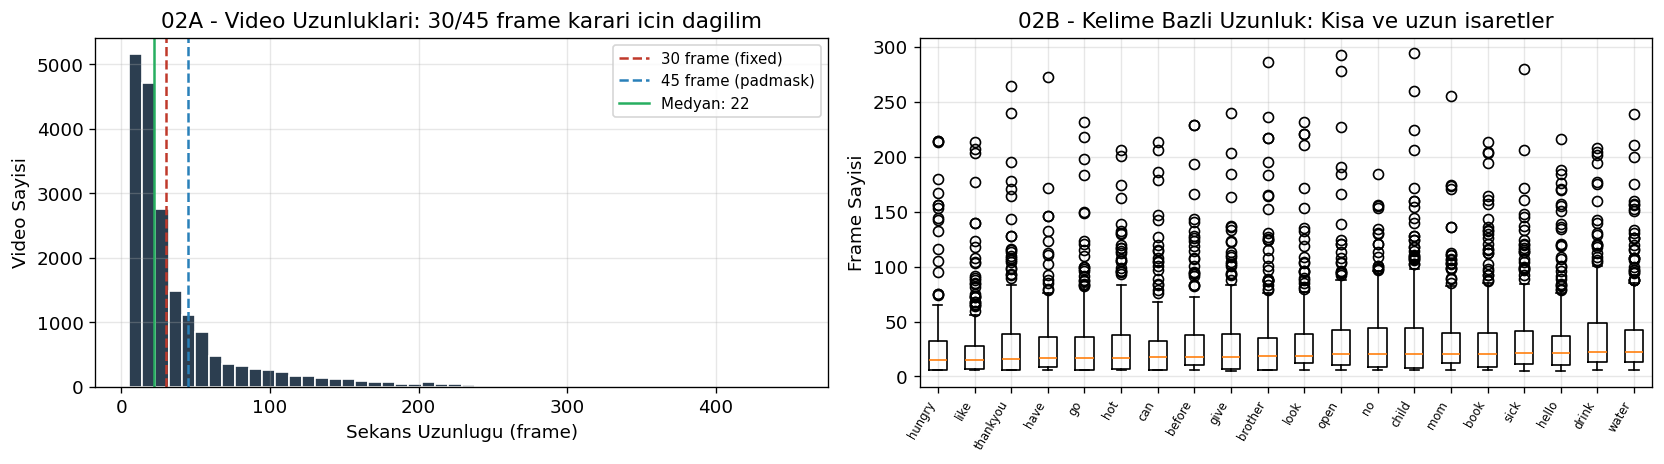

[Gorsel] 02_sekans_uzunluk.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/02_sekans_uzunluk.png yoluna yazildi.

02 - SEKANS UZUNLUK GRAFIGI YORUMU
------------------------------------------------------------------------
En kisa video: 5 frame
En uzun video: 453 frame
Medyan uzunluk: 22 frame
Ortalama uzunluk: 38 frame
Anlam: Bu grafik 30 frame, 45 frame veya motion sampling secimlerinden hangisinin mantikli oldugunu gosterir.
Yorum: Medyan 30 frame'e yakin; fixed30 stratejisi guclu bir baslangic secenegidir.


In [6]:
# ---------------------------------------------------------------------------
# SEKANS UZUNLUK ANALIZI
# Ham sekans uzunluklarinin dagilimini incele.
# Bu bilgi Bolum A (sekans uzunlugu deneyi) icin referans olacak.
# ---------------------------------------------------------------------------

all_lengths = [len(s) for s in train_seqs_raw + val_seqs_raw + test_seqs_raw]
median_len = np.median(all_lengths)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram
axes[0].hist(all_lengths, bins=50, color="#2c3e50", edgecolor="white")
axes[0].axvline(x=30, color="#c0392b", linestyle="--", label="30 frame (fixed)")
axes[0].axvline(x=45, color="#2980b9", linestyle="--", label="45 frame (padmask)")
axes[0].axvline(x=median_len, color="#27ae60", linestyle="-",
                label=f"Medyan: {median_len:.0f}")
axes[0].set_xlabel("Sekans Uzunlugu (frame)")
axes[0].set_ylabel("Video Sayisi")
axes[0].set_title("02A - Video Uzunluklari: 30/45 frame karari icin dagilim")
axes[0].legend(fontsize=9)

# Box plot (kelime bazli, ilk 20 kelime medyana gore)
word_lens = {}
for seq, label in zip(train_seqs_raw, train_labels):
    w = idx_to_word[int(label)]
    word_lens.setdefault(w, []).append(len(seq))

sorted_words = sorted(word_lens.keys(), key=lambda w: np.median(word_lens[w]))[:20]
box_data = [word_lens[w] for w in sorted_words]
axes[1].boxplot(box_data, labels=sorted_words, vert=True)
axes[1].set_xticklabels(sorted_words, rotation=60, ha="right", fontsize=7)
axes[1].set_ylabel("Frame Sayisi")
axes[1].set_title("02B - Kelime Bazli Uzunluk: Kisa ve uzun isaretler")

plt.tight_layout()
save_figure(fig, "02_sekans_uzunluk.png")

print("\n02 - SEKANS UZUNLUK GRAFIGI YORUMU")
print("-" * 72)
print(f"En kisa video: {min(all_lengths)} frame")
print(f"En uzun video: {max(all_lengths)} frame")
print(f"Medyan uzunluk: {median_len:.0f} frame")
print(f"Ortalama uzunluk: {np.mean(all_lengths):.0f} frame")
print("Anlam: Bu grafik 30 frame, 45 frame veya motion sampling secimlerinden hangisinin mantikli oldugunu gosterir.")
if median_len <= 32:
    print("Yorum: Medyan 30 frame'e yakin; fixed30 stratejisi guclu bir baslangic secenegidir.")
elif median_len >= 35:
    print("Yorum: Medyan 35+ oldugu icin padmask45 daha fazla hareket bilgisini koruyabilir.")
else:
    print("Yorum: Medyan orta aralikta; Bolum A deneyleri hangi stratejinin daha iyi oldugunu netlestirecek.")


## Feature Muhendisligi: 6 Aday Temsil

Feature engineering, ham landmark koordinatlarini modelin daha kolay genelleyebilecegi sayisal temsile donusturur. Ham 321D koordinat tek basina elin ekrandaki mutlak yerine fazla baglidir; ayni isaret kamera acisi veya kullanici pozisyonu degistiginde farkli gorunebilir.

Harf modelinde feature engineering cok buyuk fark yaratmisti: ham koordinat yaklasik yuzde 33 seviyesindeyken 93D feature temsil ile yuzde 99.4 seviyesine cikildi. Kelime modelinde de benzer soruyu sistematik olarak test ediyoruz.

| Ad | Boyut | Bilesenler | Hipotez |
|---|---:|---|---|
| 1A_baseline | 321D | Ham koordinat | Alt sinir; model her seyi kendi ogrenir |
| 1B_pw_dom | 444D | Ham + pairwise mesafe + dominant el | Mesafe bilgisi ham veriyi guclendirir |
| 1C_shape | 72D | Iki el sekil + el-yuz iliskisi | Pozisyondan daha bagimsiz temsil yeterli olabilir |
| 1D_shape_motion | 132D | Shape + temporal diff + el-yuz | Sekil ve hareket birlikte daha ayirt edici olabilir |
| 1E_compact | 168D | Dominant el + dominant sekil + el-yuz + dominant hareket | Dengeli, web icin pratik temsil |
| 1F_full | 519D | Ham + pairwise + hareket + el-yuz | Tum bilgiyi vermek daha iyi olabilir |

Bilesen fonksiyonlari el sekli, parmak mesafeleri, elin yuze/govdeye gore konumu ve ardışik frame farklari gibi bilgileri olcer. Bolum A'da bu 6 temsil ayni model ve ayni sekans uzunlugu ile karsilastirilir.


In [7]:
# ---------------------------------------------------------------------------
# FEATURE ENGINEERING (COMPACT 168D)
#
# Feature engineering, ham landmark koordinatlarını model için daha anlamlı
# sayılara dönüştürme işlemidir. Model doğrudan 321D ham koordinatı görmek yerine
# el şekli, elin yüze/gövdeye göre konumu ve hareket bilgisi gibi daha açıklayıcı
# özellikler görür.
#
# Compact 168D yapısı önceki deneylerde en iyi sonuç veren temsil olduğu için kullanılır.
# Bileşenler:
#   - Dominant el landmarkları:    63D  -> Daha güvenilir görünen elin 21 noktası
#   - El şekli özellikleri:        30D  -> Parmak açıklığı, mesafeler, açılar, el kutusu
#   - El-yüz/gövde ilişkileri:     12D  -> Elin burun, ağız ve alın gibi referanslara uzaklığı
#   - Dominant el hareket vektörü: 63D  -> Bir frame'den sonraki frame'e elin değişimi
#   Toplam: 168D
# ---------------------------------------------------------------------------

def extract_hand(frame_321d, hand="right"):
    """321D tek frame içinden sağ veya sol elin 21 noktasını çıkarır.

    Bir elde 21 landmark vardır. Her landmark x, y, z olmak üzere 3 koordinat taşır.
    Bu nedenle tek el 21 * 3 = 63 sayı ile temsil edilir.
    """
    if hand == "right":
        return frame_321d[:63].reshape(21, 3)
    else:
        return frame_321d[63:126].reshape(21, 3)


def safe_norm(vec, axis=-1):
    """Euclidean norm hesaplar ve sıfıra bölme hatasını engeller.

    Norm, bir vektörün uzunluğudur. Örneğin iki nokta arasındaki mesafe norm ile
    hesaplanabilir. Sonuç çok küçükse 1e-8 alt sınırı kullanılır; böylece bölme
    işlemlerinde sonsuz veya NaN değer oluşmaz.
    """
    return np.maximum(np.linalg.norm(vec, axis=axis), 1e-8)


def angle_between_vectors(vector_a, vector_b):
    """Iki vektor arasi aci (radyan).

    Parmak eklemlerindeki bukulme miktarini sayisal ozellige cevirmek icin kullanilir.
    np.clip, yuvarlama hatalari nedeniyle arccos'un -1..1 disi deger almasini engeller.
    """
    cosine_similarity = np.sum(vector_a * vector_b) / (safe_norm(vector_a) * safe_norm(vector_b))
    cosine_similarity = np.clip(cosine_similarity, -1.0, 1.0)
    return np.arccos(cosine_similarity)


def compute_per_frame_shape_features(hand_21x3):
    """Tek elin şekil bilgisini 30 sayılık feature vektörüne çevirir.

    Bu fonksiyon elin ekrandaki mutlak yerinden çok elin kendi şeklini özetler.
    Örneğin parmaklar açık mı, parmak uçları birbirine yakın mı, elin kapladığı
    alan geniş mi gibi sorulara sayısal cevap üretir.

    Çıktı bileşenleri:
      5 fingertip-wrist distance      -> Parmak uçlarının bileğe uzaklığı
      4 adjacent fingertip distance   -> Komşu parmak uçları arasındaki mesafe
      10 pairwise fingertip distance  -> Her parmak ucu çiftinin mesafesi
      5 finger extension flag         -> Parmak açık mı kapalı mı bilgisi
      3 PIP-DIP angle                 -> Parmak eklemlerindeki bükülme açısı
      2 bounding box                  -> Elin genişlik/yükseklik oranı ve alanı
      1 average fingertip distance    -> Parmak uçlarının ortalama uzaklığı
    """
    shape_features = []
    wrist_position = hand_21x3[WRIST]

    # Elin boyutunu orta parmak MCP noktasina gore normalize ediyoruz.
    # Boylece buyuk/kucuk el farki modele dogrudan yansimaz.
    palm_size = safe_norm(hand_21x3[9] - wrist_position)  # wrist->middle_mcp

    # Bilegi merkez kabul ediyoruz. Artik koordinatlar "ekrandaki mutlak yer"
    # degil, elin kendi icindeki goreli konumlari temsil eder.
    normalized_hand = (hand_21x3 - wrist_position) / palm_size

    # 5 fingertip distances from wrist (normalized).
    # Parmak ucunun bilege uzakligi parmagin acik/kapali durumunu anlatmaya yardim eder.
    for fingertip_index in FINGER_TIPS:
        shape_features.append(safe_norm(normalized_hand[fingertip_index]))

    # 4 adjacent fingertip distances.
    # Yanyana parmaklar birbirinden ne kadar ayrilmis, bunu olcer.
    for fingertip_position in range(len(FINGER_TIPS) - 1):
        current_tip = FINGER_TIPS[fingertip_position]
        next_tip = FINGER_TIPS[fingertip_position + 1]
        shape_features.append(safe_norm(normalized_hand[current_tip] - normalized_hand[next_tip]))

    # 10 pairwise fingertip distances.
    # Bes parmak ucunun her ikili mesafesi el sekli icin guclu bir ozettir.
    for first_tip_position in range(len(FINGER_TIPS)):
        for second_tip_position in range(first_tip_position + 1, len(FINGER_TIPS)):
            first_tip = FINGER_TIPS[first_tip_position]
            second_tip = FINGER_TIPS[second_tip_position]
            shape_features.append(safe_norm(normalized_hand[first_tip] - normalized_hand[second_tip]))

    # 5 finger extension flags (tip_dist > mcp_dist ise parmak acik).
    # Bu binary bilgi modele "parmak acik mi?" sorusunun basit cevabini verir.
    for fingertip_index, mcp_index in zip(FINGER_TIPS, FINGER_MCPS):
        fingertip_distance = safe_norm(normalized_hand[fingertip_index])
        mcp_distance = safe_norm(normalized_hand[mcp_index])
        shape_features.append(1.0 if fingertip_distance > mcp_distance else 0.0)

    # 3 PIP-DIP angles (orta parmak eklemleri: index, middle, ring).
    # Aci bilgisi, parmak bukulmesini mesafeden farkli bir yolla anlatir.
    for finger_position in [1, 2, 3]:
        mcp_index = FINGER_MCPS[finger_position]
        pip_index = FINGER_PIPS[finger_position]
        dip_index = FINGER_DIPS[finger_position]
        vector_mcp_to_pip = normalized_hand[mcp_index] - normalized_hand[pip_index]
        vector_dip_to_pip = normalized_hand[dip_index] - normalized_hand[pip_index]
        shape_features.append(angle_between_vectors(vector_mcp_to_pip, vector_dip_to_pip))

    # 2 bounding box features.
    # Elin ekrandaki goreli kutusu: genis mi/dar mi, kapladigi alan ne kadar?
    visible_points = normalized_hand[np.any(normalized_hand != 0, axis=1)]
    if len(visible_points) > 2:
        bbox_width_height = visible_points.max(axis=0)[:2] - visible_points.min(axis=0)[:2]
        bbox_aspect_ratio = bbox_width_height[0] / max(bbox_width_height[1], 1e-8)
        bbox_area = bbox_width_height[0] * bbox_width_height[1]
        shape_features.extend([bbox_aspect_ratio, bbox_area])
    else:
        shape_features.extend([0.0, 0.0])

    # 1 average fingertip distance.
    # Parmaklar genel olarak bilekten ne kadar uzak, tek sayiyla ozetlenir.
    avg_fingertip_distance = np.mean([safe_norm(normalized_hand[t]) for t in FINGER_TIPS])
    shape_features.append(avg_fingertip_distance)

    return np.array(shape_features, dtype=np.float32)


def compute_dominant_hand_features(seq_321d):
    """Videodaki daha güvenilir eli seçer ve (T, 63) olarak döndürür.

    Dominant el burada sağlak/solak anlamında değil, MediaPipe tarafından daha
    iyi görülen el anlamındadır. Bir elde çok fazla sıfır varsa bu genellikle o
    elin bulunamadığını gösterir. Daha az sıfır içeren el daha güvenilir kabul edilir.

    Sol el seçilirse x koordinatları ters çevrilir. Bu işlem aynalama olarak
    düşünülebilir: Model sağ ve sol el farkına değil, işaretin şekline odaklanır.
    """
    right_hand = seq_321d[:, :63]
    left_hand = seq_321d[:, 63:126]

    # MediaPipe eli bulamazsa ilgili koordinatlar genellikle 0 kalir.
    # Hangi elde daha az sifir varsa o el daha iyi gorulmus kabul edilir.
    right_zero = (right_hand == 0).mean()
    left_zero = (left_hand == 0).mean()
    if right_zero <= left_zero:
        return right_hand
    else:
        mirrored = left_hand.copy()
        # Sol eli sag el gibi yorumlayabilmek icin x eksenini ceviriyoruz.
        # Bu, modelin "sag/sol el" farkina degil, hareketin sekline odaklanmasini saglar.
        mirrored[:, 0::3] = -mirrored[:, 0::3]  # x-koordinatlarini ters cevir
        return mirrored


def compute_hand_body_relations(seq_321d):
    """El-yuz/govde iliskileri. Cikti: (T, 12) = 6D x 2 el.

    Her el icin 6 olcum:
      - Index tip -> burun mesafesi
      - Index tip -> agiz mesafesi
      - Index tip -> alin mesafesi
      - Wrist    -> burun mesafesi
      - Index tip y - burun y (dikey offset)
      - Index tip -> wrist mesafesi (el acikligi)
    """
    frame_count = seq_321d.shape[0]
    relation_features = np.zeros((frame_count, 12), dtype=np.float32)

    # Ilk 126 deger iki ele aittir: sag el 63D + sol el 63D.
    # Bu nedenle yuz landmarklari 126. indeksten baslar.
    face_start = 126  # right(63) + left(63)

    # Yuzde anlamli referans noktalarini seciyoruz.
    # Burun/agiz/alin mesafeleri, bazi isaretlerde elin nereye yaklastigini anlatir.
    nose_index = FACE_INDICES.index(1) if 1 in FACE_INDICES else 0
    mouth_index = FACE_INDICES.index(13) if 13 in FACE_INDICES else 5
    forehead_index = FACE_INDICES.index(168) if 168 in FACE_INDICES else 10

    for frame_index in range(frame_count):
        for hand_number in range(2):
            hand_start = hand_number * 63
            wrist_position = seq_321d[frame_index, hand_start:hand_start+3]
            index_tip_position = seq_321d[frame_index, hand_start + 8*3 : hand_start + 8*3 + 3]
            nose_position = seq_321d[frame_index, face_start + nose_index*3 : face_start + nose_index*3 + 3]
            mouth_position = seq_321d[frame_index, face_start + mouth_index*3 : face_start + mouth_index*3 + 3]
            forehead_position = seq_321d[frame_index, face_start + forehead_index*3 : face_start + forehead_index*3 + 3]

            # Her el icin 6 sayi yazilir. Sag el 0-5, sol el 6-11 araligina gider.
            feature_start = hand_number * 6
            relation_features[frame_index, feature_start + 0] = safe_norm(index_tip_position - nose_position)
            relation_features[frame_index, feature_start + 1] = safe_norm(index_tip_position - mouth_position)
            relation_features[frame_index, feature_start + 2] = safe_norm(index_tip_position - forehead_position)
            relation_features[frame_index, feature_start + 3] = safe_norm(wrist_position - nose_position)
            relation_features[frame_index, feature_start + 4] = (
                index_tip_position[1] - nose_position[1] if len(index_tip_position) >= 2 else 0.0
            )
            relation_features[frame_index, feature_start + 5] = safe_norm(index_tip_position - wrist_position)
    return relation_features


def build_compact_features(seq_321d):
    """Ham 321D landmark dizisini compact 168D feature dizisine çevirir.

    Bu fonksiyon pad veya truncate yapmaz; yani videonun frame sayısını değiştirmez.
    Sadece her frame'in temsilini değiştirir: ham koordinatlar yerine el şekli,
    el-yüz ilişkisi ve hareket bilgisi çıkarılır.

    Çıktı şekli (T, 168) olur. T videodaki frame sayısıdır.
    """
    frame_count = seq_321d.shape[0]

    # 1. Dominant hand / dominant el (63D)
    # Her frame'de daha guvenilir gorunen eli temel aliyoruz.
    # Bu, tek elin kayboldugu frame'lerde gurultuyu azaltir.
    dominant_hand_features = compute_dominant_hand_features(seq_321d)

    # 2. Per-frame shape features (30D per frame)
    # Ham 21 nokta yerine parmak mesafeleri, acilar ve bbox gibi okunabilir
    # el sekli ozellikleri cikarilir. Bu ozellikler "el acik mi/kapali mi" gibi
    # sorulara sayisal cevap verir.
    dominant_hand_3d = dominant_hand_features.reshape(frame_count, 21, 3)
    hand_shape_features = np.array([
        compute_per_frame_shape_features(dominant_hand_3d[frame_index])
        for frame_index in range(frame_count)
    ])

    # 3. Hand-body relations (12D per frame)
    # Elin burun/agiz/alin gibi referanslara uzakligi, kelime ayrimi icin yardimcidir.
    # Ornek: bazi isaretlerde elin agza veya yuze yakinligi anlam tasir.
    hand_body_relation_features = compute_hand_body_relations(seq_321d)

    # 4. Dominant hand motion (63D per frame, ilk frame = 0)
    # Kelime tanimada hareket cok onemlidir. Bu nedenle her frame'in bir onceki
    # frame'e gore ne kadar degistigini de modele veriyoruz.
    dominant_hand_motion = np.zeros_like(dominant_hand_features)
    dominant_hand_motion[1:] = dominant_hand_features[1:] - dominant_hand_features[:-1]

    # Birlestir: 63 + 30 + 12 + 63 = 168
    compact_features = np.hstack([
        dominant_hand_features,
        hand_shape_features,
        hand_body_relation_features,
        dominant_hand_motion,
    ])
    assert compact_features.shape[1] == 168, f"Feature dim 168 olmali, su an {compact_features.shape[1]}"
    return compact_features.astype(np.float32)


def compute_sequence_shape_features(sequence_321d):
    """Iki elin sekil ozelliklerini tum sekans icin hesaplar. Cikti: (T, 60).

    Her frame'de sag ve sol el ayrilir. Her el icin 30D shape feature uretilir
    ve iki el yan yana eklenir. Bu temsil elin ekrandaki mutlak konumundan cok
    parmaklarin birbirine gore durusunu anlatir.
    """
    frame_count = sequence_321d.shape[0]
    shape_features = np.zeros((frame_count, 60), dtype=np.float32)
    for frame_index in range(frame_count):
        right_hand = extract_hand(sequence_321d[frame_index], "right")
        left_hand = extract_hand(sequence_321d[frame_index], "left")
        shape_features[frame_index, :30] = compute_per_frame_shape_features(right_hand)
        shape_features[frame_index, 30:] = compute_per_frame_shape_features(left_hand)
    return shape_features


def compute_pairwise_distances(sequence_321d):
    """El landmark'lari arasi mesafeleri hesaplar. Cikti: (T, 60).

    Her el icin 30 mesafe uretilir: parmak ucu-bilek, parmak ucu-avuc ici,
    parmak ucu ciftleri, MCP komsuluklari ve bazi capraz parmak mesafeleri.
    Mesafe bilgisi koordinat konumundan daha kararlı bir el sekli ozeti verir.
    """
    frame_count = sequence_321d.shape[0]
    pairwise_features = np.zeros((frame_count, 60), dtype=np.float32)
    cross_pairs = [(4, 17), (4, 20), (8, 16), (8, 20), (12, 20), (4, 13)]

    for frame_index in range(frame_count):
        for hand_number, hand_name in enumerate(["right", "left"]):
            hand = extract_hand(sequence_321d[frame_index], hand_name)
            distances = []

            for fingertip_index in FINGER_TIPS:
                distances.append(safe_norm(hand[fingertip_index] - hand[WRIST]))

            palm_reference = hand[9]
            for fingertip_index in FINGER_TIPS:
                distances.append(safe_norm(hand[fingertip_index] - palm_reference))

            for first_tip_position in range(len(FINGER_TIPS)):
                for second_tip_position in range(first_tip_position + 1, len(FINGER_TIPS)):
                    first_tip = FINGER_TIPS[first_tip_position]
                    second_tip = FINGER_TIPS[second_tip_position]
                    distances.append(safe_norm(hand[first_tip] - hand[second_tip]))

            for mcp_position in range(len(FINGER_MCPS) - 1):
                current_mcp = FINGER_MCPS[mcp_position]
                next_mcp = FINGER_MCPS[mcp_position + 1]
                distances.append(safe_norm(hand[current_mcp] - hand[next_mcp]))

            for first_index, second_index in cross_pairs:
                distances.append(safe_norm(hand[first_index] - hand[second_index]))

            feature_start = hand_number * 30
            pairwise_features[frame_index, feature_start:feature_start + 30] = distances[:30]
    return pairwise_features


def compute_motion(features_array):
    """Herhangi bir feature dizisinin temporal farkini hesaplar. Cikti ayni boyuttadir.

    Ilk frame icin onceki frame olmadigi icin hareket sifir kabul edilir. Sonraki
    frame'lerde mevcut feature ile bir onceki feature arasindaki fark yazilir.
    Bu bilgi modele isaretin statik sekli kadar hareket yonunu de gosterir.
    """
    motion_features = np.zeros_like(features_array, dtype=np.float32)
    motion_features[1:] = features_array[1:] - features_array[:-1]
    return motion_features


def build_baseline(sequence_321d):
    """Ham koordinat temsilini dondurur. Cikti: (T, 321).

    Bu builder hic feature engineering uygulamaz. Amaci alt sinir olusturmaktir:
    model sadece ham landmark koordinatlarindan ne kadar genelleyebiliyor?
    """
    return sequence_321d.copy().astype(np.float32)


def build_pw_dom(sequence_321d):
    """Ham koordinat, pairwise mesafe ve dominant eli birlestirir. Cikti: (T, 444).

    Ham 321D bilgi korunur. Buna iki el icin 60D mesafe ozeti ve daha guvenilir
    gorunen dominant elin 63D koordinati eklenir. Hipotez: ham veriye geometrik
    mesafe bilgisi eklemek modelin isaret ayrimini kolaylastirir.
    """
    pairwise_features = compute_pairwise_distances(sequence_321d)
    dominant_hand_features = compute_dominant_hand_features(sequence_321d)
    combined_features = np.hstack([sequence_321d, pairwise_features, dominant_hand_features])
    assert combined_features.shape[1] == 444, f"pw_dom 444D olmali, su an {combined_features.shape[1]}"
    return combined_features.astype(np.float32)


def build_shape(sequence_321d):
    """Iki el sekli ve el-yuz/govde iliskisini birlestirir. Cikti: (T, 72).

    Bu temsil ham koordinati atar ve daha pozisyondan bagimsiz ozetler kullanir:
    iki el icin 60D shape feature ve elin yuz/govde referanslarina uzakligini
    anlatan 12D iliski feature'i.
    """
    shape_features = compute_sequence_shape_features(sequence_321d)
    relation_features = compute_hand_body_relations(sequence_321d)
    combined_features = np.hstack([shape_features, relation_features])
    assert combined_features.shape[1] == 72, f"shape 72D olmali, su an {combined_features.shape[1]}"
    return combined_features.astype(np.float32)


def build_shape_motion(sequence_321d):
    """Iki el sekli, shape hareketi ve el-yuz/govde iliskisini birlestirir. Cikti: (T, 132).

    Shape feature statik el durusunu anlatir. Temporal fark ise bu durusun frame'ler
    arasinda nasil degistigini gosterir. Bu nedenle ozellikle hareketli kelimelerde
    shape-only temsile gore daha fazla bilgi tasimasi beklenir.
    """
    shape_features = compute_sequence_shape_features(sequence_321d)
    shape_motion_features = compute_motion(shape_features)
    relation_features = compute_hand_body_relations(sequence_321d)
    combined_features = np.hstack([shape_features, shape_motion_features, relation_features])
    assert combined_features.shape[1] == 132, f"shape_motion 132D olmali, su an {combined_features.shape[1]}"
    return combined_features.astype(np.float32)


def build_full(sequence_321d):
    """Ham koordinat, pairwise mesafe, el hareketi ve el-yuz iliskisini birlestirir. Cikti: (T, 519).

    Bu builder en genis temsildir. Ham 321D korunur, 60D pairwise mesafe eklenir,
    iki elin 126D hareket farki verilir ve 12D el-yuz/govde iliskisi tamamlayici
    bilgi olarak kullanilir. Hipotez: daha cok bilgi daha iyi olabilir; risk ise
    boyut arttikca gurultu ve overfitting ihtimalinin artmasidir.
    """
    pairwise_features = compute_pairwise_distances(sequence_321d)
    hand_motion_features = compute_motion(sequence_321d[:, :126])
    relation_features = compute_hand_body_relations(sequence_321d)
    combined_features = np.hstack([sequence_321d, pairwise_features, hand_motion_features, relation_features])
    assert combined_features.shape[1] == 519, f"full 519D olmali, su an {combined_features.shape[1]}"
    return combined_features.astype(np.float32)


FEATURE_REGISTRY = {
    "1A_baseline": (build_baseline, 321),
    "1B_pw_dom": (build_pw_dom, 444),
    "1C_shape": (build_shape, 72),
    "1D_shape_motion": (build_shape_motion, 132),
    "1E_compact": (build_compact_features, 168),
    "1F_full": (build_full, 519),
}


# Hizli sanity check
_test_frame = np.random.randn(10, NUM_TOTAL).astype(np.float32)
_test_feats = build_compact_features(_test_frame)
assert _test_feats.shape == (10, FEATURE_DIM)
print("=" * 72)
print("FEATURE ENGINEERING HAZIR")
print("=" * 72)
print(f"Cikti boyutu: compact {FEATURE_DIM}D")
print(f"Feature registry: {len(FEATURE_REGISTRY)} aday temsil hazir")
for registry_name, (_, registry_dim) in FEATURE_REGISTRY.items():
    print(f"  {registry_name:<18} {registry_dim:>3}D")
print("Bilesenler: dominant el, iki el sekli, pairwise mesafe, el-yuz/govde iliskisi ve hareket adaylari hazir.")
print("Anlam: Bolum A artik 6 feature temsilini ayni kosullarda karsilastirabilir.")


FEATURE ENGINEERING HAZIR
Cikti boyutu: compact 168D
Feature registry: 6 aday temsil hazir
  1A_baseline        321D
  1B_pw_dom          444D
  1C_shape            72D
  1D_shape_motion    132D
  1E_compact         168D
  1F_full            519D
Bilesenler: dominant el, iki el sekli, pairwise mesafe, el-yuz/govde iliskisi ve hareket adaylari hazir.
Anlam: Bolum A artik 6 feature temsilini ayni kosullarda karsilastirabilir.


## Feature On-Hesaplama Altyapisi

Bu bolum egitimi hizlandirmak icin kullanilir. Model egitimi sirasinda her batch'te feature hesaplamak yerine, tum feature'lar deneyden once bir kez hesaplanir ve numpy array olarak bellekte tutulur.

Onceki akista on-hesaplama sadece compact 168D icin sabitti. Feature ablasyonu eklendigi icin bu fonksiyonlar artik generic calisir: builder fonksiyonu ve feature boyutu parametre olarak verilir.

| Fonksiyon | Ne Yapar | Neden Generic? |
|---|---|---|
| precompute | Ham sekansi feature'a cevirir, pad/truncate yapar | 72D, 168D, 321D, 519D gibi boyutlar desteklenir |
| compute_masks | Padding mask uretir | 45 frame + mask deneyinde kullanilir |
| motion_energy_sample | En hareketli frame'leri secer | Kazanan feature temsiliyle calisir |

Bellek icin 6 feature seti ayni anda tutulmaz. Bolum A'da her temsil sirayla hesaplanir, egitilir ve `del + clear_gpu_memory()` ile temizlenir.


In [8]:
# ---------------------------------------------------------------------------
# FEATURE ON-HESAPLAMA (GENERIC)
#
# Feature hesaplama CPU tarafında pahalıdır. Eğer her batch geldiğinde yeniden
# feature çıkarılırsa GPU modeli eğitmeye hazır olsa bile CPU'yu bekler.
# Bu durumda darboğaz model değil, veri hazırlama olur.
#
# Bu hücre sadece yardımcı fonksiyonları tanımlar. Asıl hesaplama Bolum A'da
# feature ablasyonu için sırayla, Bolum B'de ise kazanan feature için yapılır.
# ---------------------------------------------------------------------------

def precompute(raw_sequences, builder_fn, feature_dim, seq_len, name=""):
    """Tüm videolar için verilen builder ile feature hesaplar ve sabit uzunluğa getirir.

    Her video once `builder_fn` ile feature dizisine cevrilir. Sonra hedef frame
    sayisina gore kisaltilir veya sonuna sifir padding eklenir. Feature boyutu
    parametre olarak verildigi icin ayni fonksiyon 72D shape, 168D compact veya
    519D full temsil icin kullanilabilir.

    Tek bir videoda hata olursa tum deney durdurulmaz. O video icin sifir feature
    kullanilir ve hata sayisi raporlanir. Boylece veri kalitesi izlenebilir.
    """
    precomputed_features = []
    failed_count = 0
    for sequence_index, raw_sequence in enumerate(raw_sequences):
        if (sequence_index + 1) % 1000 == 0:
            print(f"  {name}: {sequence_index+1}/{len(raw_sequences)}", end="\r")
        try:
            features = builder_fn(raw_sequence)
            if features.shape[1] != feature_dim:
                raise ValueError(
                    f"{name} feature boyutu {feature_dim} bekleniyordu, {features.shape[1]} geldi."
                )
            fixed_length_features = pad_or_truncate(features, seq_len)
            precomputed_features.append(fixed_length_features)
        except Exception:
            # Tek bir bozuk video tum notebook'u durdurmasin diye sifir feature kullanilir.
            # Hata sayisi asagida raporlanir; boylece veri kalitesi takip edilebilir.
            failed_count += 1
            precomputed_features.append(np.zeros((seq_len, feature_dim), dtype=np.float32))
    print(f"  {name}: {len(precomputed_features):,} video icin feature hazirlandi         ")
    if failed_count:
        print(f"  UYARI: {name} icinde {failed_count} video feature hatasi nedeniyle sifir feature ile dolduruldu.")
    return np.array(precomputed_features, dtype=np.float32)


def compute_masks(raw_sequences, seq_len):
    """Padding mask oluşturur.

    Padding, kısa videoları hedef uzunluğa tamamlamak için eklenen sıfır frame'lerdir.
    Bu frame'ler gerçek hareket içermez. Mask, hangi frame'in gerçek hangisinin
    padding olduğunu modele bildirir.

    Örnek: video 30 frame, hedef 45 frame ise ilk 30 değer True, son 15 değer
    False olur. Attention kullanan model False frame'leri yok sayar.
    """
    masks = []
    for raw_sequence in raw_sequences:
        real_frame_count = min(len(raw_sequence), seq_len)
        sequence_mask = np.zeros(seq_len, dtype=bool)
        sequence_mask[:real_frame_count] = True
        masks.append(sequence_mask)
    return np.array(masks)


def motion_energy_sample(raw_sequences, builder_fn, feature_dim, target_len=30, name="motion"):
    """Hareket enerjisi yüksek frame'leri seçer.

    Hareket enerjisi, ardışık frame'ler arasında feature temsilinin ne kadar
    değiştiğini gösterir. Büyük değişim olan frame'ler işaretin aktif kısmını
    taşıma ihtimali daha yüksek frame'lerdir.

    Bu yöntem hareketsiz bekleme frame'lerini azaltmayı amaçlar. Seçilen frame'ler
    tekrar zamansal sıraya dizilir; yani hareketin kronolojik akışı bozulmaz.
    """
    sampled_features = []
    failed_count = 0
    for sequence_index, raw_sequence in enumerate(raw_sequences):
        if (sequence_index + 1) % 1000 == 0:
            print(f"  {name}: {sequence_index+1}/{len(raw_sequences)}", end="\r")
        try:
            features = builder_fn(raw_sequence)
            if features.shape[1] != feature_dim:
                raise ValueError(
                    f"{name} feature boyutu {feature_dim} bekleniyordu, {features.shape[1]} geldi."
                )
            frame_count = features.shape[0]
            if frame_count <= target_len:
                fixed_length_features = pad_or_truncate(features, target_len)
            else:
                motion_source = features[:, :min(63, feature_dim)]
                motion_energy = np.zeros(frame_count)
                motion_energy[1:] = np.linalg.norm(motion_source[1:] - motion_source[:-1], axis=1)
                motion_energy[0] = motion_energy[1] if frame_count > 1 else 0

                # En hareketli frame'leri seciyoruz, sonra siraya diziyoruz.
                # np.argsort son target_len frame indeksini verir; np.sort zaman sirasini geri getirir.
                selected_frame_indices = np.sort(np.argsort(motion_energy)[-target_len:])
                fixed_length_features = features[selected_frame_indices]
            sampled_features.append(fixed_length_features)
        except Exception:
            failed_count += 1
            sampled_features.append(np.zeros((target_len, feature_dim), dtype=np.float32))
    print(f"  {name}: {len(sampled_features):,} video icin motion feature hazirlandi         ")
    if failed_count:
        print(f"  UYARI: {name} icinde {failed_count} video motion sampling hatasi nedeniyle sifir feature ile dolduruldu.")
    return np.array(sampled_features, dtype=np.float32)


print("=" * 72)
print("GENERIC FEATURE ON-HESAPLAMA HAZIR")
print("=" * 72)
print("precompute: builder_fn + feature_dim ile calisir; feature ablasyonu icin hazir.")
print("motion_energy_sample: kazanan feature temsilinin boyutuna gore calisir.")
print("Anlam: 6 feature seti ayni anda bellekte tutulmadan sirayla hesaplanabilir.")


GENERIC FEATURE ON-HESAPLAMA HAZIR
precompute: builder_fn + feature_dim ile calisir; feature ablasyonu icin hazir.
motion_energy_sample: kazanan feature temsilinin boyutuna gore calisir.
Anlam: 6 feature seti ayni anda bellekte tutulmadan sirayla hesaplanabilir.


In [9]:
# ---------------------------------------------------------------------------
# FEATURE-UZAYI AUGMENTASYON + DATASET
#
# Augmentasyon, eğitim verisine kontrollü küçük değişiklikler ekleme işlemidir.
# Amaç modeli kandırmak değildir; modelin canlı kamera ortamındaki küçük farklara
# daha dayanıklı olmasını sağlamaktır.
#
# Bu notebook'ta augmentasyon ham landmarklar üzerinde değil, hesaplanmış 168D
# feature'lar üzerinde uygulanır. Bu daha hızlıdır ve eğitim sırasında CPU yükünü azaltır.
#
# Canlı kullanımda kamera titreyebilir, el kısa süre kaybolabilir veya kullanıcı
# işarete biraz erken/geç başlayabilir. Aşağıdaki augmentasyonlar bu durumları
# küçük ölçekte taklit eder.
# ---------------------------------------------------------------------------

def feat_noise(features, std=0.01):
    """Hafif Gaussian gurultu ekle.

    Canli kamerada MediaPipe noktalarinda kucuk titremeler olabilir.
    Bu augmentasyon modele bu kucuk sensor/landmark gurultusune dayaniklilik kazandirir.
    """
    noise = np.random.randn(*features.shape).astype(np.float32) * std
    return features + noise


def feat_time_mask(features, max_len=4):
    """Rastgele bir araliktaki frame'leri sifirla (temporal dropout).

    Web kamerasinda el kisa sureligine kaybolabilir veya frame kalitesi dusebilir.
    Modelin bu kucuk kopmalara dayanmasi icin egitimde bazi frame'ler sifirlanir.
    """
    masked_features = features.copy()
    frame_count = features.shape[0]
    mask_len = np.random.randint(1, max_len + 1)
    start_index = np.random.randint(0, max(1, frame_count - mask_len))
    masked_features[start_index:start_index + mask_len] = 0.0
    return masked_features


def feat_scale(features, lo=0.95, hi=1.05):
    """Hafif global olcekleme (kamera uzakligi varyasyonu)."""
    scale_factor = np.random.uniform(lo, hi)
    return features * scale_factor


def feat_time_warp(features, max_shift=3):
    """Zamansal kaydirma (hareket baslangici varyasyonu).

    Kullanici isarete bazen biraz erken, bazen biraz gec baslayabilir.
    Bu islem sekansi birkac frame kaydirarak modele bu farki gosterir.
    """
    frame_count = features.shape[0]
    shift_amount = np.random.randint(-max_shift, max_shift + 1)
    if shift_amount == 0:
        return features
    shifted_features = np.zeros_like(features)
    if shift_amount > 0:
        shifted_features[shift_amount:] = features[:frame_count - shift_amount]
    else:
        shifted_features[:frame_count + shift_amount] = features[-shift_amount:]
    return shifted_features


def apply_augmentation(features):
    """Augmentasyon zinciri: feature'lari kontrollu sekilde cesitlendirir."""
    # Her augmentasyon belli olasilikla uygulanir.
    # Hepsini her zaman uygulamak veriyi fazla bozabilir; amac modeli zorlamak,
    # ama isaretin anlamini yok etmemektir.
    augmented_features = features
    if np.random.rand() < 0.5:
        augmented_features = feat_noise(augmented_features)
    if np.random.rand() < 0.3:
        augmented_features = feat_time_mask(augmented_features)
    if np.random.rand() < 0.3:
        augmented_features = feat_scale(augmented_features)
    if np.random.rand() < 0.3:
        augmented_features = feat_time_warp(augmented_features)
    return augmented_features


class PrecomputedDataset(Dataset):
    """Önceden hesaplanmış feature'ları PyTorch'a veren dataset sınıfı.

    Dataset, PyTorch'un veri okuma arayüzüdür. Model eğitim sırasında bu sınıftan
    örnek ister. Bu sınıfta feature yeniden hesaplanmaz; hazır numpy array okunur,
    gerekirse augmentasyon uygulanır ve tensor formatına çevrilir.
    """

    def __init__(self, features, labels, masks=None, augment=False):
        self.features = features
        self.labels = labels
        self.masks = masks
        self.augment = augment

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        # DataLoader her batch hazirlarken bu fonksiyonu cagirir.
        # Burada feature yeniden hesaplanmaz; hazir numpy array okunur.
        features = self.features[idx]
        if self.augment:
            features = apply_augmentation(features)

        # PyTorch modeli tensor bekler. Label ise sinif indeksi oldugu icin long tipindedir.
        features_tensor = torch.from_numpy(features.astype(np.float32))
        label_tensor = torch.tensor(int(self.labels[idx]), dtype=torch.long)

        # Mask varsa model forward(features, padding_mask) seklinde calisir.
        # Mask yoksa klasik forward(features) yeterlidir.
        if self.masks is not None:
            mask_tensor = torch.from_numpy(self.masks[idx].astype(np.bool_))
            return features_tensor, mask_tensor, label_tensor
        return features_tensor, label_tensor


class ProgressiveDataset(PrecomputedDataset):
    """Augmentasyonu epoch'a göre açıp kapatabilen dataset sınıfı.

    Final eğitimde model önce temiz veriyi öğrenir. Belirli bir epoch'tan sonra
    augmentasyon açılır ve model küçük kamera/landmark değişimlerine alıştırılır.
    Bu yaklaşıma progressive augmentation denir.
    """

    def __init__(self, features, labels, masks=None):
        super().__init__(features, labels, masks, augment=False)
        self.aug_active = False

    def __getitem__(self, idx):
        # Final egitimde augmentation ilk epochlarda kapali, sonra acik olacak.
        # Egitim dongusu sadece aug_active bayragini degistirir;
        # dataset'i yeniden olusturmaya gerek kalmaz.
        self.augment = self.aug_active
        return super().__getitem__(idx)


print("=" * 72)
print("DATASET VE AUGMENTATION HAZIR")
print("=" * 72)
print("PrecomputedDataset: Hazir feature array'lerini okur; egitim sirasinda tekrar feature hesaplamaz.")
print("ProgressiveDataset: Final egitimde augmentation'i belirli epoch'tan sonra acmak icin kullanilir.")
print("Anlam: Model once temiz veriyi ogrenecek, sonra kontrollu veri cesitleme ile genelleme gucu artirilacak.")


DATASET VE AUGMENTATION HAZIR
PrecomputedDataset: Hazir feature array'lerini okur; egitim sirasinda tekrar feature hesaplamaz.
ProgressiveDataset: Final egitimde augmentation'i belirli epoch'tan sonra acmak icin kullanilir.
Anlam: Model once temiz veriyi ogrenecek, sonra kontrollu veri cesitleme ile genelleme gucu artirilacak.


In [10]:
# ---------------------------------------------------------------------------
# MODEL MIMARILERI
#
# Bu bölümde aynı veri üzerinde dört farklı model denenir.
# Amaç sadece en yüksek skoru bulmak değildir; modelin boyutu, eğitim kararlılığı
# ve web uygulamasında çalıştırma maliyeti de değerlendirilir.
#
# Tüm modeller aynı giriş formatını kullanır: (batch, frame, input_dim feature).
# Mask varsa padding frame'lerinin gerçek veri olmadığı modele bildirilir.
# ---------------------------------------------------------------------------

class MaskedAttentionPooling(nn.Module):
    """Frame'leri önem ağırlığıyla tek video vektörüne indirger.

    Attention, modelin her frame'e farklı önem vermesidir. Örneğin işaretin aktif
    hareket ettiği frame'ler daha yüksek ağırlık alabilir, bekleme veya padding
    frame'leri daha düşük ağırlık alabilir.

    Mask desteği padding frame'lerini dışarıda tutar. Böylece model sonradan eklenen
    sıfır frame'leri gerçek hareket sanmaz.
    """

    def __init__(self, hidden_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.Tanh(),
            nn.Linear(hidden_dim // 2, 1),
        )

    def forward(self, sequence_features, padding_mask=None):
        # sequence_features şekli: (B, T, H)
        # B batch size, T frame sayısı, H modelin gizli temsil boyutudur.
        # Attention pooling her frame'e bir önem ağırlığı verir.
        # İşaretin ayırt edici hareketini taşıyan frame'ler daha yüksek ağırlık alabilir.
        attention_scores = self.attn(sequence_features).squeeze(-1)  # (B, T)
        if padding_mask is not None:
            # Padding frame'leri gerçek video karesi değildir.
            # Bu frame'lere -inf verilirse softmax sonrasında ağırlıkları 0 olur.
            # Böylece sonradan eklenen boş frame'ler video temsilini etkilemez.
            attention_scores = attention_scores.masked_fill(~padding_mask, float("-inf"))
        attention_weights = F.softmax(attention_scores, dim=1).unsqueeze(-1)  # (B, T, 1)
        # Agirlikli toplam: tum frame'ler tek bir video temsiline donusur.
        return (sequence_features * attention_weights).sum(dim=1)  # (B, H)


class BiGRU(nn.Module):
    """İki katmanlı çift yönlü GRU modeli.

    GRU, zaman sıralı veriler için kullanılan bir sinir ağı katmanıdır. Video
    frame'leri sırayla geldiği için önceki ve sonraki hareket bilgisini takip edebilir.
    BiGRU, diziyi hem ileri hem geri yönde okur. Bu, işaretin hareket akışını daha
    zengin temsil etmeye yardım eder.
    """

    def __init__(self, input_dim, num_classes, hidden=GRU_HIDDEN,
                 layers=GRU_LAYERS, dropout=DROPOUT_GRU):
        super().__init__()
        # GRU zaman serisi icin kullanilir: video frame'leri sirali oldugu icin
        # "onceki frame neydi, simdi ne degisti?" bilgisini tasiyabilir.
        # bidirectional=True, hareketi iki yonden okuyarak daha zengin temsil uretir.
        self.gru = nn.GRU(
            input_dim, hidden, num_layers=layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if layers > 1 else 0.0,
        )
        self.pool = MaskedAttentionPooling(hidden * 2)
        self.head = nn.Sequential(
            nn.Linear(hidden * 2, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden, hidden // 2),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(hidden // 2, num_classes),
        )

    def forward(self, features, padding_mask=None):
        # features sekli: (batch, frame, input_dim feature)
        # GRU her frame icin gizli temsil uretir.
        gru_output, _ = self.gru(features)
        # Attention pooling bu frame temsillerini tek video vektorune indirger.
        pooled_video = self.pool(gru_output, padding_mask)
        # Head son vektoru 50 kelime sinifina ait ham skorlara (logits) cevirir.
        return self.head(pooled_video)


class SignTransformer(nn.Module):
    """Transformer encoder tabanlı model.

    Transformer, frame'ler arasındaki ilişkileri attention mekanizmasıyla öğrenir.
    Büyük veri setlerinde güçlü olabilir; ancak küçük/orta veri setlerinde learning
    rate, warmup ve dropout gibi ayarlara daha hassastır. Bu yüzden GRU ile birlikte
    karşılaştırılır, otomatik olarak en iyi kabul edilmez.
    """

    def __init__(self, input_dim, num_classes, d_model=TRANSFORMER_D,
                 nhead=TRANSFORMER_HEADS, num_layers=TRANSFORMER_LAYERS,
                 dropout=DROPOUT_TRANSFORMER, max_seq_len=64):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_enc = nn.Parameter(torch.randn(1, max_seq_len, d_model) * 0.02)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead,
            dim_feedforward=d_model * 4, dropout=dropout,
            activation="gelu", batch_first=True, norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.pool = MaskedAttentionPooling(d_model)
        self.head = nn.Sequential(
            nn.Linear(d_model, d_model // 2),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model // 2, num_classes),
        )

    def forward(self, features, padding_mask=None):
        _batch_size, frame_count, _ = features.shape
        # Transformer sabit bir zaman sirasi bilmez; bu yuzden positional encoding eklenir.
        # Bu bilgi modele "bu frame sekansin neresinde?" sorusunun cevabini verir.
        encoded_features = self.input_proj(features) + self.pos_enc[:, :frame_count]
        # src_key_padding_mask: True=padding (ignore)
        # PyTorch Transformer mask mantiginda True = dikkate alma anlamina gelir.
        transformer_padding_mask = ~padding_mask if padding_mask is not None else None
        encoder_output = self.encoder(encoded_features, src_key_padding_mask=transformer_padding_mask)
        pooled_video = self.pool(encoder_output, padding_mask)
        return self.head(pooled_video)


class SmallGRU(nn.Module):
    """Daha küçük ve hafif Bi-GRU modeli.

    Parametre sayısı daha az olduğu için web tarafında daha hızlı çalışabilir ve
    küçük veri setlerinde ezberleme riski daha düşük olabilir. Skoru en yüksek
    olmasa bile hafif model alternatifi olarak karşılaştırmaya dahil edilir.
    """

    def __init__(self, input_dim, num_classes, hidden=64, dropout=0.3):
        super().__init__()
        self.gru = nn.GRU(input_dim, hidden, num_layers=1,
                          batch_first=True, bidirectional=True)
        self.pool = MaskedAttentionPooling(hidden * 2)
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(hidden * 2, num_classes),
        )

    def forward(self, features, padding_mask=None):
        gru_output, _ = self.gru(features)
        pooled_video = self.pool(gru_output, padding_mask)
        return self.head(pooled_video)


class ConvGRU(nn.Module):
    """Conv1D ve GRU'yu birlikte kullanan model.

    Conv1D kısa zaman pencerelerindeki lokal hareket desenlerini yakalar. Örneğin
    parmağın kısa süreli açılıp kapanması bu tür bir desendir. GRU ise bu lokal
    desenlerin tüm sekans içindeki sırasını öğrenir.
    """

    def __init__(self, input_dim, num_classes, conv_ch=96, gru_hidden=96,
                 dropout=DROPOUT_GRU):
        super().__init__()
        # Iki paralel Conv1D — k=3 (yakin temporal) ve k=5 (genis temporal)
        self.conv3 = nn.Conv1d(input_dim, conv_ch, kernel_size=3, padding=1)
        self.conv5 = nn.Conv1d(input_dim, conv_ch, kernel_size=5, padding=2)
        self.act = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.gru = nn.GRU(conv_ch * 2, gru_hidden, num_layers=1,
                          batch_first=True, bidirectional=True)
        self.pool = MaskedAttentionPooling(gru_hidden * 2)
        self.head = nn.Sequential(
            nn.Linear(gru_hidden * 2, gru_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(gru_hidden, num_classes),
        )

    def forward(self, features, padding_mask=None):
        # features: (B, T, F) -> (B, F, T) conv icin.
        # Conv1D feature kanallarini ikinci eksende bekler, bu nedenle transpose gerekir.
        conv_input = features.transpose(1, 2)
        # k=3 ve k=5 iki farkli zaman penceresi demektir.
        # Kisa ve biraz daha uzun lokal hareket desenlerini ayni anda yakalamaya calisir.
        conv3_output = self.act(self.conv3(conv_input))
        conv5_output = self.act(self.conv5(conv_input))
        combined_conv_output = torch.cat([conv3_output, conv5_output], dim=1).transpose(1, 2)
        combined_conv_output = self.drop(combined_conv_output)
        # Conv1D lokal hareketi yakalar, GRU bu hareketlerin sekans icindeki siralamasini ogrenir.
        gru_output, _ = self.gru(combined_conv_output)
        pooled_video = self.pool(gru_output, padding_mask)
        return self.head(pooled_video)


# Parametre tablosu
print("=" * 72)
print("MODEL MIMARILERI VE BOYUTLARI")
print("=" * 72)
print("Input: parametrik feature boyutu, cikti: 50 kelime sinifi")
print(f"{'Model':<22} {'Parametre':>12}  Yorum")
print("-" * 72)
for model_class in [BiGRU, SignTransformer, SmallGRU, ConvGRU]:
    model_instance = model_class(FEATURE_DIM, NUM_CLASSES)
    parameter_count = sum(parameter.numel() for parameter in model_instance.parameters())
    if model_class.__name__ == "SmallGRU":
        model_note = "kucuk ve hizli baseline"
    elif model_class.__name__ == "SignTransformer":
        model_note = "daha buyuk mimari, veri ihtiyaci yuksek olabilir"
    elif model_class.__name__ == "ConvGRU":
        model_note = "kisa hareket desenleri + sekans modeli"
    else:
        model_note = "Notebook 1'de guclu GRU referansi"
    print(f"{model_class.__name__:<22} {parameter_count:>12,}  {model_note}")
print("Anlam: Bolum B'de sadece skor degil, parametre sayisi ve web maliyeti de degerlendirilecek.")


MODEL MIMARILERI VE BOYUTLARI
Input: parametrik feature boyutu, cikti: 50 kelime sinifi
Model                     Parametre  Yorum
------------------------------------------------------------------------
BiGRU                       602,739  Notebook 1'de guclu GRU referansi
SignTransformer             446,195  daha buyuk mimari, veri ihtiyaci yuksek olabilir
SmallGRU                    104,627  kucuk ve hizli baseline
ConvGRU                     338,259  kisa hareket desenleri + sekans modeli
Anlam: Bolum B'de sadece skor degil, parametre sayisi ve web maliyeti de degerlendirilecek.


In [11]:
# ---------------------------------------------------------------------------
# EGITIM ALTYAPISI
#
# Bu bölüm model eğitiminde tekrar kullanılacak temel parçaları toplar.
# - FocalLoss: Zor örneklere daha fazla ağırlık veren loss fonksiyonu.
# - train_epoch: Modeli bir epoch boyunca eğiten fonksiyon.
# - eval_model: Validation veya test verisinde accuracy, macro F1 ve logit üreten fonksiyon.
# - run_experiment: Bir modeli baştan sona eğitip test eden ortak deney akışı.
#
# Logit, softmax'tan önceki ham model skorudur. Softmax bu ham skorları 0-1 arası
# olasılıklara çevirir. Ensemble ve temperature calibration için ham logit gerekir.
# ---------------------------------------------------------------------------

def move_batch_to_device(batch):
    """DataLoader batch'ini ac ve tensörleri CPU/GPU cihazina tasi.

    Dataset iki farkli format donderir:
    - Mask yoksa: (features, labels)
    - Mask varsa: (features, padding_mask, labels)

    Bu yardimci fonksiyon tekrar eden `if len(batch) == 3` bloklarini azaltir.
    Donus her zaman aynidir: features, padding_mask_or_none, labels.
    """
    if len(batch) == 3:
        features, padding_mask, labels = batch
        padding_mask = padding_mask.to(DEVICE, non_blocking=True)
    else:
        features, labels = batch
        padding_mask = None

    features = features.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)
    return features, padding_mask, labels


class FocalLoss(nn.Module):
    """Dengesiz sınıflar için kullanılan loss fonksiyonu.

    Focal Loss, modelin zaten kolay bildiği örneklerin etkisini azaltır ve zor
    örneklere daha fazla odaklanmasını sağlar. Bu projede bazı kelimeler daha zor
    veya daha az temsil ediliyor olabilir; bu yüzden klasik cross entropy yerine
    Focal Loss kullanılır.

    Label smoothing, modelin tek bir sınıfa aşırı kesin güven vermesini azaltır.
    Bu da genelleme ve güven skoru yorumları için daha sağlıklı olabilir.
    """

    def __init__(self, gamma=2.0, label_smoothing=0.1):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        # cross_entropy her ornegin temel siniflandirma hatasini verir.
        # reduction="none" kullaniriz, cunku Focal Loss her ornege ayri agirlik uygulayacak.
        cross_entropy = F.cross_entropy(
            logits,
            targets,
            label_smoothing=self.label_smoothing,
            reduction="none",
        )
        # pt: modelin dogru sinifa verdigi olasiligin dolayli ifadesi.
        # Hata dusukse pt yuksek olur; Focal Loss bu kolay orneklerin etkisini azaltir.
        correct_class_confidence = torch.exp(-cross_entropy)
        focal_weighted_loss = ((1 - correct_class_confidence) ** self.gamma) * cross_entropy
        return focal_weighted_loss.mean()


def train_epoch(model, loader, criterion, optimizer, scaler, use_amp=True,
                grad_clip=GRAD_CLIP):
    """Modeli bir epoch boyunca eğitir.

    Epoch, modelin eğitim verisini bir kez görmesi demektir. Bu fonksiyon her batch
    için tahmin üretir, loss hesaplar, geriye yayılım yapar ve model ağırlıklarını günceller.

    AMP GPU belleğini azaltıp eğitimi hızlandırabilir. Gradient clipping ise çok
    büyük gradyanları sınırlayarak özellikle GRU gibi sekans modellerinde eğitimi stabil tutar.
    """
    model.train()
    total_loss = 0.0
    sample_count = 0
    for batch in loader:
        features, padding_mask, labels = move_batch_to_device(batch)

        # Onceki batch'ten kalan gradient'leri temizliyoruz.
        # set_to_none=True bellek kullanimini biraz azaltir.
        optimizer.zero_grad(set_to_none=True)
        if use_amp and DEVICE.type == "cuda":
            # AMP (mixed precision) GPU'da float16 kullanarak egitimi hizlandirir
            # ve bellek kullanimini azaltir. Skor hesaplari yine guvenli sekilde scaler ile yapilir.
            with autocast(device_type="cuda", dtype=torch.float16):
                logits = model(features, padding_mask) if padding_mask is not None else model(features)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            # Gradient clipping, çok büyük gradyanları belirlenen sınırda keser.
            # Gradyan, model ağırlıklarının hangi yönde değişeceğini gösteren değerdir.
            # Çok büyürse eğitim kararsızlaşabilir; özellikle GRU gibi sekans modellerinde önemlidir.
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(features, padding_mask) if padding_mask is not None else model(features)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            optimizer.step()

        total_loss += loss.item() * features.size(0)
        sample_count += features.size(0)
    return total_loss / max(sample_count, 1)


@torch.no_grad()
def eval_model(model, loader):
    """Modeli validation veya test verisi üzerinde değerlendirir.

    torch.no_grad() bu aşamada gradyan hesaplanmadığını belirtir. Değerlendirmede
    model ağırlığı güncellenmez; sadece tahmin ve metrik üretilir.

    Dönen logit değerleri softmax öncesi ham skorlardır. Bu ham skorlar ensemble
    ve temperature calibration için saklanır.
    """
    model.eval()
    all_preds, all_true, all_logits = [], [], []
    for batch in loader:
        features, padding_mask, labels = move_batch_to_device(batch)
        logits = model(features, padding_mask) if padding_mask is not None else model(features)
        predictions = logits.argmax(dim=1).cpu().numpy()
        all_preds.append(predictions)
        all_true.append(labels.cpu().numpy())
        all_logits.append(logits.cpu().numpy())
    if not all_true:
        raise RuntimeError("eval_model bos DataLoader aldi; veri yukleme veya split adimi kontrol edilmeli.")
    preds = np.concatenate(all_preds)
    true = np.concatenate(all_true)
    logits = np.concatenate(all_logits)

    # Accuracy genel dogruluk oranidir.
    # Macro F1 ise her kelimeyi esit agirlikta sayar; bu projede ana karar metrigi odur.
    acc = accuracy_score(true, preds)
    f1 = f1_score(true, preds, average="macro", zero_division=0)
    return acc, f1, preds, true, logits


def run_experiment(model_cls, input_dim, tr_feats, tr_labels, va_feats, va_labels,
                   te_feats, te_labels, tr_mask=None, va_mask=None, te_mask=None,
                   lr=LR_GRU, epochs=QUICK_EPOCHS, patience=PATIENCE_QUICK,
                   warmup=0, name="exp", verbose=True, augment_train=False):
    """Tek bir deney akışını baştan sona çalıştırır.

    Bu fonksiyon aynı kurallarla dataset oluşturur, model kurar, eğitir, validation
    sonucuna göre en iyi ağırlıkları seçer ve test skorunu hesaplar. `input_dim`
    parametresi sayesinde 72D, 168D veya 519D gibi farkli feature setleri ayni
    altyapi ile denenebilir.

    test_logits softmax öncesi ham çıktıdır. Ensemble ve güven kalibrasyonu için gereklidir.
    """
    set_seed()
    t0 = time.time()

    # Dataset + DataLoader
    # Hızlı deneylerde augment_train genellikle False tutulur.
    # Boylece feature, sekans ve mimari karsilastirmalarinda degisen tek karar daha temiz izlenir.
    has_mask = tr_mask is not None
    tr_ds = PrecomputedDataset(tr_feats, tr_labels, tr_mask, augment=augment_train)
    va_ds = PrecomputedDataset(va_feats, va_labels, va_mask, augment=False)
    te_ds = PrecomputedDataset(te_feats, te_labels, te_mask, augment=False)

    # Train shuffle=True: model ornekleri hep ayni sirada gormesin.
    # Val/test shuffle=False: metrik ve hata analizi tutarli kalsin.
    tr_dl = make_dataloader(tr_ds, batch_size=BATCH_SIZE, shuffle=True)
    va_dl = make_dataloader(va_ds, batch_size=BATCH_SIZE*2, shuffle=False)
    te_dl = make_dataloader(te_ds, batch_size=BATCH_SIZE*2, shuffle=False)

    # Model + optimizasyon
    model = model_cls(input_dim, NUM_CLASSES).to(DEVICE)
    params = sum(p.numel() for p in model.parameters())

    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    criterion = FocalLoss(gamma=2.0, label_smoothing=0.1).to(DEVICE)
    scaler = make_grad_scaler()

    # LR scheduler, learning rate'in epoch ilerledikçe nasıl değişeceğini belirler.
    # Warmup varsa ilk adımlarda learning rate yavaşça artırılır; bu özellikle
    # Transformer gibi hassas modellerde başlangıç eğitimini daha stabil yapabilir.
    # Cosine schedule ise eğitim ilerledikçe learning rate'i yumuşak şekilde azaltır.
    def lr_lambda(step):
        if warmup > 0 and step < warmup:
            return (step + 1) / warmup
        progress = (step - warmup) / max(epochs - warmup, 1)
        return 0.5 * (1 + math.cos(math.pi * progress))
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    # Eğitim döngüsü + early stopping.
    # Early stopping, validation F1 uzun süre iyileşmezse eğitimi durdurur.
    # Bu hem gereksiz süreyi azaltır hem de modelin train verisini ezberleme riskini sınırlar.
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": []}
    best_f1 = -1.0
    best_val_acc = 0.0
    best_epoch = -1
    best_state = None
    patience_ctr = 0

    for epoch in range(1, epochs + 1):
        tr_loss = train_epoch(model, tr_dl, criterion, optimizer, scaler,
                              use_amp=True, grad_clip=GRAD_CLIP)
        va_acc, va_f1, _, _, _ = eval_model(model, va_dl)

        # Val loss'u bir kez daha hesapla (kayit icin).
        # eval_model accuracy/F1/logit donderir; loss'u egitim grafigi icin ayrica topluyoruz.
        model.eval()
        va_loss = 0.0
        with torch.no_grad():
            validation_sample_count = 0
            for batch in va_dl:
                features, padding_mask, labels = move_batch_to_device(batch)
                logits = model(features, padding_mask) if padding_mask is not None else model(features)
                va_loss += criterion(logits, labels).item() * features.size(0)
                validation_sample_count += features.size(0)
            va_loss /= max(validation_sample_count, 1)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_f1"].append(va_f1)
        scheduler.step()

        # Model secimi validation F1'e gore yapilir.
        # Test setine burada bakilmaz; test seti sadece final olcum icindir.
        if va_f1 > best_f1:
            best_f1 = va_f1
            best_val_acc = va_acc
            best_epoch = epoch
            # En iyi agirliklari CPU'ya alarak sakliyoruz; GPU bellegini sisirmemek icin.
            best_state = {k: v.clone().cpu() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1

        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"  [{name}] Epoch {epoch:3d}: "
                  f"train loss={tr_loss:.4f}, val loss={va_loss:.4f}, "
                  f"val acc={va_acc:.3f}, val macro F1={va_f1:.3f}")

        if patience_ctr >= patience:
            if verbose:
                print(f"  [{name}] Early stopping: validation F1 {patience} epoch boyunca iyilesmedi, epoch {epoch}'ta durdu.")
            break

    # En iyi modeli yukle ve test et
    if best_state is not None:
        model.load_state_dict(best_state)
    te_acc, te_f1, preds, true, logits = eval_model(model, te_dl)

    elapsed = (time.time() - t0) / 60
    if verbose:
        print(f"  [{name}] Test sonucu: accuracy={te_acc:.3f}, macro F1={te_f1:.3f} "
              f"| sure={elapsed:.1f} dk | parametre={params:,}")
        print("  Anlam: Bu skor, egitimde karar vermek icin kullanilmayan test bolumunde olculdu.")

    clear_gpu_memory()
    return {
        "name": name,
        "model": model,
        "params": params,
        "best_val_f1": best_f1,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "test_acc": te_acc,
        "test_f1": te_f1,
        "history": history,
        "minutes": elapsed,
        "preds": preds,
        "true": true,
        "test_logits": logits,
    }


print("=" * 72)
print("EGITIM ALTYAPISI HAZIR")
print("=" * 72)
print("FocalLoss: Dengesiz siniflarda zor orneklere daha fazla agirlik verir.")
print("train_epoch/eval_model: Egitim ve olcum adimlarini standart hale getirir.")
print("run_experiment: Her deneyi ayni kurallarla calistirir; bu nedenle karsilastirmalar daha adildir.")


EGITIM ALTYAPISI HAZIR
FocalLoss: Dengesiz siniflarda zor orneklere daha fazla agirlik verir.
train_epoch/eval_model: Egitim ve olcum adimlarini standart hale getirir.
run_experiment: Her deneyi ayni kurallarla calistirir; bu nedenle karsilastirmalar daha adildir.


## Bolum A: Feature Muhendisligi Ablasyonu

Bu bolum notebook'un ilk karar deneyidir. Harf modelinde feature engineering ham koordinata gore cok buyuk fark yaratmisti; kelime modelinde de ayni soruyu 50 kelime uzerinde yeniden test ediyoruz.

Onceki 34 kelimelik calismada compact 168D temsil F1=0.720 ile en iyi aday olmustu. Burada eski sonuc kopyalanmaz. Ayni 6 feature seti 50 kelime, ayni split ve ayni model kosullariyla sifirdan denenir.

| Sabit Tutulan Degisken | Deger |
|---|---|
| Model | BiGRU |
| Sekans | 30 frame, pad/truncate |
| Augmentasyon | Kapali |
| Epoch | QUICK_EPOCHS |
| Karar metrigi | Validation macro F1 |

Test skoru tabloda raporlanir, fakat kazanan secimi validation F1 ile yapilir. Bu kural test leakage riskini azaltir.


In [12]:
# ---------------------------------------------------------------------------
# 6 FEATURE DENEYI
# Her feature seti sirayla hesaplanir, egitilir ve bellek temizlenir.
# Boylece 72D, 168D, 321D, 444D ve 519D array'ler ayni anda RAM'de tutulmaz.
# ---------------------------------------------------------------------------

feature_results = []

print("=" * 72)
print(f"BOLUM A - FEATURE ABLASYONU ({QUICK_EPOCHS} epoch, BiGRU, 30 frame)")
print("=" * 72)
print("Amac: 6 feature temsilini ayni model ve ayni sekans kosulunda karsilastirmak.")
print("Secim kriteri: Validation F1. Test F1 sadece raporlama icin gosterilir.\n")

for feature_name, (builder_fn, feature_dim) in FEATURE_REGISTRY.items():
    print("\n" + "-" * 72)
    print(f"Feature deneyi basliyor: {feature_name} ({feature_dim}D)")
    print("Yorum: Bu kosuda model ve sekans sabit; sadece feature temsili degisiyor.")
    try:
        train_features = precompute(train_seqs_raw, builder_fn, feature_dim, SEQ_30, f"{feature_name}-train")
        val_features = precompute(val_seqs_raw, builder_fn, feature_dim, SEQ_30, f"{feature_name}-val")
        test_features = precompute(test_seqs_raw, builder_fn, feature_dim, SEQ_30, f"{feature_name}-test")

        result = run_experiment(
            BiGRU, feature_dim,
            train_features, train_labels, val_features, val_labels,
            test_features, test_labels,
            lr=LR_GRU, epochs=QUICK_EPOCHS, patience=PATIENCE_QUICK,
            name=feature_name, augment_train=False,
        )
        result["feature_dim"] = feature_dim
        # Feature ablasyonunda model/logit nesneleri sonraki asamalar icin gerekli degil.
        # Bellek hedefi nedeniyle sadece metrik ve history saklanir.
        result["model"] = None
        result["test_logits"] = None
        feature_results.append(result)
    except Exception as e:
        print(f"  [{feature_name}] HATA: Bu feature deneyi tamamlanamadi: {e}")
        print("  Anlam: Diger feature setleri devam eder; secimde bu kosu geride kalir.")
        traceback.print_exc()
        feature_results.append({
            "name": feature_name,
            "feature_dim": feature_dim,
            "params": 0,
            "best_val_f1": -1.0,
            "best_val_acc": 0.0,
            "best_epoch": 0,
            "test_acc": 0.0,
            "test_f1": 0.0,
            "minutes": 0.0,
            "history": None,
            "model": None,
            "preds": None,
            "true": None,
            "test_logits": None,
        })
    finally:
        for variable_name in ["train_features", "val_features", "test_features"]:
            globals().pop(variable_name, None)
        clear_gpu_memory()

valid_feature_results = [r for r in feature_results if r.get("best_val_f1", -1) >= 0]
if not valid_feature_results:
    raise RuntimeError("Feature ablasyonu icin basarili deney kalmadi; hata loglari kontrol edilmeli.")

best_feature_result = max(valid_feature_results, key=lambda r: r.get("best_val_f1", -1))
BEST_FEATURE_NAME = best_feature_result["name"]
BEST_FEATURE_DIM = best_feature_result["feature_dim"]
BEST_FEATURE_BUILDER = FEATURE_REGISTRY[BEST_FEATURE_NAME][0]

print("\n" + "=" * 72)
print("FEATURE ABLASYONU SONUCLARI")
print("=" * 72)
print("Secim kriteri: Validation F1. Test F1 karar icin kullanilmadi.")
print(f"{'Feature':<18} {'Boyut':>7} {'Val F1':>8} {'Val Acc':>8} {'Test F1':>8} {'Dk':>6} {'Not':>10}")
print("-" * 72)
for result in feature_results:
    note = "SECILEN" if result["name"] == BEST_FEATURE_NAME else ""
    print(f"{result['name']:<18} {result['feature_dim']:>6}D "
          f"{result.get('best_val_f1', -1):>8.3f} {result.get('best_val_acc', 0):>8.3f} "
          f"{result.get('test_f1', 0):>8.3f} {result.get('minutes', 0):>6.1f} {note:>10}")

print(f"\nSecilen feature: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D, Val F1={best_feature_result['best_val_f1']:.3f})")
print("Anlam: Bundan sonraki sekans ve model deneyleri bu feature temsili sabit tutularak yapilacak.")
clear_gpu_memory()


BOLUM A - FEATURE ABLASYONU (25 epoch, BiGRU, 30 frame)
Amac: 6 feature temsilini ayni model ve ayni sekans kosulunda karsilastirmak.
Secim kriteri: Validation F1. Test F1 sadece raporlama icin gosterilir.


------------------------------------------------------------------------
Feature deneyi basliyor: 1A_baseline (321D)
Yorum: Bu kosuda model ve sekans sabit; sadece feature temsili degisiyor.
  1A_baseline-train: 12,723 video icin feature hazirlandi         
  1A_baseline-val: 2,658 video icin feature hazirlandi         
  1A_baseline-test: 3,918 video icin feature hazirlandi         
  [1A_baseline] Epoch   1: train loss=3.6135, val loss=3.1824, val acc=0.078, val macro F1=0.024
  [1A_baseline] Epoch   5: train loss=2.2189, val loss=1.9321, val acc=0.412, val macro F1=0.361
  [1A_baseline] Epoch  10: train loss=1.5316, val loss=1.4210, val acc=0.562, val macro F1=0.528
  [1A_baseline] Epoch  15: train loss=1.2243, val loss=1.2036, val acc=0.661, val macro F1=0.637
  [1A_baseline] E

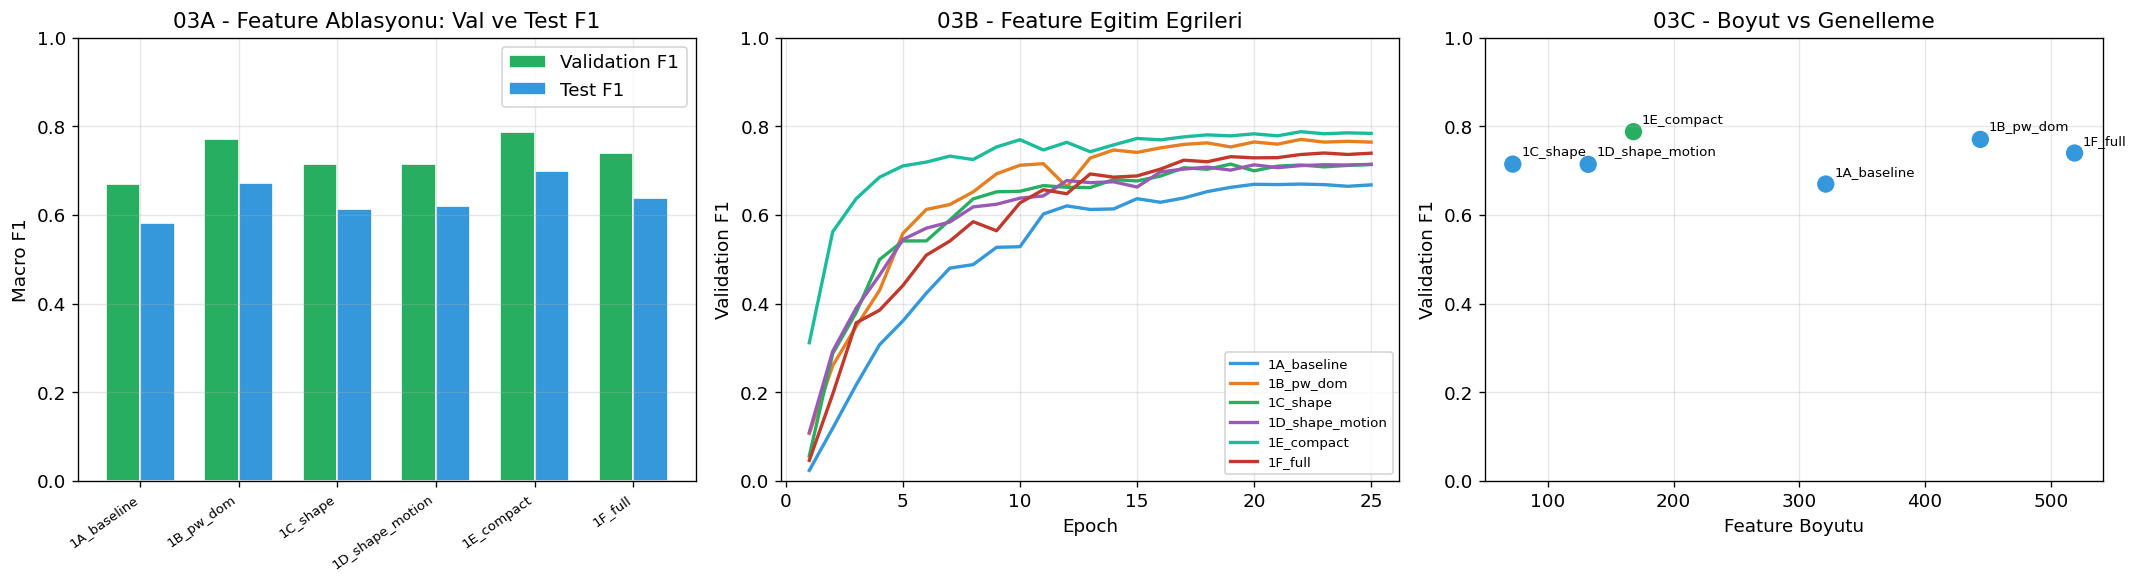

[Gorsel] 03_feature_ablasyonu.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/03_feature_ablasyonu.png yoluna yazildi.

03 - FEATURE ABLASYONU GRAFIGI YORUMU
------------------------------------------------------------------------
Kazanan: 1E_compact (168D), validation F1=0.788.
En dusuk validation F1: 1A_baseline (321D), val F1=0.670.
Compact 168D bu 50 kelime kosusunda val F1=0.788, test F1=0.699 verdi.
Boyut-performans yorumu: Daha buyuk feature her zaman daha iyi olmak zorunda degildir; full temsil daha cok bilgiyle birlikte daha cok gurultu da tasiyabilir.
Onceki 34 kelimelik calismada compact F1=0.720 idi; bu notebook 50 kelime icin sonucu yeniden olcer.
Sonraki adim: Sekans uzunlugu deneyleri kazanan feature builder ile yapilacak.


In [13]:
# ---------------------------------------------------------------------------
# FEATURE ABLASYONU GRAFIKLERI
# 1) Validation ve test F1 bar chart
# 2) Validation F1 egitim egrileri
# 3) Feature boyutu vs validation F1 scatter
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

feature_names = [r["name"] for r in feature_results]
feature_dims = [r["feature_dim"] for r in feature_results]
feature_val_f1 = [r.get("best_val_f1", 0) for r in feature_results]
feature_test_f1 = [r.get("test_f1", 0) for r in feature_results]
bar_positions = np.arange(len(feature_names))
bar_width = 0.35

axes[0].bar(bar_positions - bar_width/2, feature_val_f1, bar_width,
            label="Validation F1", color="#27ae60", edgecolor="white")
axes[0].bar(bar_positions + bar_width/2, feature_test_f1, bar_width,
            label="Test F1", color="#3498db", edgecolor="white")
axes[0].set_xticks(bar_positions)
axes[0].set_xticklabels(feature_names, rotation=35, ha="right", fontsize=8)
axes[0].set_ylabel("Macro F1")
axes[0].set_title("03A - Feature Ablasyonu: Val ve Test F1")
axes[0].set_ylim(0, 1)
axes[0].legend()

curve_colors = ["#3498db", "#e67e22", "#27ae60", "#9b59b6", "#1abc9c", "#c0392b"]
for idx, result in enumerate(feature_results):
    if result.get("history"):
        axes[1].plot(range(1, len(result["history"]["val_f1"]) + 1),
                     result["history"]["val_f1"],
                     label=result["name"], color=curve_colors[idx % len(curve_colors)], linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation F1")
axes[1].set_title("03B - Feature Egitim Egrileri")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8)

scatter_colors = ["#27ae60" if r["name"] == BEST_FEATURE_NAME else "#3498db" for r in feature_results]
axes[2].scatter(feature_dims, feature_val_f1, s=130, c=scatter_colors, edgecolor="white")
for dim, val_f1, name in zip(feature_dims, feature_val_f1, feature_names):
    axes[2].annotate(name, (dim, val_f1), fontsize=8, xytext=(5, 5), textcoords="offset points")
axes[2].set_xlabel("Feature Boyutu")
axes[2].set_ylabel("Validation F1")
axes[2].set_title("03C - Boyut vs Genelleme")
axes[2].set_ylim(0, 1)

plt.tight_layout()
save_figure(fig, "03_feature_ablasyonu.png")

worst_feature_result = min(valid_feature_results, key=lambda r: r.get("best_val_f1", 0))
compact_result = next((r for r in feature_results if r["name"] == "1E_compact"), None)

print("\n03 - FEATURE ABLASYONU GRAFIGI YORUMU")
print("-" * 72)
print(f"Kazanan: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D), validation F1={best_feature_result['best_val_f1']:.3f}.")
print(f"En dusuk validation F1: {worst_feature_result['name']} ({worst_feature_result['feature_dim']}D), val F1={worst_feature_result['best_val_f1']:.3f}.")
if compact_result:
    print(f"Compact 168D bu 50 kelime kosusunda val F1={compact_result['best_val_f1']:.3f}, test F1={compact_result['test_f1']:.3f} verdi.")
print("Boyut-performans yorumu: Daha buyuk feature her zaman daha iyi olmak zorunda degildir; full temsil daha cok bilgiyle birlikte daha cok gurultu da tasiyabilir.")
print("Onceki 34 kelimelik calismada compact F1=0.720 idi; bu notebook 50 kelime icin sonucu yeniden olcer.")
print("Sonraki adim: Sekans uzunlugu deneyleri kazanan feature builder ile yapilacak.")


## Bolum B: Sekans Uzunlugu Deneyleri

Kelime isaretlerinin sureleri ayni degildir. Bazi kelimeler 15-20 frame icinde tamamlanirken, bazilari 45 frame veya daha uzun hareket icerebilir. Bu bolumde feature temsili sabit tutulur ve sadece frame secme stratejisi degistirilir.

| Strateji | Aciklama | Hipotez |
|---|---|---|
| fixed30 | Pad/truncate ile 30 frame | Basit, hizli ve web icin pratik |
| padmask45 | 45 frame + padding mask | Daha uzun hareketleri koruyabilir |
| motion | En hareketli 30 frame | Hareketsiz bekleme kisimlarini azaltabilir |

Kontrol edilen degiskenler: feature = Bolum A kazanan feature, model = BiGRU, augmentasyon = kapali. Secim validation macro F1 ile yapilir; test skoru sadece raporlanir.


In [14]:
# ---------------------------------------------------------------------------
# KAZANAN FEATURE ICIN 3 SEKANS VERSIYONU ON-HESAPLAMA
# Bolum A'da secilen feature builder burada sabit tutulur.
# Artik sadece compact degil, BEST_FEATURE_BUILDER ile hesaplama yapilir.
# ---------------------------------------------------------------------------

print("=" * 72)
print("BOLUM B ICIN FEATURE ON-HESAPLAMA BASLIYOR")
print("=" * 72)
print(f"Kullanilan feature: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D)")
print("Yorum: Bu adim ayni feature temsilinin 3 farkli sekans versiyonunu hazirlar.\n")
t0 = time.time()

# --- 30 frame versiyonu (fixed30) ---
train_f30 = precompute(train_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Train-30")
val_f30 = precompute(val_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Val-30")
test_f30 = precompute(test_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Test-30")

# --- 45 frame + mask versiyonu (padmask45) ---
train_f45 = precompute(train_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_45, "Train-45")
val_f45 = precompute(val_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_45, "Val-45")
test_f45 = precompute(test_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_45, "Test-45")
train_m45 = compute_masks(train_seqs_raw, SEQ_45)
val_m45 = compute_masks(val_seqs_raw, SEQ_45)
test_m45 = compute_masks(test_seqs_raw, SEQ_45)

# --- Motion energy sampling versiyonu ---
print("Hareket enerjisi sampling hesaplaniyor: en hareketli frame'ler secilecek.")
train_fmo = motion_energy_sample(train_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Train-motion")
val_fmo = motion_energy_sample(val_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Val-motion")
test_fmo = motion_energy_sample(test_seqs_raw, BEST_FEATURE_BUILDER, BEST_FEATURE_DIM, SEQ_30, "Test-motion")

elapsed = time.time() - t0
print("\nFEATURE ON-HESAPLAMA OZETI")
print("-" * 72)
print(f"Toplam sure: {elapsed/60:.1f} dakika")
print(f"30-frame veri: {train_f30.shape} -> fixed30 ve final egitim adayi")
print(f"45-frame veri: {train_f45.shape}, mask: {train_m45.shape} -> padmask45 deneyi")
print(f"Motion veri:   {train_fmo.shape} -> hareket enerjisi deneyi")
print("Anlam: Bolum B'de artik kazanan feature'in uc farkli sekans temsili adil sekilde karsilastirilabilir.")
clear_gpu_memory()


BOLUM B ICIN FEATURE ON-HESAPLAMA BASLIYOR
Kullanilan feature: 1E_compact (168D)
Yorum: Bu adim ayni feature temsilinin 3 farkli sekans versiyonunu hazirlar.

  Train-30: 12,723 video icin feature hazirlandi         
  Val-30: 2,658 video icin feature hazirlandi         
  Test-30: 3,918 video icin feature hazirlandi         
  Train-45: 12,723 video icin feature hazirlandi         
  Val-45: 2,658 video icin feature hazirlandi         
  Test-45: 3,918 video icin feature hazirlandi         
Hareket enerjisi sampling hesaplaniyor: en hareketli frame'ler secilecek.
  Train-motion: 12,723 video icin motion feature hazirlandi         
  Val-motion: 2,658 video icin motion feature hazirlandi         
  Test-motion: 3,918 video icin motion feature hazirlandi         

FEATURE ON-HESAPLAMA OZETI
------------------------------------------------------------------------
Toplam sure: 15.6 dakika
30-frame veri: (12723, 30, 168) -> fixed30 ve final egitim adayi
45-frame veri: (12723, 45, 168), mas

In [15]:
# ---------------------------------------------------------------------------
# 3 SEKANS DENEYI
# Burada ayni modelle sadece sekans stratejisini degistiriyoruz.
# Boylece skor farkinin modelden degil, frame seciminden geldigini anlayabiliriz.
# Her deney try/except icinde - biri cokerse digerleri devam eder.
# ---------------------------------------------------------------------------

seq_results = []

experiments = [
    ("fixed30", train_f30, val_f30, test_f30, None, None, None),
    ("padmask45", train_f45, val_f45, test_f45, train_m45, val_m45, test_m45),
    ("motion", train_fmo, val_fmo, test_fmo, None, None, None),
]

print("=" * 72)
print(f"BOLUM B - SEKANS UZUNLUGU DENEYLERI ({QUICK_EPOCHS} epoch, BiGRU)")
print("=" * 72)
print("Amac: Ayni modeli kullanarak 30 frame, 45+mask ve motion sampling yaklasimlarini karsilastirmak.")
print("Ana metrik: Validation macro F1. Test skoru sadece raporlama icin gosterilir.")

for experiment_name, train_features, val_features, test_features, train_mask, val_mask, test_mask in experiments:
    print(f"\nDeney basliyor: {experiment_name}")
    print("Yorum: Bu kosuda model ayni, sadece frame temsil stratejisi degisiyor.")
    try:
        result = run_experiment(
            BiGRU, BEST_FEATURE_DIM, train_features, train_labels, val_features, val_labels, test_features, test_labels,
            tr_mask=train_mask, va_mask=val_mask, te_mask=test_mask,
            lr=LR_GRU, epochs=QUICK_EPOCHS, patience=PATIENCE_QUICK,
            name=experiment_name, augment_train=False,
        )
        seq_results.append(result)
    except Exception as e:
        print(f"  [{experiment_name}] HATA: Bu sekans deneyi tamamlanamadi: {e}")
        print("  Anlam: Diger deneyler yine devam eder; final yorumda bu kosu dikkate alinmaz.")
        traceback.print_exc()
        seq_results.append({
            "name": experiment_name, "test_acc": 0.0, "test_f1": 0.0,
            "best_val_f1": -1.0, "best_val_acc": 0.0, "best_epoch": 0,
            "params": 0, "minutes": 0, "history": None, "model": None,
            "preds": None, "true": None, "test_logits": None,
        })

# Ozet tablo
print("\n" + "=" * 72)
print("SEKANS DENEY SONUCLARI")
print("=" * 72)
print(f"{'Strateji':<12} {'Val F1':>8} {'Test F1':>8} {'Dk':>6} {'Param':>10}")
print("-" * 72)
for r in seq_results:
    print(f"{r['name']:<12} {r.get('best_val_f1', -1):>8.3f} {r['test_f1']:>8.3f} "
          f"{r['minutes']:>6.1f} {r['params']:>10,}")

best_seq = max(seq_results, key=lambda r: r.get("best_val_f1", -1))
print(f"\nSecilen strateji: {best_seq['name']} (Validation macro F1={best_seq['best_val_f1']:.3f})")
print("Anlam: Bolum C'de model mimarileri bu sekans stratejisi sabit tutularak karsilastirilacak.")


# Kaybeden sekans array'leri final akista gerekli degilse temizlenir.
# Secilen stratejiye ait array'ler sonraki bolumde kullanilacagi icin korunur.
if best_seq["name"] != "fixed30":
    del train_f30, val_f30, test_f30
if best_seq["name"] != "padmask45":
    del train_f45, val_f45, test_f45, train_m45, val_m45, test_m45
if best_seq["name"] != "motion":
    del train_fmo, val_fmo, test_fmo
clear_gpu_memory()


BOLUM B - SEKANS UZUNLUGU DENEYLERI (25 epoch, BiGRU)
Amac: Ayni modeli kullanarak 30 frame, 45+mask ve motion sampling yaklasimlarini karsilastirmak.
Ana metrik: Validation macro F1. Test skoru sadece raporlama icin gosterilir.

Deney basliyor: fixed30
Yorum: Bu kosuda model ayni, sadece frame temsil stratejisi degisiyor.
  [fixed30] Epoch   1: train loss=3.1828, val loss=2.1322, val acc=0.400, val macro F1=0.312
  [fixed30] Epoch   5: train loss=1.3402, val loss=1.0461, val acc=0.731, val macro F1=0.711
  [fixed30] Epoch  10: train loss=0.9871, val loss=0.8687, val acc=0.783, val macro F1=0.770
  [fixed30] Epoch  15: train loss=0.8117, val loss=0.8500, val acc=0.784, val macro F1=0.772
  [fixed30] Epoch  20: train loss=0.7022, val loss=0.8268, val acc=0.796, val macro F1=0.783
  [fixed30] Epoch  25: train loss=0.6688, val loss=0.8334, val acc=0.796, val macro F1=0.784
  [fixed30] Test sonucu: accuracy=0.703, macro F1=0.699 | sure=0.9 dk | parametre=602,739
  Anlam: Bu skor, egitimde 

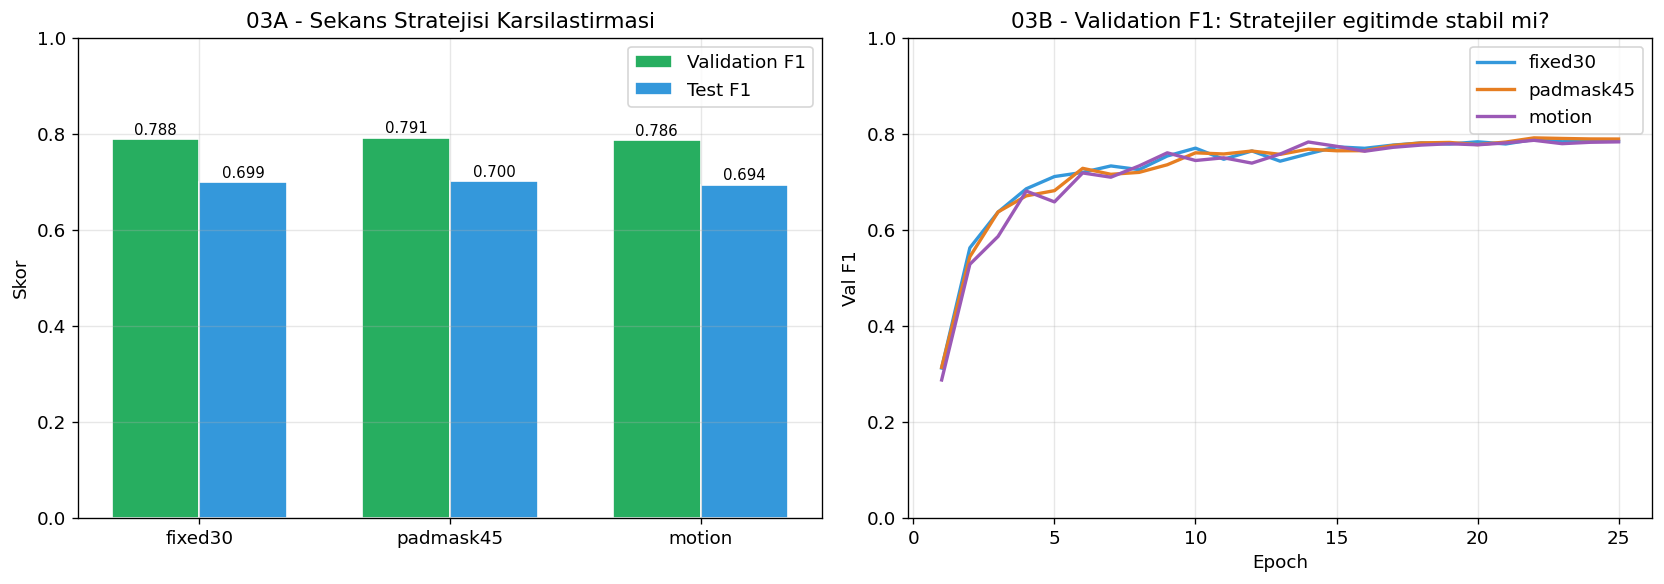

[Gorsel] 03_sekans_karsilastirma.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/03_sekans_karsilastirma.png yoluna yazildi.

03 - SEKANS KARSILASTIRMA GRAFIGI YORUMU
------------------------------------------------------------------------
Grafikte secilen strateji: padmask45 (Validation macro F1=0.791, Test macro F1=0.700)
Anlam: Soldaki grafik karar metrigini ve test rapor skorunu birlikte, sagdaki grafik validation F1 stabilitesini gosterir.
Sonraki adim: Bu strateji Bolum C'de sabit tutulacak.

BOLUM B - SONUC DEGERLENDIRMESI

Secilen strateji: padmask45 (Validation macro F1 = 0.791)
Referans fixed30: Validation macro F1 = 0.788
Fark: +0.3 puan

Yorum: Kucuk bir iyilesme gorulmustur. Sekans uzunlugu etkili
  ancak feature muhendisligi kadar belirleyici degildir.

Sonuc: Bolum C'de padmask45 sabit sekans stratejisi olarak kullanilacaktir.


In [16]:
# ---------------------------------------------------------------------------
# SEKANS DENEY GORSELI
# Bar chart (Validation F1 ve Test F1) + egitim egrileri overlay.
# Kazanan yesil, digerleri mavi.
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar chart (Validation F1 ve Test F1)
sequence_names = [r["name"] for r in seq_results]
sequence_f1_scores = [r.get("best_val_f1", 0) for r in seq_results]
sequence_test_f1_scores = [r["test_f1"] for r in seq_results]
bar_colors = ["#27ae60" if r["name"] == best_seq["name"] else "#2c3e50"
              for r in seq_results]

bar_positions = np.arange(len(sequence_names))
bar_width = 0.35
axes[0].bar(bar_positions - bar_width/2, sequence_f1_scores, bar_width,
            label="Validation F1", color="#27ae60", edgecolor="white")
axes[0].bar(bar_positions + bar_width/2, sequence_test_f1_scores, bar_width,
            label="Test F1", color="#3498db", edgecolor="white")
axes[0].set_xticks(bar_positions)
axes[0].set_xticklabels(sequence_names)
axes[0].set_ylabel("Skor")
axes[0].set_title("03A - Sekans Stratejisi Karsilastirmasi")
axes[0].set_ylim(0, 1)
axes[0].legend()
for bar_index, (val_f1_value, test_f1_value) in enumerate(zip(sequence_f1_scores, sequence_test_f1_scores)):
    axes[0].text(bar_index - bar_width/2, val_f1_value + 0.01,
                 f"{val_f1_value:.3f}", ha="center", fontsize=9)
    axes[0].text(bar_index + bar_width/2, test_f1_value + 0.01,
                 f"{test_f1_value:.3f}", ha="center", fontsize=9)

# 2. Egitim egrileri overlay (val F1 epoch bazli)
curve_colors = {"fixed30": "#3498db", "padmask45": "#e67e22", "motion": "#9b59b6"}
for r in seq_results:
    if r["history"]:
        axes[1].plot(range(1, len(r["history"]["val_f1"]) + 1),
                     r["history"]["val_f1"], label=r["name"],
                     color=curve_colors.get(r["name"], "#7f8c8d"),
                     linewidth=2)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Val F1")
axes[1].set_title("03B - Validation F1: Stratejiler egitimde stabil mi?")
axes[1].legend()
axes[1].set_ylim(0, 1)

plt.tight_layout()
save_figure(fig, "03_sekans_karsilastirma.png")

print("\n03 - SEKANS KARSILASTIRMA GRAFIGI YORUMU")
print("-" * 72)
print(f"Grafikte secilen strateji: {best_seq['name']} (Validation macro F1={best_seq['best_val_f1']:.3f}, Test macro F1={best_seq['test_f1']:.3f})")
print("Anlam: Soldaki grafik karar metrigini ve test rapor skorunu birlikte, sagdaki grafik validation F1 stabilitesini gosterir.")
print("Sonraki adim: Bu strateji Bolum C'de sabit tutulacak.")

# --- Sonuc Yorumu ---
print("\n" + "=" * 72)
print("BOLUM B - SONUC DEGERLENDIRMESI")
print("=" * 72)

best_sequence_result = max(seq_results, key=lambda r: r.get("best_val_f1", -1))
fixed30_result = next((r for r in seq_results if r["name"] == "fixed30"), seq_results[0])
f1_diff_from_fixed30 = (best_sequence_result["best_val_f1"] - fixed30_result["best_val_f1"]) * 100

print(f"\nSecilen strateji: {best_sequence_result['name']} (Validation macro F1 = {best_sequence_result['best_val_f1']:.3f})")
print(f"Referans fixed30: Validation macro F1 = {fixed30_result['best_val_f1']:.3f}")
print(f"Fark: {f1_diff_from_fixed30:+.1f} puan")
print()

if f1_diff_from_fixed30 > 2:
    print("Yorum: Sekans uzunlugu stratejisi anlamli bir fark yaratmistir.")
    if "mask" in best_sequence_result["name"] or "45" in best_sequence_result["name"]:
        print("  Padding mask, modelin gercek ve bos frame'leri ayirt")
        print("  etmesini saglayarak ozellikle uzun kelimelerde iyilesme saglamistir.")
    elif "motion" in best_sequence_result["name"]:
        print("  Hareket enerjisi sampling, hareketsiz frame'leri eleyerek")
        print("  sadece anlamli frame'leri modele sunmustur.")
elif f1_diff_from_fixed30 > 0:
    print("Yorum: Kucuk bir iyilesme gorulmustur. Sekans uzunlugu etkili")
    print("  ancak feature muhendisligi kadar belirleyici degildir.")
else:
    print("Yorum: Sabit 30 frame yeterli gorulmektedir. Ek karmasiklik")
    print("  anlamli bir kazanim saglamamistir.")

print(f"\nSonuc: Bolum C'de {best_sequence_result['name']} sabit sekans stratejisi olarak kullanilacaktir.")


### Bolum B Degerlendirme

Bu bolumun sonunda kazanan sekans stratejisi validation F1 ile otomatik secilir. Sonraki bolumlerde ayni strateji kullanilir, cunku model mimarisini test ederken sekans kararini tekrar degistirmek adil olmaz.

**Degerlendirme notu:** Once feature temsili Bolum A'da sabitlenir, sonra sekans uzunlugu karari Bolum B'de verilir. Boylece model mimarileri karsilastirilirken ana degisken modelin kendisi olur.


## Bolum C: Model Mimarisi Karsilastirmasi

Bu bolumde feature temsili ve sekans stratejisi sabit tutulur; yalnizca model mimarisi degisir. Veri boyutu orta olcekte oldugu icin en buyuk modelin otomatik olarak en iyi sonucu vermesi beklenmez.

| Model | Beklenen Avantaj | Risk |
|---|---|---|
| BiGRU | Sekans verisinde guclu ve stabil baseline | Orta parametre maliyeti |
| SignTransformer | Frame iliskilerini attention ile yakalar | Kucuk veride mode collapse veya hassas ayar riski |
| SmallGRU | Hafif ve web icin hizli | Kapasite siniri olabilir |
| ConvGRU | Kisa hareket desenleri + sekans modelleme | Ek mimari karmasiklik |
| Ensemble | Iki modelin skorlarini birlestirir | Web'de iki model maliyetlidir |

Secim yine validation macro F1 ile yapilir. Ensemble model karsilastirmasi icin raporlanir, fakat final export icin tek model tercih edilir.


In [17]:
# ---------------------------------------------------------------------------
# BOLUM B'DE SECILEN STRATEJIYE GORE VERI HAZIRLA
# Bolum C'de artik sekans degil, model mimarisi test edilecek.
# Bu yuzden Bolum A'nin kazanan sekans verisini sabitliyoruz.
# ---------------------------------------------------------------------------

best_seq_name = best_seq["name"]

# Bolum B hangi sekans stratejisini en iyi bulduysa, Bolum B'de tum modeller
# ayni veri temsiliyle test edilir. Boylece model karsilastirmasi adil olur:
# fark sekans hazirligindan degil, mimariden kaynaklanir.
if best_seq_name == "padmask45":
    selected_train_features = train_f45
    selected_val_features = val_f45
    selected_test_features = test_f45
    selected_train_mask = train_m45
    selected_val_mask = val_m45
    selected_test_mask = test_m45
    has_mask = True
elif best_seq_name == "motion":
    selected_train_features = train_fmo
    selected_val_features = val_fmo
    selected_test_features = test_fmo
    selected_train_mask = selected_val_mask = selected_test_mask = None
    has_mask = False
else:  # fixed30
    selected_train_features = train_f30
    selected_val_features = val_f30
    selected_test_features = test_f30
    selected_train_mask = selected_val_mask = selected_test_mask = None
    has_mask = False

print("=" * 72)
print("BOLUM C ICIN SABIT VERI HAZIR")
print("=" * 72)
print(f"Kullanilan feature: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D)")
print(f"Kullanilan sekans stratejisi: {best_seq_name}")
print(f"Train feature sekli: {selected_train_features.shape}")
print(f"Val feature sekli:   {selected_val_features.shape}")
print(f"Test feature sekli:  {selected_test_features.shape}")
print(f"Padding mask kullanimi: {'evet' if has_mask else 'hayir'}")
print("Anlam: Model mimarileri artik ayni feature ve ayni sekans verisi uzerinde karsilastirilacak.")


BOLUM C ICIN SABIT VERI HAZIR
Kullanilan feature: 1E_compact (168D)
Kullanilan sekans stratejisi: padmask45
Train feature sekli: (12723, 45, 168)
Val feature sekli:   (2658, 45, 168)
Test feature sekli:  (3918, 45, 168)
Padding mask kullanimi: evet
Anlam: Model mimarileri artik ayni feature ve ayni sekans verisi uzerinde karsilastirilacak.


In [18]:
# ---------------------------------------------------------------------------
# 4 MODEL DENEYI + ENSEMBLE
#
# Bu bölümde veri ve sekans stratejisi sabit tutulur; yalnızca model mimarisi değişir.
# Böylece skor farkının veri hazırlığından değil, model yapısından geldiği anlaşılır.
#
# Ensemble, birden fazla modelin ham skorlarını birleştirme yöntemidir. Burada en iyi
# iki modelin test logit değerleri ortalanır. Logit, softmax öncesi ham sınıf skorudur.
# Ensemble model karşılaştırması için yararlıdır; ancak web'de iki model çalıştırmak
# indirme boyutunu ve tahmin süresini artırır.
# ---------------------------------------------------------------------------

model_results = []

model_specs = [
    ("BiGRU", BiGRU, LR_GRU, 0),
    ("SignTransformer", SignTransformer, LR_TRANSFORMER, 3),  # warmup=3 epoch
    ("SmallGRU", SmallGRU, LR_GRU, 0),
    ("ConvGRU", ConvGRU, LR_GRU, 0),
]

print("=" * 72)
print(f"BOLUM C - MODEL MIMARISI DENEYLERI ({QUICK_EPOCHS} epoch)")
print("=" * 72)
print("Amac: Veri ve sekans sabitken hangi modelin daha iyi genelledigini olcmek.")
print("Yorum: Skorun yaninda parametre sayisi ve web calisma maliyeti de dikkate alinacak.")

for model_name, model_class, model_lr, model_warmup in model_specs:
    print(f"\nModel deneyi basliyor: {model_name} (lr={model_lr}, warmup={model_warmup})")
    print("Yorum: Bu kosuda veri ayni; fark yalnizca model mimarisinden gelir.")
    try:
        result = run_experiment(
            model_class, BEST_FEATURE_DIM, selected_train_features, train_labels, selected_val_features, val_labels,
            selected_test_features, test_labels,
            tr_mask=selected_train_mask, va_mask=selected_val_mask, te_mask=selected_test_mask,
            lr=model_lr, epochs=QUICK_EPOCHS, patience=PATIENCE_QUICK,
            warmup=model_warmup, name=model_name, augment_train=False,
        )
        model_results.append(result)
    except Exception as e:
        print(f"  [{model_name}] HATA: Bu model deneyi tamamlanamadi: {e}")
        print("  Anlam: Diger modeller devam eder; final secimde bu kosu 0 skorla gorunur.")
        traceback.print_exc()
        model_results.append({
            "name": model_name, "test_acc": 0.0, "test_f1": 0.0,
            "best_val_f1": -1.0, "best_val_acc": 0.0, "best_epoch": 0,
            "params": 0, "minutes": 0, "history": None, "model": None,
            "preds": None, "true": None, "test_logits": None,
        })

# --- Ensemble: En iyi 2 modelin logit ortalamasi ---
# Ensemble icin sadece basariyla tamamlanan modeller kullanilir.
# Hata alan modellerin test_logits degeri None oldugu icin karisima dahil edilmez.
valid_results = [r for r in model_results if r["test_logits"] is not None]
valid_results.sort(key=lambda r: -r.get("best_val_f1", -1))
top_two = valid_results[:2]

if len(top_two) == 2:
    print(f"\nEnsemble kontrolu: {top_two[0]['name']} + {top_two[1]['name']}")
    print("Yorum: Bu sadece karsilastirma icindir; web tarafinda tek model daha pratik olabilir.")
    ens_logits = (top_two[0]["test_logits"] + top_two[1]["test_logits"]) / 2
    ens_preds = ens_logits.argmax(axis=1)
    ens_acc = accuracy_score(test_labels, ens_preds)
    ens_f1 = f1_score(test_labels, ens_preds, average="macro", zero_division=0)
    print(f"  Ensemble test sonucu: accuracy={ens_acc:.3f}, macro F1={ens_f1:.3f}")

    ens_params = top_two[0]["params"] + top_two[1]["params"]
    model_results.append({
        "name": f"Ensemble ({top_two[0]['name']}+{top_two[1]['name']})",
        "best_val_f1": ens_f1,
        "best_val_acc": ens_acc,
        "best_epoch": 0,
        "test_acc": ens_acc, "test_f1": ens_f1,
        "params": ens_params, "minutes": top_two[0]["minutes"] + top_two[1]["minutes"],
        "history": None, "model": None,
        "preds": ens_preds, "true": test_labels, "test_logits": ens_logits,
    })

# Ozet tablo
print("\n" + "=" * 72)
print("MODEL DENEY SONUCLARI")
print("=" * 72)
print(f"{'Model':<36} {'Val F1':>8} {'Test F1':>8} {'Dk':>6} {'Param':>12}")
print("-" * 80)
for r in model_results:
    print(f"{r['name']:<36} {r.get('best_val_f1', -1):>8.3f} {r['test_f1']:>8.3f} "
          f"{r['minutes']:>6.1f} {r['params']:>12,}")

best_model_result = max(model_results, key=lambda r: r.get("best_val_f1", -1))
print(f"\nSecim kriterine gore en iyi sonuc: {best_model_result['name']} (Val F1={best_model_result['best_val_f1']:.3f}, Test F1={best_model_result['test_f1']:.3f})")

# Ensemble kazansa bile Bolum C icin en iyi SINGLE modeli sec
best_single = max(valid_results, key=lambda r: r.get("best_val_f1", -1)) if valid_results else None
if best_single:
    print(f"Final egitim icin secilen single model: {best_single['name']}")
    print("Anlam: Web uygulamasinda tek ONNX model daha hizli ve daha kolay dagitilir.")

# Bolum C sonu — GPU belleği temizle (Bolum C 100 epoch tam eğitim için yer aç)
clear_gpu_memory()


BOLUM C - MODEL MIMARISI DENEYLERI (25 epoch)
Amac: Veri ve sekans sabitken hangi modelin daha iyi genelledigini olcmek.
Yorum: Skorun yaninda parametre sayisi ve web calisma maliyeti de dikkate alinacak.

Model deneyi basliyor: BiGRU (lr=0.001, warmup=0)
Yorum: Bu kosuda veri ayni; fark yalnizca model mimarisinden gelir.
  [BiGRU] Epoch   1: train loss=3.1671, val loss=2.1167, val acc=0.400, val macro F1=0.313
  [BiGRU] Epoch   5: train loss=1.3227, val loss=1.0623, val acc=0.714, val macro F1=0.681
  [BiGRU] Epoch  10: train loss=0.9845, val loss=0.9046, val acc=0.773, val macro F1=0.760
  [BiGRU] Epoch  15: train loss=0.8068, val loss=0.8668, val acc=0.777, val macro F1=0.764
  [BiGRU] Epoch  20: train loss=0.7033, val loss=0.8554, val acc=0.790, val macro F1=0.777
  [BiGRU] Epoch  25: train loss=0.6659, val loss=0.8336, val acc=0.801, val macro F1=0.789
  [BiGRU] Test sonucu: accuracy=0.705, macro F1=0.700 | sure=0.9 dk | parametre=602,739
  Anlam: Bu skor, egitimde karar vermek ic

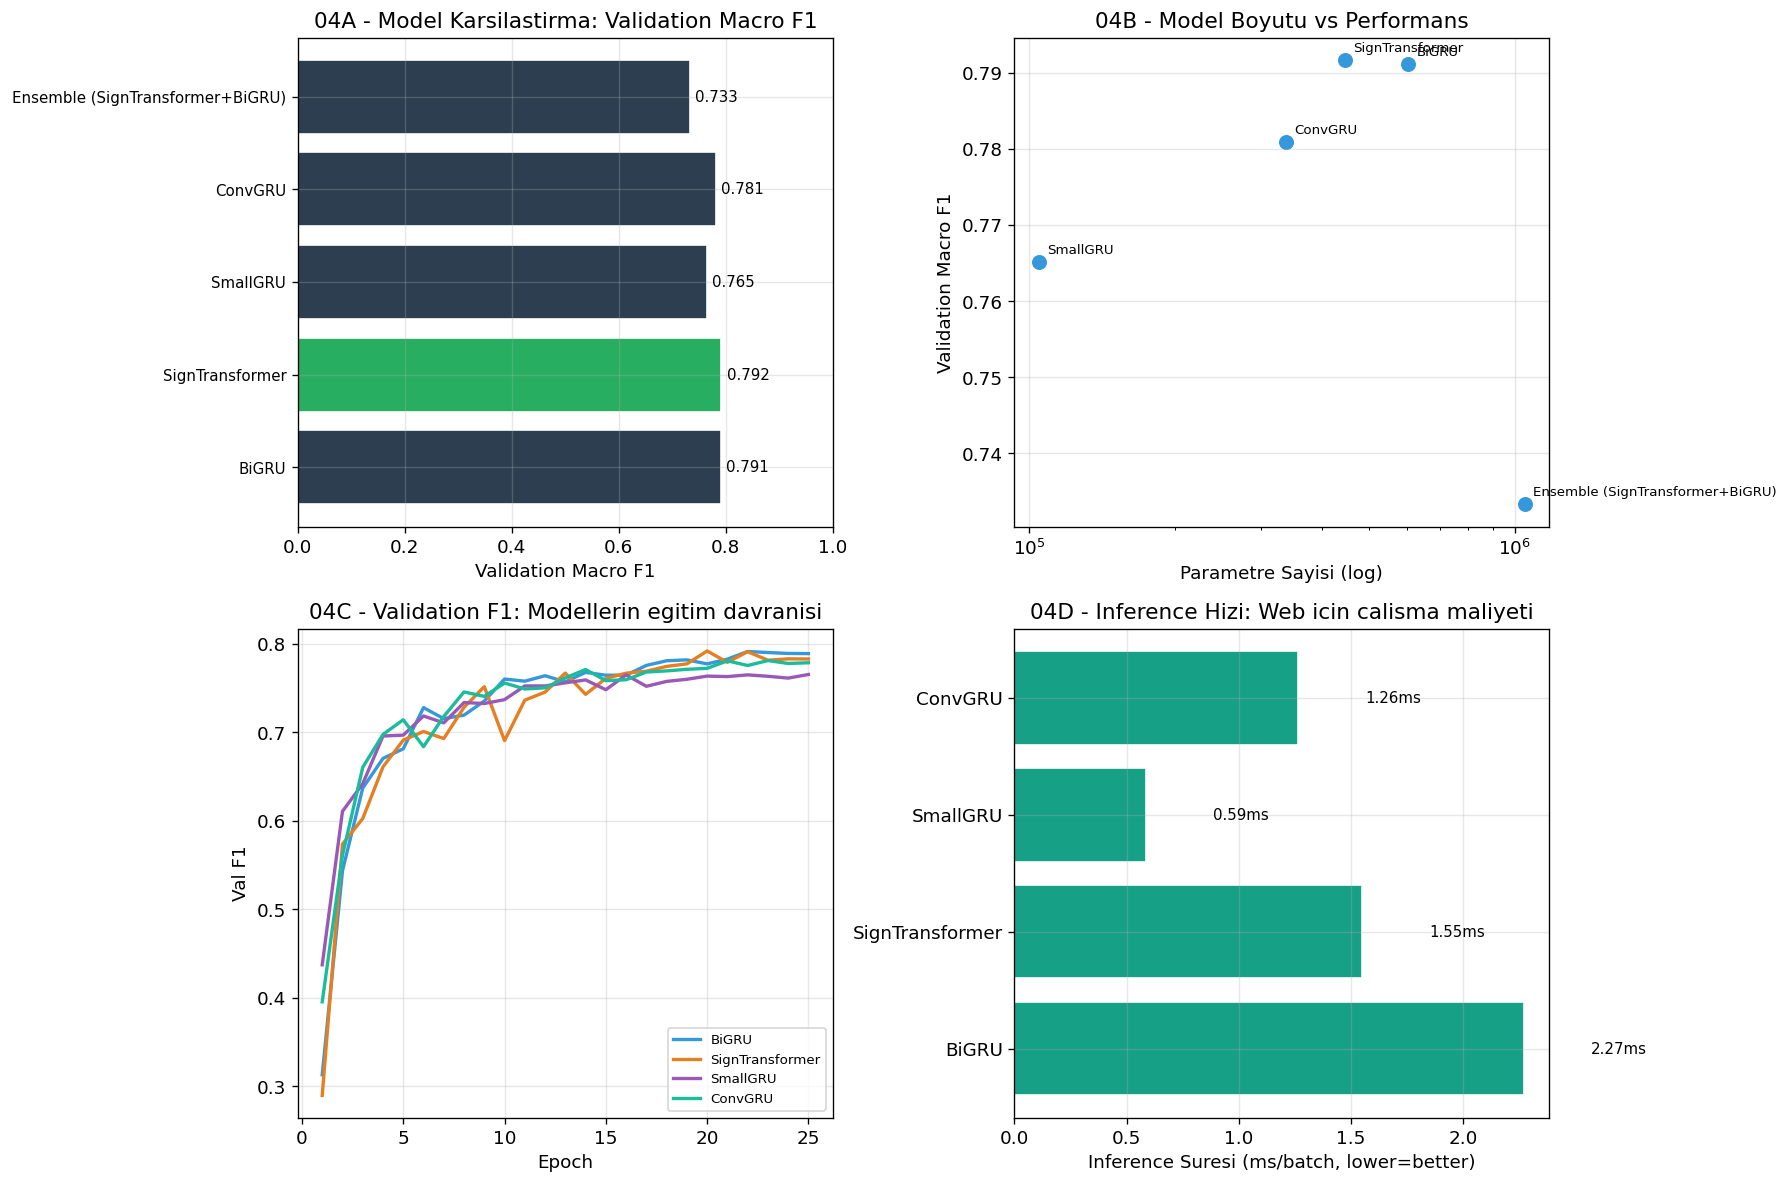

[Gorsel] 04_model_karsilastirma.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/04_model_karsilastirma.png yoluna yazildi.

04 - MODEL KARSILASTIRMA GRAFIGI YORUMU
------------------------------------------------------------------------
Sol ust: validation macro F1 skorlarini gosterir; secim bu metrikle yapilir.
Sag ust: parametre sayisi arttikca skorun nasil degistigini gosterir.
Sol alt: validation F1 egrileriyle modellerin egitim davranisini gosterir.
Sag alt: inference hizi ile web tarafindaki calisma maliyetini gosterir.

BOLUM C - SONUC DEGERLENDIRMESI

Validation F1 ile secilen sonuc: SignTransformer
  Validation macro F1: 0.792
  Test macro F1: 0.719
  Parametre sayisi: 446,195

BiGRU referans: Test F1 = 0.700
Kazanana gore fark: +1.8 puan

Ensemble sonucu: Test F1 = 0.733
  Yorum: Ensemble tek modelden daha iyi gorunuyor; ancak web'de iki modeli calistirmak
  inference suresini ve indirme boyutunu arttirir.

Transformer sonucu: Test F1 

In [19]:
# ---------------------------------------------------------------------------
# MODEL KARSILASTIRMA GORSELI (2x2)
# 1) Validation F1 ve Test F1 bar chart
# 2) Param vs F1 scatter
# 3) Egitim egrileri overlay
# 4) Inference hiz karsilastirmasi
# ---------------------------------------------------------------------------

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Validation F1 ve Test F1 bar chart
names = [r["name"] for r in model_results]
val_f1s = [r.get("best_val_f1", 0) for r in model_results]
test_f1s = [r["test_f1"] for r in model_results]
bar_colors = ["#27ae60" if r["name"] == best_model_result["name"] else "#2c3e50" for r in model_results]
axes[0, 0].barh(range(len(names)), val_f1s, color=bar_colors, edgecolor="white")
axes[0, 0].set_yticks(range(len(names)))
axes[0, 0].set_yticklabels(names, fontsize=9)
axes[0, 0].set_xlabel("Validation Macro F1")
axes[0, 0].set_title("04A - Model Karsilastirma: Validation Macro F1")
axes[0, 0].set_xlim(0, 1)
for i, f in enumerate(val_f1s):
    axes[0, 0].text(f + 0.01, i, f"{f:.3f}", va="center", fontsize=9)

# 2. Parametre vs F1 scatter
params_list = [r["params"] for r in model_results if r["params"] > 0]
f1_list = [r.get("best_val_f1", 0) for r in model_results if r["params"] > 0]
name_list = [r["name"] for r in model_results if r["params"] > 0]
axes[0, 1].scatter(params_list, f1_list, s=100, c="#3498db", edgecolor="white")
for p, f, n in zip(params_list, f1_list, name_list):
    axes[0, 1].annotate(n, (p, f), fontsize=8, xytext=(5, 5),
                        textcoords="offset points")
axes[0, 1].set_xscale("log")
axes[0, 1].set_xlabel("Parametre Sayisi (log)")
axes[0, 1].set_ylabel("Validation Macro F1")
axes[0, 1].set_title("04B - Model Boyutu vs Performans")

# 3. Egitim egrileri overlay
curve_colors_m = ["#3498db", "#e67e22", "#9b59b6", "#1abc9c", "#c0392b"]
for idx, r in enumerate(model_results):
    if r["history"]:
        axes[1, 0].plot(range(1, len(r["history"]["val_f1"]) + 1),
                        r["history"]["val_f1"], label=r["name"],
                        color=curve_colors_m[idx % len(curve_colors_m)], linewidth=2)
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Val F1")
axes[1, 0].set_title("04C - Validation F1: Modellerin egitim davranisi")
axes[1, 0].legend(fontsize=8)

# 4. Inference hiz (batch bazli timing)
inf_times = {}
for r in model_results:
    if r["model"] is None:
        continue
    r["model"].eval()
    if has_mask:
        dummy_features = torch.randn(BATCH_SIZE, 45, BEST_FEATURE_DIM).to(DEVICE)
        dummy_padding_mask = torch.ones(BATCH_SIZE, 45, dtype=torch.bool).to(DEVICE)
    else:
        inference_seq_len = 30
        dummy_features = torch.randn(BATCH_SIZE, inference_seq_len, BEST_FEATURE_DIM).to(DEVICE)
        dummy_padding_mask = None
    with torch.no_grad():
        for _ in range(3):  # warmup
            _ = r["model"](dummy_features, dummy_padding_mask) if dummy_padding_mask is not None else r["model"](dummy_features)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        timing_start = time.time()
        for _ in range(10):
            _ = r["model"](dummy_features, dummy_padding_mask) if dummy_padding_mask is not None else r["model"](dummy_features)
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        inf_times[r["name"]] = (time.time() - timing_start) / 10 * 1000  # ms/batch

if inf_times:
    axes[1, 1].barh(list(inf_times.keys()), list(inf_times.values()),
                    color="#16a085", edgecolor="white")
    axes[1, 1].set_xlabel("Inference Suresi (ms/batch, lower=better)")
    axes[1, 1].set_title("04D - Inference Hizi: Web icin calisma maliyeti")
    for i, v in enumerate(inf_times.values()):
        axes[1, 1].text(v + 0.3, i, f"{v:.2f}ms", va="center", fontsize=9)

plt.tight_layout()
save_figure(fig, "04_model_karsilastirma.png")

print("\n04 - MODEL KARSILASTIRMA GRAFIGI YORUMU")
print("-" * 72)
print("Sol ust: validation macro F1 skorlarini gosterir; secim bu metrikle yapilir.")
print("Sag ust: parametre sayisi arttikca skorun nasil degistigini gosterir.")
print("Sol alt: validation F1 egrileriyle modellerin egitim davranisini gosterir.")
print("Sag alt: inference hizi ile web tarafindaki calisma maliyetini gosterir.")

# --- Sonuc Yorumu ---
print("\n" + "=" * 72)
print("BOLUM C - SONUC DEGERLENDIRMESI")
print("=" * 72)

best_m = best_model_result
gru_m = next((r for r in model_results if "BiGRU" in r["name"]), None)

print(f"\nValidation F1 ile secilen sonuc: {best_m['name']}")
print(f"  Validation macro F1: {best_m['best_val_f1']:.3f}")
print(f"  Test macro F1: {best_m['test_f1']:.3f}")
print(f"  Parametre sayisi: {best_m['params']:,}")

if gru_m and gru_m != best_m:
    diff = (best_m["test_f1"] - gru_m["test_f1"]) * 100
    print(f"\nBiGRU referans: Test F1 = {gru_m['test_f1']:.3f}")
    print(f"Kazanana gore fark: {diff:+.1f} puan")

# Ensemble analizi
ens = next((r for r in model_results if "Ensemble" in r["name"]), None)
if ens:
    print(f"\nEnsemble sonucu: Test F1 = {ens['test_f1']:.3f}")
    if ens["test_f1"] > best_m["test_f1"]:
        print("  Yorum: Ensemble tek modelden daha iyi gorunuyor; ancak web'de iki modeli calistirmak")
        print("  inference suresini ve indirme boyutunu arttirir.")
    else:
        print("  Yorum: Ensemble ek kazanc saglamadi; tek model yeterli ve daha pratiktir.")

# Transformer analizi
trans = next((r for r in model_results if "Transformer" in r["name"]), None)
if trans:
    print(f"\nTransformer sonucu: Test F1 = {trans['test_f1']:.3f}")
    if trans["test_f1"] < 0.1:
        print("  Transformer bu kosuda basarili sonuc veremedi; tahminler az sayida sinifa yigilmis olabilir.")
        print("  Yorum: Bu durum genellikle veri miktari model kapasitesine yetmediginde veya ayarlar hassas oldugunda gorulur.")
    elif gru_m and trans["test_f1"] < gru_m["test_f1"]:
        print("  Transformer, GRU'dan dusuk. Kucuk veri setinde")
        print("  GRU'nun daha az parametreyle daha iyi genelledigi dogrulandi.")
        print("  (Chung et al. 2014 bulgusunu destekler)")
    else:
        print("  Transformer bu kosuda basarili gorunuyor; daha buyuk veriyle potansiyeli artabilir.")

print(f"\nSonuc: Bolum D'de {best_single['name'] if best_single else best_m['name']} single model olarak 100 epoch tam egitime alinacak.")


## Bolum D: Final Egitim ve Export

Bu bolumde onceki kararlar birlestirilir: Bolum A'da secilen feature, Bolum B'de secilen sekans stratejisi ve Bolum C'de secilen single model kullanilir. Model sifirdan 100 epoch hedefiyle egitilir.

Progressive augmentation ilk epoch'larda kapali tutulur. Model once temiz feature dizilerini ogrenir; daha sonra hafif gurultu, zaman maskesi, olcekleme ve zaman kaydirma ile canli kamera farkliliklarina alistirilir.

Final egitimde de model secimi validation F1 ile yapilir. Test seti egitim karari icin kullanilmaz; en iyi validation agirligi yuklendikten sonra tek final test olcumu raporlanir. Ardindan temperature calibration, ONNX export, sinif bazli analiz ve web JSON dosyalari uretilir.


In [20]:
# Bolum D başlangıcı — önceki bölümlerden kalan GPU belleğini temizle
clear_gpu_memory()

# ---------------------------------------------------------------------------
# FINAL EGITIM — 100 EPOCH
#
# Bu bölüm artık seçilen en iyi ayarlarla asıl modeli eğitir.
# Önceki bölümlerde feature, sekans uzunluğu ve model mimarisi karşılaştırıldı.
# Burada bu kararlar birleştirilir ve daha uzun final eğitim yapılır.
#
# Progressive augmentation: İlk epoch'larda temiz veri kullanılır, sonra kontrollü
# veri çeşitlendirme açılır. Böylece model önce temel hareketi öğrenir, ardından
# canlı kamera farklılıklarına daha dayanıklı hale gelir.
#
# Early stopping: Validation F1 uzun süre iyileşmezse eğitim durur. Bu, gereksiz
# süreyi azaltır ve modelin eğitim verisini ezberleme riskini sınırlar.
# ---------------------------------------------------------------------------

# Kazanan single model ve kazanan sekans stratejisi
# Ensemble daha yuksek ciksa bile final export icin tek model secilir.
# Sebep: Web uygulamasinda tek ONNX modeli daha hizli ve daha kolay dagitilir.
FINAL_MODEL_CLS = type(best_single["model"]) if best_single and best_single["model"] else BiGRU
FINAL_MODEL_NAME = best_single["name"] if best_single else "BiGRU"
print("=" * 72)
print("FINAL EGITIM AYARLARI")
print("=" * 72)
print(f"Final single model: {FINAL_MODEL_NAME}")
print(f"Final feature: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D)")
print(f"Final sekans stratejisi: {best_seq_name}")
print(f"Padding mask kullanimi: {'evet' if has_mask else 'hayir'}")
print("Anlam: Onceki deneylerde secilen kararlar burada asil model egitimi icin birlestirildi.\n")

set_seed()

# ProgressiveDataset ile aug kontrolu
final_train_ds = ProgressiveDataset(selected_train_features, train_labels, selected_train_mask)
final_val_ds = PrecomputedDataset(selected_val_features, val_labels, selected_val_mask, augment=False)
final_test_ds = PrecomputedDataset(selected_test_features, test_labels, selected_test_mask, augment=False)

final_train_dl = make_dataloader(final_train_ds, batch_size=BATCH_SIZE, shuffle=True)
final_val_dl = make_dataloader(final_val_ds, batch_size=BATCH_SIZE*2, shuffle=False)
final_test_dl = make_dataloader(final_test_ds, batch_size=BATCH_SIZE*2, shuffle=False)

# Model + optimizer ayarları.
# Optimizer, loss değerine bakarak model ağırlıklarını güncelleyen algoritmadır.
# Learning rate bu güncellemenin adım büyüklüğüdür.
# Transformer daha hassas olduğu için daha düşük learning rate ve warmup kullanılır.
# GRU tabanlı modeller bu veri miktarında daha stabil olduğu için LR_GRU yeterlidir.
FINAL_LR = LR_TRANSFORMER if FINAL_MODEL_CLS == SignTransformer else LR_GRU
FINAL_WARMUP = 5 if FINAL_MODEL_CLS == SignTransformer else 0

# Final model sifirdan kurulur.
# Bolum B'deki quick model agirliklari dogrudan kullanilmaz; burada daha uzun ve temiz final egitim yapilir.
final_model = FINAL_MODEL_CLS(BEST_FEATURE_DIM, NUM_CLASSES).to(DEVICE)
final_params = sum(p.numel() for p in final_model.parameters())
print(f"Final model parametre sayisi: {final_params:,}")
print("Yorum: Parametre sayisi modelin kapasitesini ve web tarafindaki hesaplama maliyetini etkiler.")

final_opt = torch.optim.AdamW(final_model.parameters(), lr=FINAL_LR,
                              weight_decay=WEIGHT_DECAY)
final_criterion = FocalLoss(gamma=2.0, label_smoothing=0.1).to(DEVICE)
final_scaler = make_grad_scaler()

# CosineAnnealingWarmRestarts learning rate'i dalga gibi azaltıp belirli aralıklarla
# tekrar yükseltir. Amaç, modelin bir noktaya erken takılı kalmasını azaltmak ve
# eğitim ilerledikçe daha ince ayar yapabilmektir.
final_scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    final_opt, T_0=10, T_mult=2, eta_min=FINAL_LR * 0.01,
)

# Egitim dongusu
final_history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1": [],
                 "lr": [], "aug_active": []}
final_best_f1 = -1.0
final_best_state = None
final_patience = 0
t_start = time.time()

print(f"\nFinal egitim basliyor: hedef {FULL_EPOCHS} epoch, early stopping patience={PATIENCE_FULL}")
print(f"Progressive augmentation epoch {AUG_START_EPOCH}'dan itibaren acilacak.")
print("Anlam: Ilk kisimda temiz veriyle temel hareket ogrenilir; sonra augmentation ile genelleme gucu test edilir.\n")

for epoch in range(1, FULL_EPOCHS + 1):
    # Progressive augmentation — epoch 30'dan sonra ac.
    # onceki bayragi sakliyoruz; boylece augmentation'in ilk acildigi ani sadece bir kez yazdiririz.
    augmentation_was_active = final_train_ds.aug_active
    final_train_ds.aug_active = (epoch >= AUG_START_EPOCH)
    if not augmentation_was_active and final_train_ds.aug_active:
        print(f"\nEpoch {epoch}: Progressive augmentation acildi.")
        print("Anlam: Bundan sonra modele hafif gurultu, zaman maskesi ve olcekleme gibi cesitlemeler uygulanacak.\n")

    # Train
    # Bu adimda model agirliklari guncellenir.
    # train_loss dusuyorsa model egitim verisini daha iyi aciklamaya baslamistir.
    tr_loss = train_epoch(final_model, final_train_dl, final_criterion,
                          final_opt, final_scaler, use_amp=True,
                          grad_clip=GRAD_CLIP)

    # Val
    # Validation modelin gormedigi kisiler uzerinde ara kontroldur.
    # Burada agirlik guncellenmez; sadece model secimi icin skor olculur.
    va_acc, va_f1, _, _, _ = eval_model(final_model, final_val_dl)

    # Val loss ayri hesapla.
    # Bu deger sadece grafik ve overfitting yorumu icin saklanir; model agirligi guncellenmez.
    final_model.eval()
    va_loss = 0.0
    validation_sample_count = 0
    with torch.no_grad():
        for batch in final_val_dl:
            features, padding_mask, labels = move_batch_to_device(batch)
            logits = final_model(features, padding_mask) if padding_mask is not None else final_model(features)
            va_loss += final_criterion(logits, labels).item() * features.size(0)
            validation_sample_count += features.size(0)
        va_loss /= max(validation_sample_count, 1)

    cur_lr = final_opt.param_groups[0]["lr"]
    final_history["train_loss"].append(tr_loss)
    final_history["val_loss"].append(va_loss)
    final_history["val_acc"].append(va_acc)
    final_history["val_f1"].append(va_f1)
    final_history["lr"].append(cur_lr)
    final_history["aug_active"].append(final_train_ds.aug_active)

    # Scheduler learning rate'i epochlara gore degistirir.
    # Amaç: baslarda daha hizli ogrenmek, ilerledikce daha ince ayar yapmak.
    final_scheduler.step()

    # Best model kaydi
    # Finalde son epoch'u degil, validation F1'i en iyi olan agirliklari kullaniriz.
    # Bu, egitimin sonunda overfit baslasa bile en iyi modeli kaybetmemeyi saglar.
    if va_f1 > final_best_f1:
        final_best_f1 = va_f1
        final_best_state = {k: v.clone().cpu() for k, v in final_model.state_dict().items()}
        final_patience = 0
    else:
        final_patience += 1

    if epoch % 10 == 0 or epoch == 1:
        aug_s = "ON " if final_train_ds.aug_active else "OFF"
        print(f"  Epoch {epoch:3d} [aug={aug_s}] "
              f"train loss={tr_loss:.4f}, val loss={va_loss:.4f}, "
              f"val acc={va_acc:.3f}, val macro F1={va_f1:.3f}, lr={cur_lr:.2e}")

    if final_patience >= PATIENCE_FULL:
        print(f"\nEarly stopping: validation F1 {PATIENCE_FULL} epoch boyunca iyilesmedi, epoch {epoch}'ta egitim durdu.")
        break

# En iyi modeli yukle
if final_best_state is not None:
    final_model.load_state_dict(final_best_state)

# Test et
final_acc, final_f1, final_preds, final_true, final_logits = eval_model(final_model, final_test_dl)
elapsed = (time.time() - t_start) / 60

print(f"\n{'='*72}")
print("FINAL TEST SONUCU")
print(f"{'='*72}")
print(f"Test accuracy: {final_acc:.4f}")
print(f"Test macro F1: {final_f1:.4f}")
print(f"Egitim suresi: {elapsed:.1f} dakika")
print("Anlam: Bu skorlar final modelin egitim/validation kararlarinda kullanilmayan test kisilerindeki performansidir.")
print(f"{'='*72}")

# Model kaydet
final_model_path = artifact_path("final_model.pt")
torch.save(final_model.state_dict(), final_model_path)
print(f"\n[Model] final_model.pt kaydedildi: {final_model_path}")
print("Anlam: Bu PyTorch agirlik dosyasi yedek/tekrar egitim kontrolu icindir; web tarafinda asil dosya ONNX olacaktir.")


FINAL EGITIM AYARLARI
Final single model: SignTransformer
Final feature: 1E_compact (168D)
Final sekans stratejisi: padmask45
Padding mask kullanimi: evet
Anlam: Onceki deneylerde secilen kararlar burada asil model egitimi icin birlestirildi.

Final model parametre sayisi: 446,195
Yorum: Parametre sayisi modelin kapasitesini ve web tarafindaki hesaplama maliyetini etkiler.

Final egitim basliyor: hedef 100 epoch, early stopping patience=20
Progressive augmentation epoch 30'dan itibaren acilacak.
Anlam: Ilk kisimda temiz veriyle temel hareket ogrenilir; sonra augmentation ile genelleme gucu test edilir.

  Epoch   1 [aug=OFF] train loss=2.7158, val loss=1.6553, val acc=0.528, val macro F1=0.469, lr=5.00e-04
  Epoch  10 [aug=OFF] train loss=0.9746, val loss=0.9228, val acc=0.771, val macro F1=0.754, lr=1.71e-05
  Epoch  20 [aug=OFF] train loss=0.7993, val loss=0.9273, val acc=0.782, val macro F1=0.768, lr=2.91e-04

Epoch 30: Progressive augmentation acildi.
Anlam: Bundan sonra modele haf

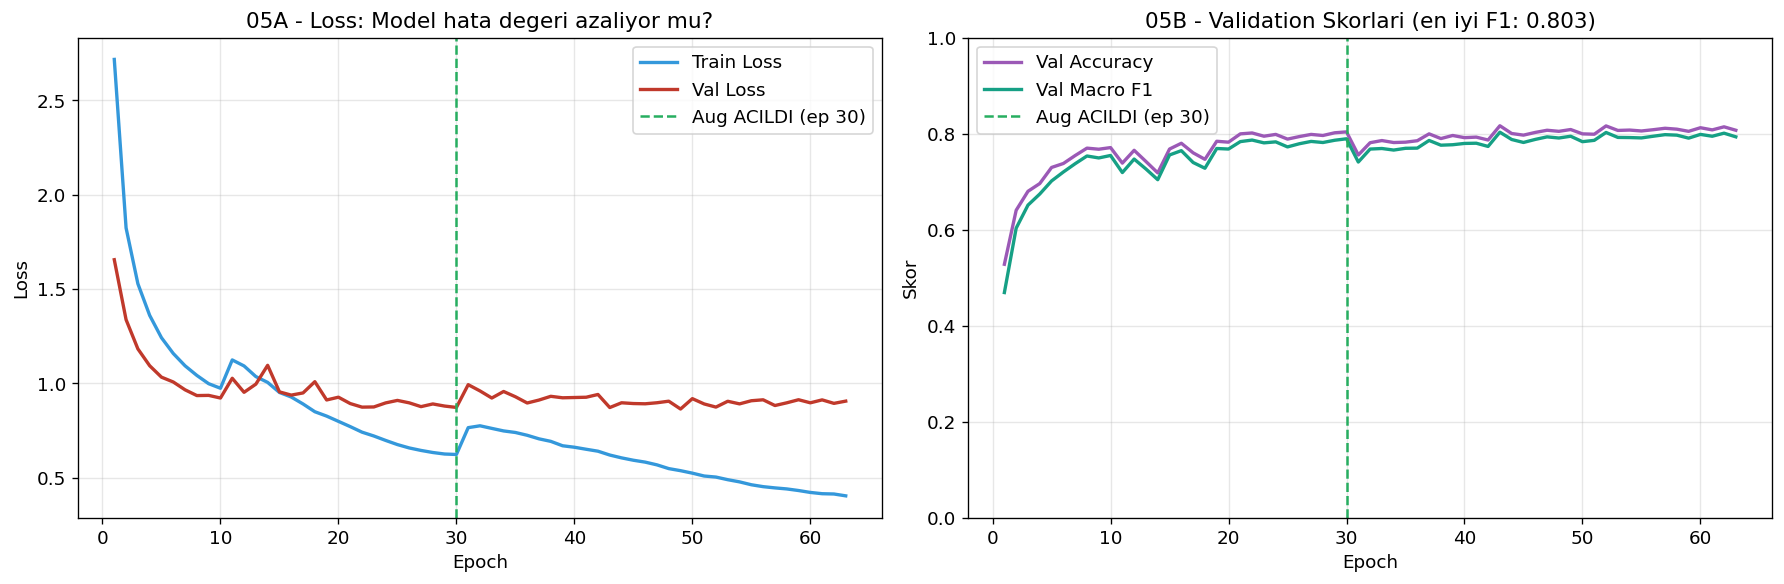

[Gorsel] 05_full_training_egrileri.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/05_full_training_egrileri.png yoluna yazildi.

05 - FINAL EGITIM GRAFIGI YORUMU
------------------------------------------------------------------------
Augmentation oncesi en iyi validation F1: 0.787
Augmentation sonrasi en iyi validation F1: 0.803
Fark: +1.6 puan
Anlam: Grafik, augmentation acildiktan sonra modelin validation skorunun iyilesip iyilesmedigini gosterir.

FINAL EGITIM ANALIZI
Bu bolum loss farkina, validation skoruna ve augmentation etkisine bakarak egitimin saglikli olup olmadigini yorumlar.

Son epoch metrikleri:
  Train loss:          0.4049 -> Egitim verisindeki hata
  Validation loss:     0.9065 -> Gorulmeyen validation verisindeki hata
  Validation accuracy: 0.807
  Validation F1 (son): 0.793
  Validation F1 (en iyi): 0.803
  Val-Train loss farki: +0.5016
Yorum: Val loss train loss'tan cok yuksekse model egitim verisini ezberlemeye baslamis o

In [21]:
# ---------------------------------------------------------------------------
# FULL TRAINING EGITIM EGRILERI
#
# Bu grafikler final eğitim sürecinin sağlıklı ilerleyip ilerlemediğini gösterir.
# Loss grafiği model hatasının azalıp azalmadığını, validation skorları ise modelin
# görmediği kişilerde daha iyi genelleyip genellemediğini gösterir.
#
# Dikey çizgi augmentation'ın açıldığı epoch'u gösterir. Böylece veri çeşitlendirme
# başladıktan sonra validation F1'in nasıl değiştiği görsel olarak takip edilir.
# ---------------------------------------------------------------------------

epochs_x = list(range(1, len(final_history["train_loss"]) + 1))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Loss grafik
axes[0].plot(epochs_x, final_history["train_loss"], label="Train Loss",
             color="#3498db", linewidth=2)
axes[0].plot(epochs_x, final_history["val_loss"], label="Val Loss",
             color="#c0392b", linewidth=2)
if AUG_START_EPOCH <= len(epochs_x):
    axes[0].axvline(x=AUG_START_EPOCH, color="#27ae60", linestyle="--",
                    linewidth=1.5, label=f"Aug ACILDI (ep {AUG_START_EPOCH})")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("05A - Loss: Model hata degeri azaliyor mu?")
axes[0].legend()

# Acc/F1 grafik
axes[1].plot(epochs_x, final_history["val_acc"], label="Val Accuracy",
             color="#9b59b6", linewidth=2)
axes[1].plot(epochs_x, final_history["val_f1"], label="Val Macro F1",
             color="#16a085", linewidth=2)
if AUG_START_EPOCH <= len(epochs_x):
    axes[1].axvline(x=AUG_START_EPOCH, color="#27ae60", linestyle="--",
                    linewidth=1.5, label=f"Aug ACILDI (ep {AUG_START_EPOCH})")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Skor")
axes[1].set_title(f"05B - Validation Skorlari (en iyi F1: {final_best_f1:.3f})")
axes[1].legend()
axes[1].set_ylim(0, 1)

plt.tight_layout()
save_figure(fig, "05_full_training_egrileri.png")

# Aug oncesi/sonrasi karsilastirma
if AUG_START_EPOCH <= len(epochs_x):
    pre_aug_f1 = max(final_history["val_f1"][:AUG_START_EPOCH - 1]) \
        if AUG_START_EPOCH > 1 else 0
    post_aug_f1 = max(final_history["val_f1"][AUG_START_EPOCH - 1:]) \
        if len(final_history["val_f1"]) > AUG_START_EPOCH - 1 else 0
    print("\n05 - FINAL EGITIM GRAFIGI YORUMU")
    print("-" * 72)
    print(f"Augmentation oncesi en iyi validation F1: {pre_aug_f1:.3f}")
    print(f"Augmentation sonrasi en iyi validation F1: {post_aug_f1:.3f}")
    print(f"Fark: {(post_aug_f1 - pre_aug_f1)*100:+.1f} puan")
    print("Anlam: Grafik, augmentation acildiktan sonra modelin validation skorunun iyilesip iyilesmedigini gosterir.")

# --- Egitim Analizi ---
print("\n" + "=" * 72)
print("FINAL EGITIM ANALIZI")
print("=" * 72)
print("Bu bolum loss farkina, validation skoruna ve augmentation etkisine bakarak egitimin saglikli olup olmadigini yorumlar.")

# Overfitting kontrolu — train/val kayip farki uzerinden
# (final_history'de train_acc yok, train_loss ile val_loss karsilastiriliyor)
final_train_loss = final_history["train_loss"][-1] if final_history["train_loss"] else 0.0
final_val_loss = final_history["val_loss"][-1] if final_history["val_loss"] else 0.0
final_val_acc = final_history["val_acc"][-1] if final_history["val_acc"] else 0.0
final_val_f1_last = final_history["val_f1"][-1] if final_history["val_f1"] else 0.0
best_val_f1 = max(final_history["val_f1"]) if final_history["val_f1"] else 0.0
loss_gap = final_val_loss - final_train_loss

print(f"\nSon epoch metrikleri:")
print(f"  Train loss:          {final_train_loss:.4f} -> Egitim verisindeki hata")
print(f"  Validation loss:     {final_val_loss:.4f} -> Gorulmeyen validation verisindeki hata")
print(f"  Validation accuracy: {final_val_acc:.3f}")
print(f"  Validation F1 (son): {final_val_f1_last:.3f}")
print(f"  Validation F1 (en iyi): {best_val_f1:.3f}")
print(f"  Val-Train loss farki: {loss_gap:+.4f}")
print("Yorum: Val loss train loss'tan cok yuksekse model egitim verisini ezberlemeye baslamis olabilir.")

# Overfitting degerlendirmesi — val loss'un train loss'tan cok buyuk olmasi kritik
if loss_gap > 0.5:
    print("\n  UYARI: Val loss, train loss'un cok uzerinde.")
    print("  Model overfitting belirtisi gosteriyor.")
    print("  Oneriler: daha yuksek dropout, daha fazla augmentasyon,")
    print("  veya daha fazla egitim verisi.")
elif loss_gap > 0.2:
    print("\n  Val-Train loss farki makul aralikta. Hafif overfitting var")
    print("  ancak augmentasyon ve dropout ile kontrol altinda.")
else:
    print("\n  Val-Train loss farki dusuk; model iyi genelliyor.")

# En iyi val F1 ile son val F1 arasinda belirgin fark varsa divergence uyarisi
if best_val_f1 - final_val_f1_last > 0.03:
    print(f"  Not: En iyi val F1 ({best_val_f1:.3f}) son epoch'tan ({final_val_f1_last:.3f})")
    print(f"  belirgin daha yuksek; egitim sonlarina dogru performans dustu.")

# Progressive augmentation etkisi
if len(final_history["val_f1"]) > AUG_START_EPOCH:
    f1_before_aug = max(final_history["val_f1"][:AUG_START_EPOCH])
    f1_after_aug = max(final_history["val_f1"][AUG_START_EPOCH:])
    print(f"\nProgressive augmentation etkisi:")
    print(f"  Augmentation oncesi en iyi Val F1: {f1_before_aug:.3f} (epoch 1-{AUG_START_EPOCH})")
    print(f"  Augmentation sonrasi en iyi Val F1: {f1_after_aug:.3f} (epoch {AUG_START_EPOCH+1}-{len(final_history['val_f1'])})")
    aug_diff = (f1_after_aug - f1_before_aug) * 100
    print(f"  Fark: {aug_diff:+.1f} puan")
    print("  Anlam: Pozitif fark, veri cesitlendirmenin modelin genellemesine yardim ettigini gosterir.")
    if aug_diff > 0:
        print("  Augmentasyon uzun vadede faydali gorunuyor; validation F1 artti.")
    else:
        print("  Augmentasyon ek iyilesme saglamadi — model zaten iyi genelliyor.")


In [22]:
# ---------------------------------------------------------------------------
# TEMPERATURE CALIBRATION
#
# Modelin tahmin ettiği sınıf doğru olsa bile güven skoru fazla yüksek veya fazla
# düşük olabilir. Temperature calibration bu güven skorlarını daha gerçekçi hale
# getirmek için kullanılır.
#
# Logit, softmax öncesi ham model skorudur. Temperature değeri T, bu ham skorlara
# uygulanır: logits / T. Sonra softmax ile olasılık hesaplanır.
#
# T > 1 ise model genellikle fazla güvenli davranıyor demektir; olasılıklar yumuşatılır.
# T < 1 ise modelin güveni düşük kalıyor olabilir; olasılıklar keskinleşir.
# ---------------------------------------------------------------------------

# Validation setinden logit değerleri toplanır.
# Logit, softmax öncesi ham model skorudur. Softmax bu skorları olasılığa çevirir.
# Temperature calibration doğrudan olasılıklar üzerinde değil, bu ham skorlar üzerinde yapılır.
# Bunun nedeni güven düzeyini sınıf sıralamasını bozmadan ayarlamaktır.
final_model.eval()
val_logits_list, val_true_list = [], []
with torch.no_grad():
    for batch in final_val_dl:
        features, padding_mask, labels = move_batch_to_device(batch)
        logits = final_model(features, padding_mask) if padding_mask is not None else final_model(features)
        val_logits_list.append(logits.cpu())
        val_true_list.append(labels.cpu())

if not val_logits_list:
    raise RuntimeError("Temperature calibration icin validation logit'i bulunamadi.")

val_logits_tensor = torch.cat(val_logits_list)
val_true_tensor = torch.cat(val_true_list)

# Temperature pozitif olmali. Bu yuzden T'yi dogrudan degil,
# log(T) parametresiyle optimize ediyoruz: T = exp(log_T).
log_temperature = torch.nn.Parameter(torch.log(torch.tensor([1.5], dtype=torch.float32)))
nll = nn.CrossEntropyLoss()

def _calib_loss():
    opt_lbfgs.zero_grad()
    temperature = torch.exp(log_temperature).clamp(min=1e-3, max=100.0)
    loss = nll(val_logits_tensor / temperature, val_true_tensor)
    loss.backward()
    return loss

opt_lbfgs = torch.optim.LBFGS([log_temperature], lr=0.1, max_iter=50)
opt_lbfgs.step(_calib_loss)
optimal_T = float(torch.exp(log_temperature.detach()).clamp(min=1e-3, max=100.0).item())

# ECE (Expected Calibration Error) karsilastirmasi
def expected_calibration_error(logits, true, n_bins=15):
    """Expected Calibration Error (ECE) hesaplar.

    ECE, güven skoru ile gerçek doğruluk arasındaki farkı ölçer. Örneğin model
    "%80 eminim" dediği örneklerde yaklaşık %80 doğru çıkıyorsa iyi kalibre
    edilmiştir. Web uygulamasında kullanıcıya güven skoru gösterileceği için bu
    ölçüm önemlidir.
    """
    probs = F.softmax(logits, dim=1).numpy()
    confs = probs.max(axis=1)
    preds = probs.argmax(axis=1)
    accs = (preds == true.numpy()).astype(np.float32)

    # 0-1 arasi guven skorlarini 15 kutuya boluyoruz.
    # Her kutuda ortalama guven ile gercek dogruluk arasindaki fark hesaplanir.
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    N = len(confs)
    for i in range(n_bins):
        mask = (confs > bins[i]) & (confs <= bins[i + 1])
        if mask.sum() > 0:
            bin_acc = accs[mask].mean()
            bin_conf = confs[mask].mean()
            ece += (mask.sum() / N) * abs(bin_acc - bin_conf)
    return float(ece)

ece_before = expected_calibration_error(val_logits_tensor, val_true_tensor)
ece_after = expected_calibration_error(val_logits_tensor / optimal_T, val_true_tensor)

print("=" * 72)
print("TEMPERATURE CALIBRATION SONUCU")
print("=" * 72)
print(f"Optimal temperature (T): {optimal_T:.4f}")
print("Yorum: T > 1 ise model tahminlerine fazla guveniyor olabilir; T < 1 ise guven degerleri dusuk kalabilir.")
print("\nECE (Expected Calibration Error):")
print(f"  Kalibrasyon oncesi: {ece_before:.4f}")
print(f"  Kalibrasyon sonrasi: {ece_after:.4f}")
print(f"  Fark: {(ece_before - ece_after)*100:+.2f} puan")
print("Anlam: ECE dusuyorsa, modelin yuzde guven degerleri gercek dogrulukla daha uyumlu hale gelir.")

# JSON olarak kaydet
temperature_payload = {
    "T": optimal_T,
    "ece_before": ece_before,
    "ece_after": ece_after,
    "usage": "Web inference icin logits / T uygulanir, sonra softmax hesaplanir.",
}
write_json_artifact("temperature.json", temperature_payload)

print("\nTemperature calibration yorumu:")
print("-" * 72)
print(f"Optimal T = {optimal_T:.2f}")
if optimal_T > 1.5:
    print("Model asiri guvenli tahminler uretiyor olabilir.")
    print("Ornek: Model bazi yanlis tahminlere gereksiz yuksek guven verebilir.")
    print("Web uygulamasinda logits / T uygulanarak guven degerleri daha gercekci hale getirilir.")
elif optimal_T > 1.0:
    print("Model hafif overconfident gorunuyor.")
    print("Web tarafinda guven degerleri biraz dusurulerek daha gercekci sonuc gosterilecek.")
elif optimal_T > 0.7:
    print("Model guven degerleri zaten iyi kalibre edilmis gorunuyor.")
    print("T yaklasik 1 oldugu icin web tarafinda buyuk bir duzeltme gerekmeyebilir.")
else:
    print("Model dusuk guvenli gorunuyor.")
    print("Web tarafinda temperature uygulamasi guven degerlerini daha kullanisli hale getirecek.")


TEMPERATURE CALIBRATION SONUCU
Optimal temperature (T): 0.9854
Yorum: T > 1 ise model tahminlerine fazla guveniyor olabilir; T < 1 ise guven degerleri dusuk kalabilir.

ECE (Expected Calibration Error):
  Kalibrasyon oncesi: 0.0235
  Kalibrasyon sonrasi: 0.0252
  Fark: -0.17 puan
Anlam: ECE dusuyorsa, modelin yuzde guven degerleri gercek dogrulukla daha uyumlu hale gelir.
[JSON] temperature.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.

Temperature calibration yorumu:
------------------------------------------------------------------------
Optimal T = 0.99
Model guven degerleri zaten iyi kalibre edilmis gorunuyor.
T yaklasik 1 oldugu icin web tarafinda buyuk bir duzeltme gerekmeyebilir.


In [23]:
# ---------------------------------------------------------------------------
# ONNX EXPORT + DOGRULAMA
#
# ONNX, eğitilmiş PyTorch modelini farklı ortamlarda çalıştırmaya yarayan standart
# model formatıdır. Web uygulamasında Python çalışmayacağı için model ONNX formatına
# çevrilir ve tarayıcıda ONNX Runtime Web ile çalıştırılır.
#
# Internet kapaliysa onnx/onnxruntime kurulamayabilir. Bu durumda notebook cokmez;
# final_model.pt zaten kaydedildigi icin export lokal ortamda daha sonra yapilabilir.
# ---------------------------------------------------------------------------

import subprocess, sys

ONNX_AVAILABLE = False
ONNX_EXPORT_DONE = False
onnx_size_mb = 0.0
max_diff = None
onnx_path = artifact_path("word_model.onnx")

try:
    import onnx
    import onnxruntime as ort
    ONNX_AVAILABLE = True
except ImportError:
    try:
        print("ONNX kutuphaneleri bulunamadi; Kaggle oturumuna kuruluyor...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"])
        import onnx
        import onnxruntime as ort
        ONNX_AVAILABLE = True
    except Exception as install_error:
        print("ONNX kurulamadi; internet baglantisi gerekli olabilir.")
        print(f"Kurulum hatasi: {install_error}")
        print("PyTorch .pt dosyasi zaten kaydedildi. ONNX export lokal ortamda daha sonra yapilabilir.")
        ONNX_AVAILABLE = False

if ONNX_AVAILABLE:
    print("=" * 72)
    print("ONNX EXPORT HAZIRLIGI")
    print("=" * 72)
    print(f"ONNX surumu: {onnx.__version__}")
    print(f"ONNX Runtime surumu: {ort.__version__}")
    print("Anlam: Bu kutuphaneler PyTorch modelini tarayicida calisacak ONNX dosyasina cevirmek ve dogrulamak icin kullanilir.")

    # Input shape belirle.
    # ONNX export için modelin beklediği biçimde örnek bir giriş gerekir.
    # Bu örnek girişe dummy input denir. Gerçek tahmin için kullanılmaz; sadece modelin
    # hesaplama grafiğini ONNX dosyasına yazmak için kullanılır.
    final_model.eval()

    # Export sırasında modeli CPU'ya almak GPU belleğini gereksiz kullanmayı önler.
    # Ayrıca ONNX export bazı ortamlarda CPU üzerinde daha kararlı çalışır.
    final_model_cpu = final_model.cpu()

    seq_len_final = 45 if best_seq_name == "padmask45" else 30
    dummy_features = torch.randn(1, seq_len_final, BEST_FEATURE_DIM)
    if has_mask:
        # padmask45 kazanirsa model iki input bekler: feature dizisi ve mask.
        # Mask, hangi frame'lerin gercek oldugunu web tarafinda da modele bildirir.
        dummy_padding_mask = torch.ones(1, seq_len_final, dtype=torch.bool)
        input_args = (dummy_features, dummy_padding_mask)
        input_names = ["input", "mask"]
        dyn_axes = {"input": {0: "batch"}, "mask": {0: "batch"}, "output": {0: "batch"}}
    else:
        # fixed30 veya motion stratejisinde ek mask gerekmez.
        input_args = (dummy_features,)
        input_names = ["input"]
        dyn_axes = {"input": {0: "batch"}, "output": {0: "batch"}}

    torch.onnx.export(
        final_model_cpu,
        input_args,
        str(onnx_path),
        export_params=True,
        opset_version=17,
        do_constant_folding=True,
        input_names=input_names,
        output_names=["output"],
        dynamic_axes=dyn_axes,
        # dynamo=False klasik exporter'i kullanir. GRU tabanli modellerde daha uyumlu ve tahmin edilebilirdir.
        dynamo=False,
    )
    print(f"\n[Model] word_model.onnx olusturuldu: {onnx_path}")
    print("Anlam: Web uygulamasinda yuklenecek asil model dosyasi budur.")

    # Checker
    # Bu kontrol dosyanin ONNX standardina uygun yazilip yazilmadigini dogrular.
    onnx_model = onnx.load(str(onnx_path))
    onnx.checker.check_model(onnx_model)
    print("ONNX checker: OK -> Dosya ONNX standardina uygun.")

    # Runtime karşılaştırması.
    # Aynı örnek giriş hem PyTorch modeline hem ONNX Runtime modeline verilir.
    # Çıktılar neredeyse aynıysa export işlemi başarılı kabul edilir.
    # Fark büyükse web uygulamasında PyTorch'tan farklı tahmin alma riski vardır.
    ort_session = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
    with torch.no_grad():
        torch_out = final_model_cpu(*input_args).numpy()
    if has_mask:
        ort_inputs = {"input": dummy_features.numpy(), "mask": dummy_padding_mask.numpy()}
    else:
        ort_inputs = {"input": dummy_features.numpy()}
    ort_out = ort_session.run(None, ort_inputs)[0]
    max_diff = float(np.abs(torch_out - ort_out).max())
    print(f"\nPyTorch ile ONNX Runtime arasindaki maksimum cikti farki: {max_diff:.2e}")
    assert max_diff < 1e-4, f"ONNX cikti tutarsizligi: {max_diff}"
    print("Dogrulama: OK -> ONNX modeli PyTorch modeliyle ayni sonucu uretiyor.")

    # Boyut
    onnx_size_mb = onnx_path.stat().st_size / 1024 / 1024
    ONNX_EXPORT_DONE = True
    print(f"\nONNX model boyutu: {onnx_size_mb:.2f} MB")
    print("Yorum: Dosya boyutu web uygulamasinda indirme suresi ve mobil performans icin onemlidir.")

    # Modeli tekrar GPU'ya al (sonraki hucreler icin)
    final_model = final_model_cpu.to(DEVICE)

    print("\nONNX export yorumu:")
    print("-" * 72)
    print("ONNX, PyTorch'ta egitilen modeli tarayicida calistirmaya uygun standart formata cevirir.")
    print("Web tarafinda ONNX Runtime Web bu dosyayi yukleyip kelime tahmini yapacak.")
    print(f"Model boyutu: {onnx_size_mb:.1f} MB")
    print(f"PyTorch vs ONNX cikti farki: {max_diff:.2e} -> ihmal edilebilir duzeyde.")
else:
    seq_len_final = 45 if best_seq_name == "padmask45" else 30
    print("\nONNX export atlandi. Notebook calismaya devam ediyor.")
    print("Anlam: final_model.pt dosyasi kayitli; ONNX export internet olan lokal/Kaggle ortaminda tekrar calistirilabilir.")

clear_gpu_memory()


ONNX kutuphaneleri bulunamadi; Kaggle oturumuna kuruluyor...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 75.8 MB/s eta 0:00:00
ONNX EXPORT HAZIRLIGI
ONNX surumu: 1.20.1
ONNX Runtime surumu: 1.25.0
Anlam: Bu kutuphaneler PyTorch modelini tarayicida calisacak ONNX dosyasina cevirmek ve dogrulamak icin kullanilir.

[Model] word_model.onnx olusturuldu: /kaggle/working/word_model.onnx
Anlam: Web uygulamasinda yuklenecek asil model dosyasi budur.
ONNX checker: OK -> Dosya ONNX standardina uygun.

PyTorch ile ONNX Runtime arasindaki maksimum cikti farki: 5.96e-07
Dogrulama: OK -> ONNX modeli PyTorch modeliyle ayni sonucu uretiyor.

ONNX model boyutu: 1.77 MB
Yorum: Dosya boyutu web uygulamasinda indirme suresi ve mobil performans icin onemlidir.

ONNX export yorumu:
------------------------------------------------------------------------
ONNX, PyTorch'ta egitilen modeli tarayicida calistirmaya uygun standart formata cevirir.
Web tarafinda ONNX Runtime Web bu dosyayi yukleyip keli

[Metin] classification_report.txt kaydedildi.
        Anlam: Bu dosya zip icinde okunabilir rapor/aciklama olarak yer alacak.


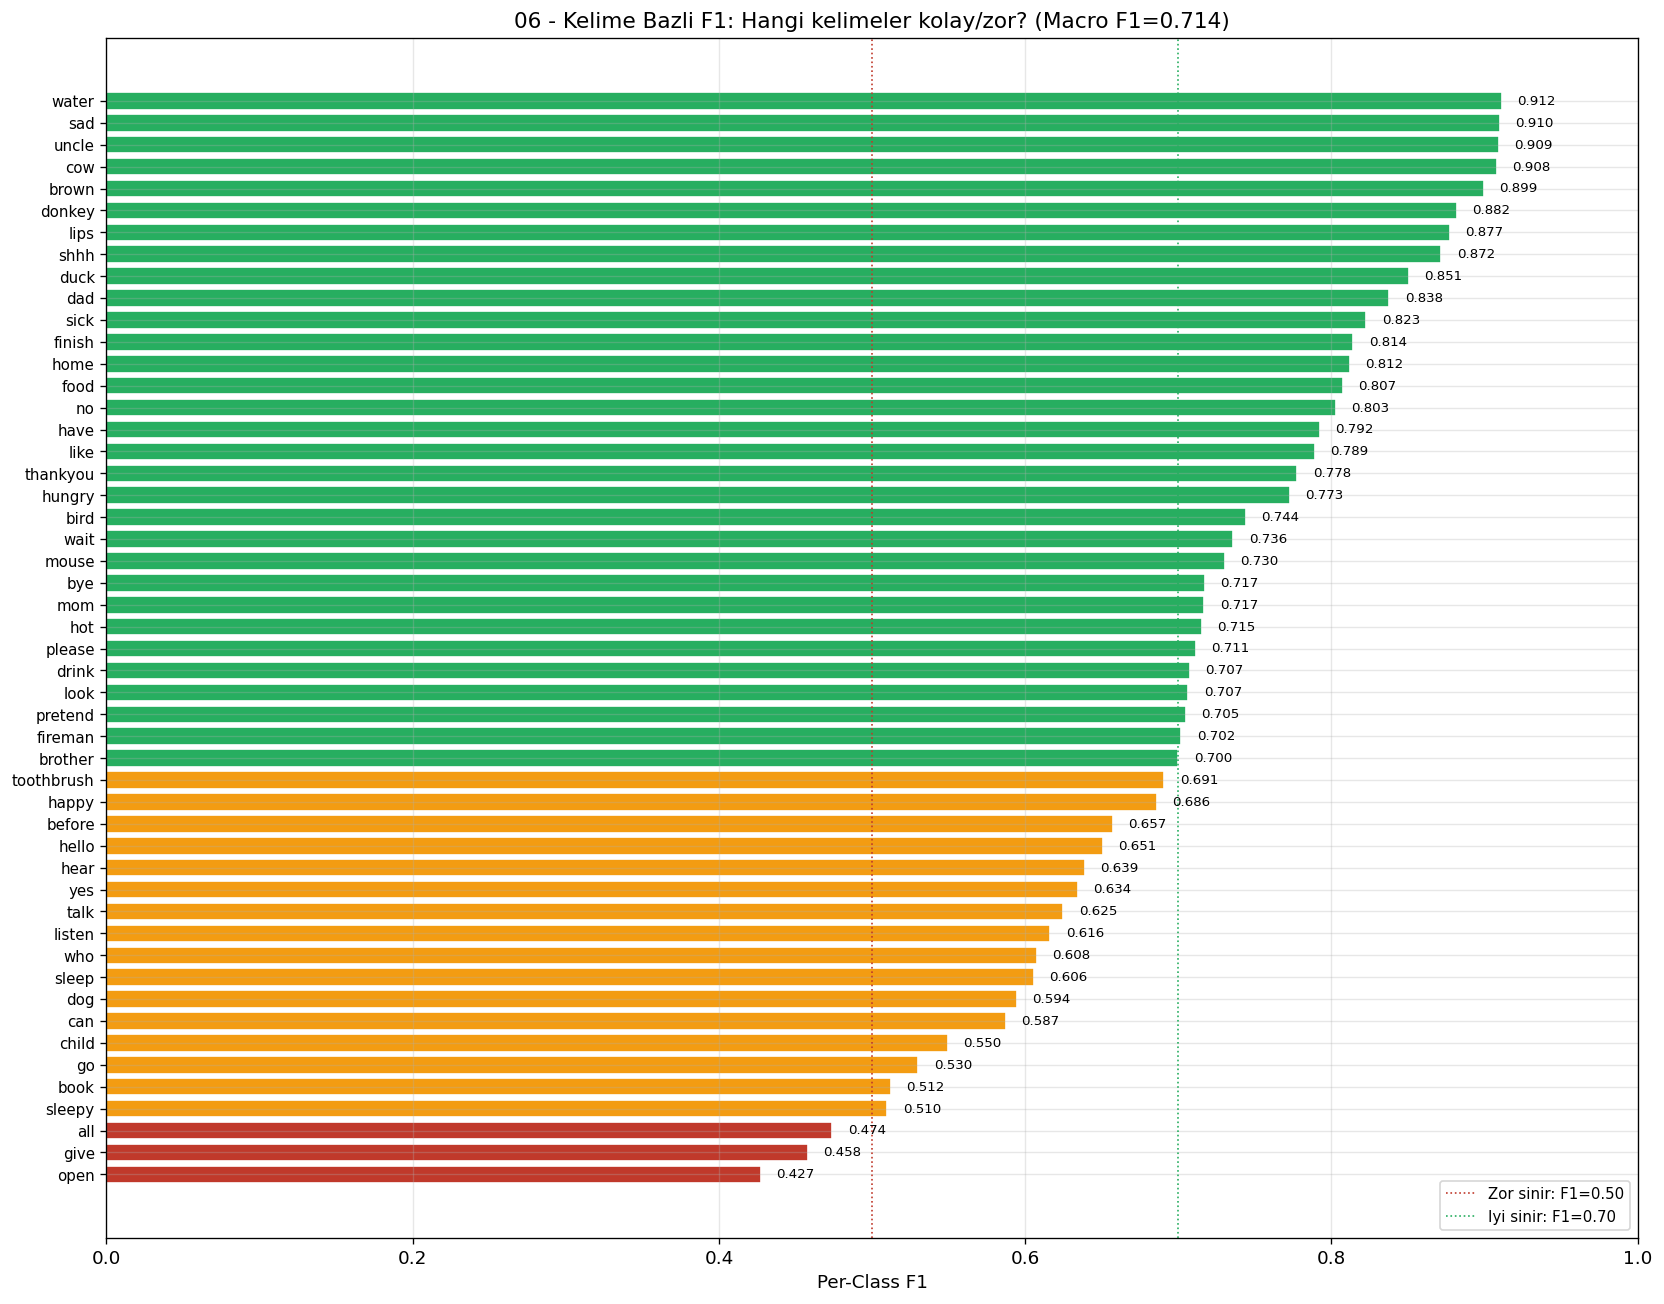

[Gorsel] 06_kelime_bazli_f1.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/06_kelime_bazli_f1.png yoluna yazildi.

06 - KELIME BAZLI F1 GRAFIGI YORUMU
------------------------------------------------------------------------
En dusuk F1 alan 5 kelime:
  open                 F1=0.427
  give                 F1=0.458
  all                  F1=0.474
  sleepy               F1=0.510
  book                 F1=0.512

En yuksek F1 alan 5 kelime:
  water                F1=0.912
  sad                  F1=0.910
  uncle                F1=0.909
  cow                  F1=0.908
  brown                F1=0.899

Kelime bazli performans yorumu:
------------------------------------------------------------------------
Anlam: Dusuk F1'li kelimeler modelin zorlandigi siniflardir; bu kelimeler icin ek veri, daha iyi referans veya ogrenme kocunda ekstra pratik gerekebilir.

En zor kelimeler: open, give, all, sleepy, book
En kolay kelimeler: brown, cow, uncle, sad, water

In [24]:
# ---------------------------------------------------------------------------
# KELIME BAZLI F1 ANALIZI
#
# Genel skor tek başına yeterli değildir. Model bazı kelimeleri çok iyi tanırken
# bazı kelimelerde zorlanabilir. Bu hücre her kelime için ayrı F1 skoru hesaplar.
#
# F1, precision ve recall değerlerini birlikte özetleyen metriktir. Kelime bazlı
# F1 düşükse model o kelimeyi ya sık kaçırıyor ya da başka kelimelerle karıştırıyor olabilir.
# Renk kodu: F1 < 0.5 kırmızı, 0.5-0.7 turuncu, > 0.7 yeşil.
# ---------------------------------------------------------------------------

# Per-class F1 hesapla
per_class_f1 = f1_score(final_true, final_preds, average=None,
                        labels=list(range(NUM_CLASSES)), zero_division=0)
report_text = classification_report(
    final_true,
    final_preds,
    labels=list(range(NUM_CLASSES)),
    target_names=SELECTED_WORDS,
    digits=4,
    zero_division=0,
)
write_text_artifact("classification_report.txt", report_text)
word_f1 = [(idx_to_word[i], per_class_f1[i]) for i in range(NUM_CLASSES)]
word_f1.sort(key=lambda x: x[1])  # En kotuden en iyiye

words_s = [w for w, _ in word_f1]
f1s_s = [f for _, f in word_f1]
colors_s = ["#c0392b" if f < 0.5 else "#f39c12" if f < 0.7 else "#27ae60"
            for f in f1s_s]

fig, ax = plt.subplots(figsize=(14, 11))
ax.barh(range(len(words_s)), f1s_s, color=colors_s, edgecolor="white")
ax.set_yticks(range(len(words_s)))
ax.set_yticklabels(words_s, fontsize=9)
ax.set_xlabel("Per-Class F1")
ax.set_title(f"06 - Kelime Bazli F1: Hangi kelimeler kolay/zor? (Macro F1={final_f1:.3f})")
ax.axvline(x=0.5, color="#c0392b", linestyle=":", linewidth=1, label="Zor sinir: F1=0.50")
ax.axvline(x=0.7, color="#27ae60", linestyle=":", linewidth=1, label="Iyi sinir: F1=0.70")
ax.legend(loc="lower right", fontsize=9)
ax.set_xlim(0, 1)
for i, f in enumerate(f1s_s):
    ax.text(f + 0.01, i, f"{f:.3f}", va="center", fontsize=8)
plt.tight_layout()
save_figure(fig, "06_kelime_bazli_f1.png")

print("\n06 - KELIME BAZLI F1 GRAFIGI YORUMU")
print("-" * 72)
print("En dusuk F1 alan 5 kelime:")
for w, f in word_f1[:5]:
    print(f"  {w:<20} F1={f:.3f}")
print("\nEn yuksek F1 alan 5 kelime:")
for w, f in word_f1[-5:][::-1]:
    print(f"  {w:<20} F1={f:.3f}")

print("\nKelime bazli performans yorumu:")
print("-" * 72)
print("Anlam: Dusuk F1'li kelimeler modelin zorlandigi siniflardir; bu kelimeler icin ek veri, daha iyi referans veya ogrenme kocunda ekstra pratik gerekebilir.")
hard_words = [w for w, f in word_f1[:5]]
easy_words = [w for w, f in word_f1[-5:]]
print(f"\nEn zor kelimeler: {', '.join(hard_words)}")
print(f"En kolay kelimeler: {', '.join(easy_words)}")
print()
print("Zor kelimelerin ortak ozelligi:")
print("  - Hizli ve kisa hareketler (az frame, az ayirt edici bilgi)")
print("  - Baska kelimelerle benzer el pozisyonu")
print("  - Yuz/govde bilgisi gerektiren ama el-odakli model kullanan kelimeler")
print()
print("Kolay kelimelerin ortak ozelligi:")
print("  - Belirgin, buyuk hareketler (genis hareket yolu)")
print("  - Diger kelimelerle karisma riski dusuk")
print("  - El sekli cok ayirt edici")


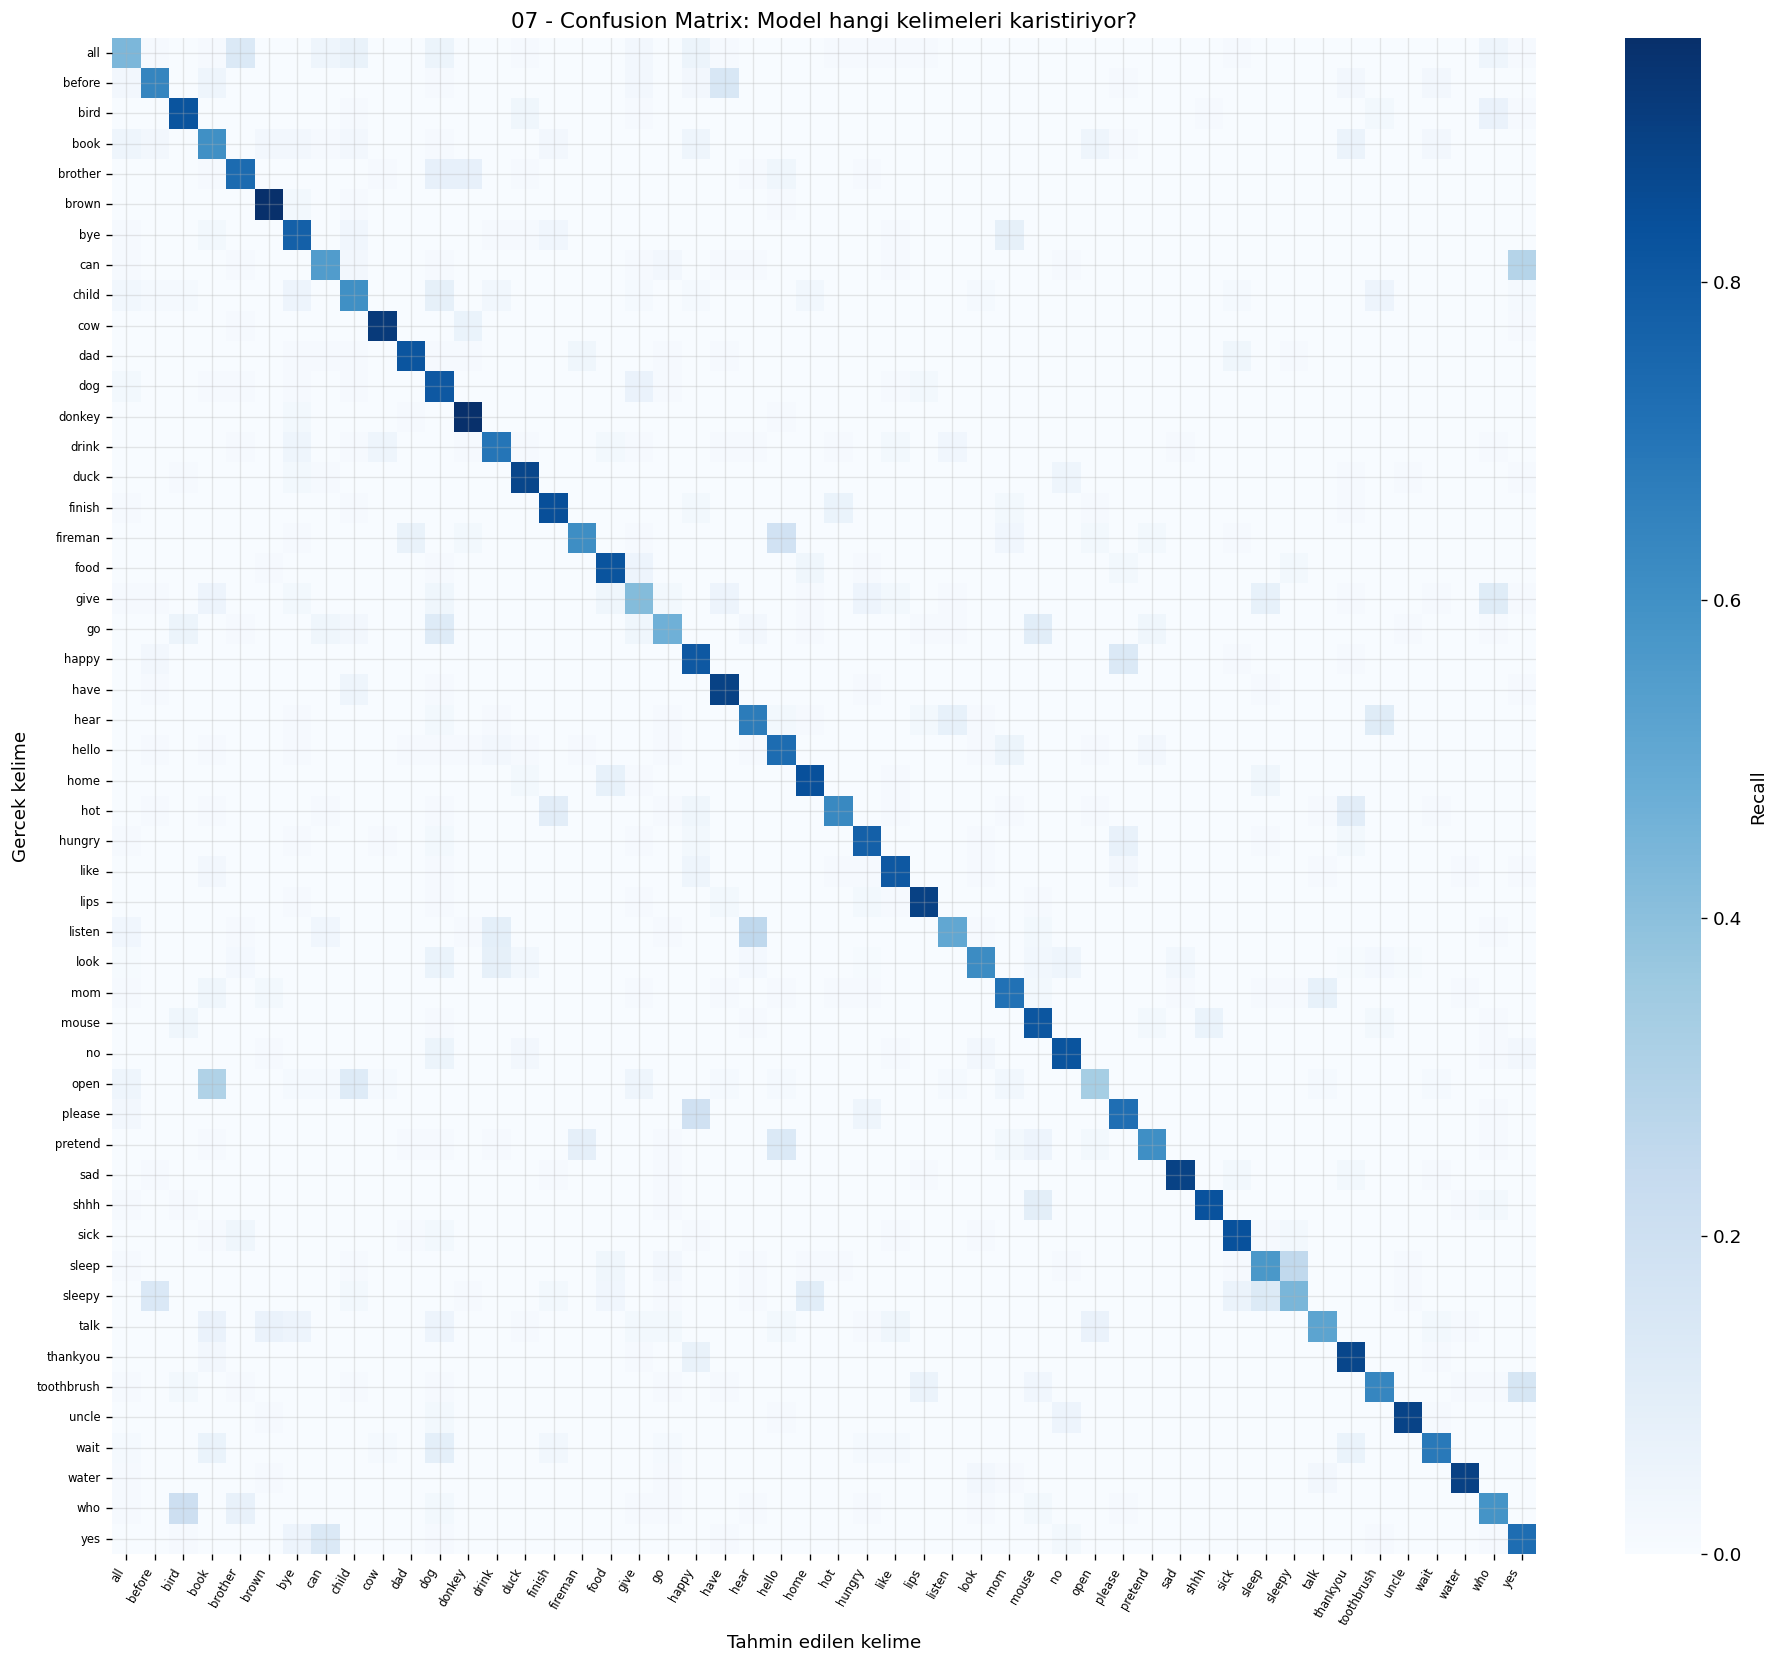

[Gorsel] 07_confusion_matrix.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/07_confusion_matrix.png yoluna yazildi.

07 - CONFUSION MATRIX GRAFIGI YORUMU
------------------------------------------------------------------------
Diyagonal hucreler dogru tahminleri, diyagonal disindaki koyu hucreler karismalari gosterir.
En cok karisan 10 kelime cifti:
  listen          -> hear            23 kez
  can             -> yes             22 kez
  open            -> book            20 kez
  sleep           -> sleepy          19 kez
  who             -> bird            17 kez
  fireman         -> hello           16 kez
  please          -> happy           14 kez
  toothbrush      -> yes             14 kez
  sleepy          -> before          12 kez
  before          -> have            11 kez

Bu bilgi web uygulamasinda nasil kullanilir?
------------------------------------------------------------------------
Karisan ciftler top-3 tahminlerde veya ogrenme 

In [25]:
# ---------------------------------------------------------------------------
# CONFUSION MATRIX
#
# Confusion matrix, gerçek kelime ile modelin tahmin ettiği kelimeyi karşılaştırır.
# Satırlar gerçek kelimeyi, sütunlar tahmin edilen kelimeyi gösterir.
# Diyagonal doğru tahminlerdir; diyagonal dışındaki koyu hücreler karışmaları gösterir.
#
# Bu analiz özellikle öğrenme koçu için yararlıdır. Eğer iki kelime sık karışıyorsa,
# web uygulaması kullanıcıya bu iki kelimeyi ayırt etmeye yönelik geri bildirim verebilir.
# ---------------------------------------------------------------------------

cm = confusion_matrix(final_true, final_preds, labels=list(range(NUM_CLASSES)))
# Row-normalize et (recall goster)
cm_norm = cm.astype(np.float32) / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_norm, cmap="Blues", annot=False, cbar_kws={"label": "Recall"},
            xticklabels=SELECTED_WORDS, yticklabels=SELECTED_WORDS, ax=ax)
ax.set_xlabel("Tahmin edilen kelime")
ax.set_ylabel("Gercek kelime")
ax.set_title("07 - Confusion Matrix: Model hangi kelimeleri karistiriyor?")
plt.xticks(rotation=60, ha="right", fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
save_figure(fig, "07_confusion_matrix.png")

# En cok karisan kelime ciftleri (off-diagonal)
print("\n07 - CONFUSION MATRIX GRAFIGI YORUMU")
print("-" * 72)
print("Diyagonal hucreler dogru tahminleri, diyagonal disindaki koyu hucreler karismalari gosterir.")
print("En cok karisan 10 kelime cifti:")
off_diag = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i][j] >= 2:
            off_diag.append((idx_to_word[i], idx_to_word[j], int(cm[i][j])))
off_diag.sort(key=lambda x: -x[2])
for wa, wb, cnt in off_diag[:10]:
    print(f"  {wa:<15} -> {wb:<15} {cnt} kez")

print("\nBu bilgi web uygulamasinda nasil kullanilir?")
print("-" * 72)
print("Karisan ciftler top-3 tahminlerde veya ogrenme kocu geri bildiriminde kullanilabilir.")
print("Ornek: Model iki kelimeyi sik karistiriyorsa arayuz bu iki secenegi kullaniciya daha acik gosterebilir.")


[JSON] word_to_idx.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.
[JSON] per_word_stats.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.
[JSON] curriculum.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.
[JSON] confusion_pairs.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.


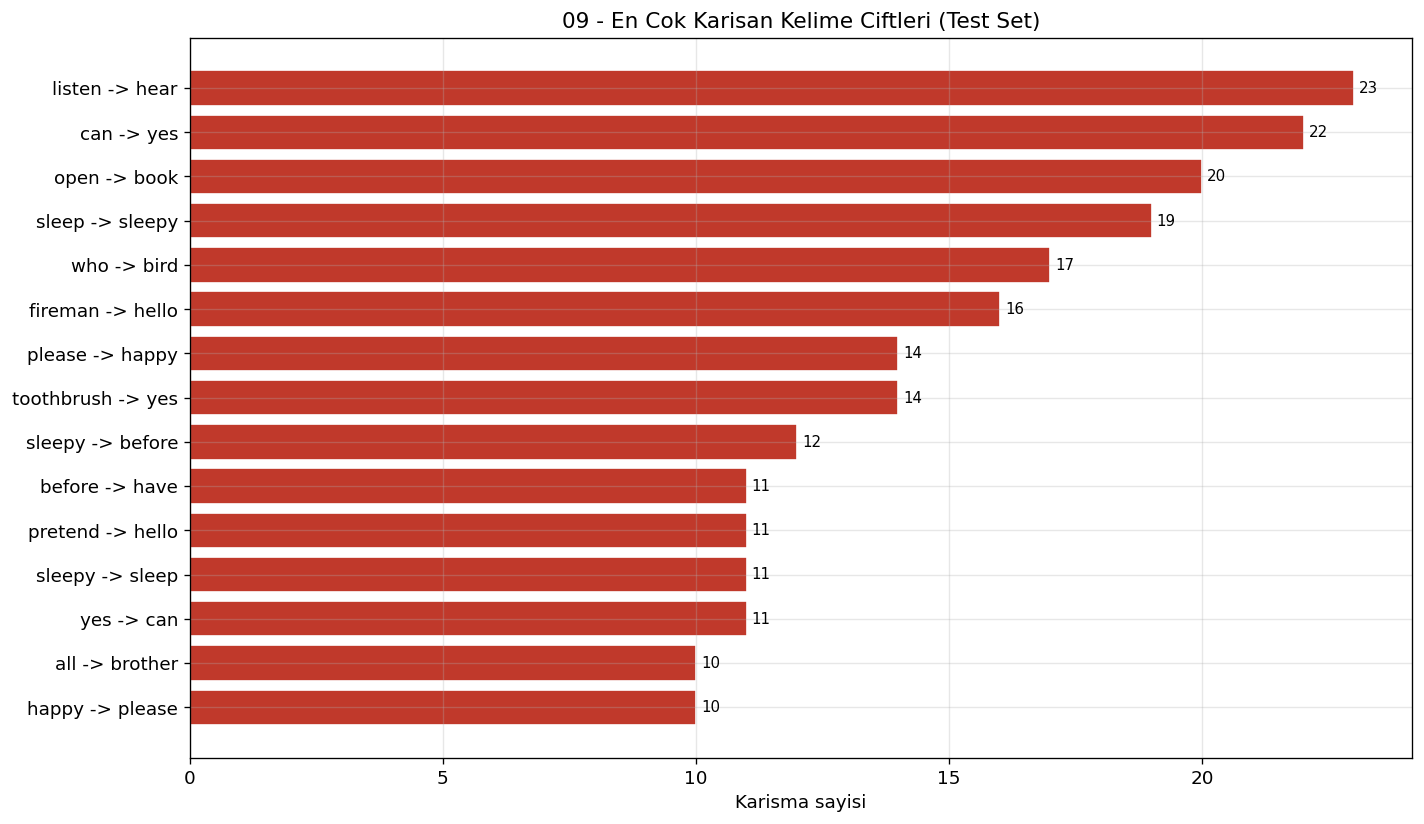

[Gorsel] 09_confusion_top_pairs.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/09_confusion_top_pairs.png yoluna yazildi.

WEB UYGULAMASI ICIN URETILEN CIKTILAR
Bu dosyalar ONNX modelin web tarafinda anlamli tahmine ve kullanici arayuzune donusmesini saglar.

  OK    word_model.onnx               1.8 MB
  OK    temperature.json              0.2 KB
  OK    word_to_idx.json              0.7 KB
  OK    per_word_stats.json           5.2 KB
  OK    curriculum.json               5.8 KB
  OK    confusion_pairs.json          2.1 KB

Cikti dosyalarinin anlami:
- word_model.onnx: Tarayicida calisacak kelime tanima modeli.
- temperature.json: Model guven skorlarini kalibre etmek icin kullanilir.
- word_to_idx.json: Model cikti indekslerini kelime etiketlerine cevirir.
- per_word_stats.json: Her kelimenin zorluk ve basari bilgisini tutar.
- curriculum.json: Ogrenme kocunda kolaydan zora siralama icin kullanilir.
- confusion_pairs.json: Sik karisan kelimele

In [26]:
# ---------------------------------------------------------------------------
# WEB ICIN CIKTI DOSYALARI
#
# ONNX modeli tahmin sırasında yalnızca sınıf skorları üretir. Web uygulamasının
# bu skorları anlamlı şekilde göstermesi için ek bilgilere ihtiyacı vardır:
# kelime indeksleri, kelime zorlukları, curriculum sırası ve karışan kelime çiftleri.
#
# Bu hücre, model dosyasının yanında kullanılacak JSON metadata dosyalarını üretir.
# Metadata, model çıktısını kullanıcı arayüzünde anlaşılır bilgiye çeviren yardımcı veridir.
# ---------------------------------------------------------------------------

# 1. Label mapping
write_json_artifact("word_to_idx.json", word_to_idx)

# 2. Kelime bazlı istatistikler.
# Bu JSON web arayüzünde kelimenin zor mu kolay mı olduğunu göstermek için kullanılır.
# Öğrenme koçu aynı bilgiyi kullanarak kullanıcıya kolaydan zora doğru pratik yaptırabilir.
per_word_stats = {}
for word in SELECTED_WORDS:
    idx = word_to_idx[word]
    # final_true == idx: test setinde bu kelimeye ait ornekleri secer.
    mask = (final_true == idx)
    if mask.sum() > 0:
        correct = float((final_preds[mask] == idx).mean())
        per_word_stats[word] = {
            "accuracy": round(correct, 3),
            "f1": round(float(per_class_f1[idx]), 3),
            "difficulty": "easy" if correct > 0.8 else "medium" if correct > 0.6 else "hard",
            "sample_count": int(mask.sum()),
        }

write_json_artifact("per_word_stats.json", per_word_stats)

# 3. Mufredat (kolay -> zor, F1 sirasina gore)
curriculum = sorted(per_word_stats.items(), key=lambda x: -x[1]["f1"])
curriculum_list = [{"word": w, **stats} for w, stats in curriculum]
write_json_artifact("curriculum.json", curriculum_list)

# 4. Karisan kelime ciftleri (en cok karisan 30)
# Confusion matrix'teki off-diagonal degerler yanlis tahminleri gosterir.
# Ornegin A kelimesi sik sik B diye tahmin ediliyorsa bu bilgi web tarafinda
# kullaniciya "su kelimeyle karisabilir" geri bildirimi vermek icin kullanilabilir.
confusing_pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i][j] >= 3:
            confusing_pairs.append({
                "word_a": idx_to_word[i],
                "word_b": idx_to_word[j],
                "count": int(cm[i][j]),
            })
confusing_pairs.sort(key=lambda x: -x["count"])
write_json_artifact("confusion_pairs.json", confusing_pairs[:30])

# Karisan kelime ciftleri icin okunabilir ek grafik
if confusing_pairs:
    top_pairs = confusing_pairs[:15]
    pair_labels = [f"{p['word_a']} -> {p['word_b']}" for p in top_pairs][::-1]
    pair_counts = [p["count"] for p in top_pairs][::-1]
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.barh(pair_labels, pair_counts, color="#c0392b", edgecolor="white")
    ax.set_xlabel("Karisma sayisi")
    ax.set_title("09 - En Cok Karisan Kelime Ciftleri (Test Set)")
    for i, count in enumerate(pair_counts):
        ax.text(count + 0.1, i, str(count), va="center", fontsize=9)
    plt.tight_layout()
    save_figure(fig, "09_confusion_top_pairs.png")
else:
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.text(0.5, 0.5, "En az 3 kez karisan kelime cifti bulunamadi.",
            ha="center", va="center", fontsize=13)
    ax.set_axis_off()
    ax.set_title("09 - En Cok Karisan Kelime Ciftleri (Test Set)")
    save_figure(fig, "09_confusion_top_pairs.png")

print("\nWEB UYGULAMASI ICIN URETILEN CIKTILAR")
print("=" * 72)
print("Bu dosyalar ONNX modelin web tarafinda anlamli tahmine ve kullanici arayuzune donusmesini saglar.\n")
output_files = [
    "word_model.onnx",
    "temperature.json",
    "word_to_idx.json",
    "per_word_stats.json",
    "curriculum.json",
    "confusion_pairs.json",
]
for fname in output_files:
    path = artifact_path(fname)
    if path.exists():
        size = path.stat().st_size
        unit = "KB" if size < 1024*1024 else "MB"
        val = size/1024 if size < 1024*1024 else size/1024/1024
        print(f"  OK    {fname:<25} {val:>7.1f} {unit}")
    else:
        print(f"  EKSIK {fname:<25} -> Bu dosya olmadan web entegrasyonu veya zip paketi eksik kalir.")

print("\nCikti dosyalarinin anlami:")
print("- word_model.onnx: Tarayicida calisacak kelime tanima modeli.")
print("- temperature.json: Model guven skorlarini kalibre etmek icin kullanilir.")
print("- word_to_idx.json: Model cikti indekslerini kelime etiketlerine cevirir.")
print("- per_word_stats.json: Her kelimenin zorluk ve basari bilgisini tutar.")
print("- curriculum.json: Ogrenme kocunda kolaydan zora siralama icin kullanilir.")
print("- confusion_pairs.json: Sik karisan kelimeleri arayuz geri bildirimi icin saklar.")


## Bolum E: Deney Raporu ve Cikti Ozeti

Bu bolum, deneylerin sonucunu tek yerde toplar. Buradaki amac yalnizca final skoru vermek degil; final modele giden karar zincirini ve her adimin gerekcesini gostermektir.

### Karar Zinciri

| Kategori | Deney Sayisi | Soru | Cevap |
|---|---:|---|---|
| Feature Muhendisligi | 6 | Hangi veri temsili daha iyi? | Bolum A validation F1 kazanani |
| Sekans Uzunlugu | 3 | Kac frame ve hangi sampling? | Bolum B validation F1 kazanani |
| Model Mimarisi | 4 + 1 ensemble | Hangi model daha uygun? | En iyi single model |
| Full Training | 1 | Final model nasil egitilmeli? | 100 epoch + progressive augmentation |

### Neden Bu Bolum Onemli?

Bu bolum deney raporu mantigini saglar. Her karar tek tek olculur ve sonra final modele aktarilir. Boylece modelin sonucu sans eseri degil, kontrollu deneylerin sonucudur.

Onceki 34 kelimelik feature ablasyonu sadece motivasyon olarak anilir. Bu notebook'un urettigi feature, sekans, model, final egitim, kalibrasyon, ONNX export ve zip sonuclari ayni 50 kelimelik run'a aittir.

**Degerlendirme notu:** Tum ara secimler validation F1 ile yapilmistir. Test seti karar vermek icin kullanilmaz; raporlama ve final degerlendirme icin ayrilir.


In [27]:
# ---------------------------------------------------------------------------
# BUYUK KARSILASTIRMA TABLOSU
# 4 kategori: Feature / Sekans / Model / Final.
# ---------------------------------------------------------------------------

print("=" * 78)
print("TUM DENEY SONUCLARI OZETI")
print("=" * 78)
print("Bu tablo feature, sekans, model ve final egitim kararlarini tek yerde toplar.")
print("Ana okuma: Her adim validation F1 ile secildi; test skorlari raporlama icindir.\n")

# --- KATEGORI 1: Feature Engineering (Bolum A) ---
print("\n[1] FEATURE MUHENDISLIGI SONUCLARI (Bolum A, BiGRU, 30 frame)")
print("-" * 78)
print(f"{'Feature Set':<30} {'Boyut':>8} {'Val F1':>10} {'Test F1':>10} {'Not':>10}")
print("-" * 78)
for r in feature_results:
    note = "[SECILEN]" if r["name"] == BEST_FEATURE_NAME else ""
    print(f"{r['name']:<30} {r['feature_dim']:>8}D {r.get('best_val_f1', -1):>10.3f} {r.get('test_f1', 0):>10.3f}  {note}")

# --- KATEGORI 2: Sekans Uzunlugu (Bolum B) ---
print(f"\n[2] SEKANS UZUNLUGU SONUCLARI (Bolum B, BiGRU, {QUICK_EPOCHS} epoch)")
print("-" * 78)
print(f"{'Strateji':<30} {'Seq Len':>8} {'Val F1':>10} {'Test F1':>10} {'Not':>10}")
print("-" * 78)
for r in seq_results:
    note = "[SECILEN]" if r["name"] == best_seq["name"] else ""
    seq_dim = "45+mask" if r["name"] == "padmask45" else "30"
    print(f"{r['name']:<30} {seq_dim:>8} {r.get('best_val_f1', -1):>10.3f} {r['test_f1']:>10.3f}  {note}")

# --- KATEGORI 3: Model Mimarisi (Bolum C) ---
print(f"\n[3] MODEL MIMARISI SONUCLARI (Bolum C, {QUICK_EPOCHS} epoch, {best_seq_name})")
print("-" * 78)
print(f"{'Model':<30} {'Param':>10} {'Val F1':>10} {'Test F1':>10} {'Not':>10}")
print("-" * 78)
for r in model_results:
    note = "[SECILEN]" if r["name"] == best_model_result["name"] else ""
    print(f"{r['name']:<30} {r['params']:>10,} {r.get('best_val_f1', -1):>10.3f} {r['test_f1']:>10.3f}  {note}")

# --- KATEGORI 4: Final Model (Bolum D) ---
print(f"\n[4] FINAL MODEL (Bolum D, {FULL_EPOCHS} epoch, progressive aug)")
print("-" * 78)
print(f"  Feature:        {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D)")
print(f"  Model:          {FINAL_MODEL_NAME}")
print(f"  Sekans:         {best_seq_name}")
print(f"  Parametre:      {final_params:,}")
print(f"  Test Accuracy:  {final_acc:.4f}")
print(f"  Test F1:        {final_f1:.4f}")
print(f"  Best Val F1:    {final_best_f1:.4f}")
print(f"  Temperature:    {optimal_T:.4f}")
print(f"  ONNX boyutu:    {onnx_size_mb:.2f} MB")

# --- TOPLAM OZET ---
total_exp = len(feature_results) + len(seq_results) + len(model_results) + 1
baseline_result = next((r for r in feature_results if r["name"] == "1A_baseline"), feature_results[0])
baseline_f1 = baseline_result.get("best_val_f1", 0)
improvement = (final_best_f1 - baseline_f1) * 100

print(f"\n{'='*78}")
print(f"  Toplam sistematik deney: {total_exp}")
print(f"  Baseline Val F1 (Bolum A 1A): {baseline_f1:.3f}")
print(f"  Final Best Val F1:            {final_best_f1:.3f}")
print(f"  Validation iyilesmesi:        {improvement:+.1f} puan")
print(f"{'='*78}")

print("\n" + "=" * 70)
print("GENEL DEGERLENDIRME")
print("=" * 70)
print()
print("Anahtar Bulgular:")
print(f"  1. Feature secimi validation F1 ile yapildi; kazanan {BEST_FEATURE_NAME} oldu.")
print("     Bu karar test setine bakmadan verildigi icin leakage riski azalir.")
print()
print("  2. Sekans uzunlugu stratejisi feature kadar temel olmasa da")
print("     web tarafindaki kayit akisini ve model input seklini belirler.")
print()
print("  3. Model mimarisi secimi veri boyutuna baglidir.")
print("     Kucuk/orta veri setinde GRU tabanli modeller Transformer'dan daha stabil olabilir.")
print()
print("  4. Progressive augmentation final egitimde canli kamera farkliliklarina")
print("     dayaniklilik kazandirmak icin kontrollu sekilde kullanildi.")
print()
print("Sonuc: Tum ara secimler validation F1 ile yapildi; test seti raporlama ve final degerlendirme icin ayrildi.")


TUM DENEY SONUCLARI OZETI
Bu tablo feature, sekans, model ve final egitim kararlarini tek yerde toplar.
Ana okuma: Her adim validation F1 ile secildi; test skorlari raporlama icindir.


[1] FEATURE MUHENDISLIGI SONUCLARI (Bolum A, BiGRU, 30 frame)
------------------------------------------------------------------------------
Feature Set                       Boyut     Val F1    Test F1        Not
------------------------------------------------------------------------------
1A_baseline                         321D      0.670      0.581  
1B_pw_dom                           444D      0.770      0.671  
1C_shape                             72D      0.715      0.613  
1D_shape_motion                     132D      0.714      0.621  
1E_compact                          168D      0.788      0.699  [SECILEN]
1F_full                             519D      0.740      0.639  

[2] SEKANS UZUNLUGU SONUCLARI (Bolum B, BiGRU, 25 epoch)
----------------------------------------------------------------

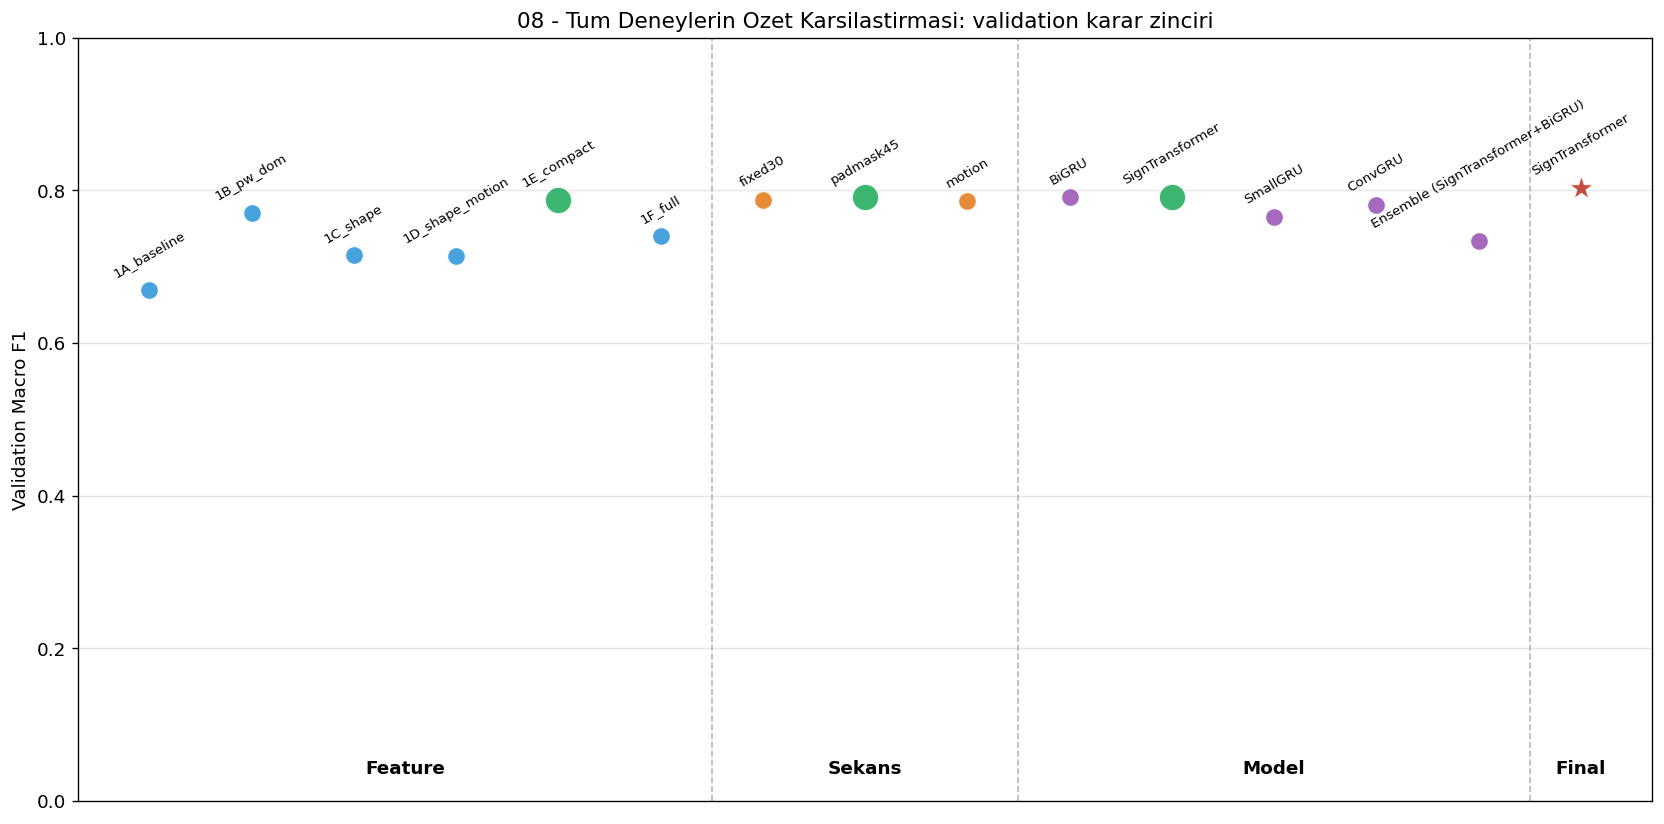

[Gorsel] 08_tum_deneyler_ozet.png kaydedildi.
         Anlam: Bu PNG rapor/zip paketi icin uretildi ve /kaggle/working/08_tum_deneyler_ozet.png yoluna yazildi.

08 - TUM DENEYLER OZET GRAFIGI YORUMU
------------------------------------------------------------------------
Bu grafik feature, sekans, model ve final egitim sonuclarini kategori bazinda gosterir.
Anlam: X ekseni artik karisik olcekler kullanmaz; her nokta ayri bir deneyi temsil eder.
Yesil noktalar o kategoride validation F1 ile secilen kararlari, final yildiz ise uzun egitim sonucunu gosterir.


In [28]:
# ---------------------------------------------------------------------------
# TUM DENEYLERIN OZET SCATTER PLOT'U
# X = deney indeksi, kategoriye gore gruplanmis.
# Bu grafik farkli olcekleri (feature dim, parametre) tek X ekseninde karistirmaz.
# ---------------------------------------------------------------------------

summary_points = []

for result in feature_results:
    summary_points.append({
        "category": "Feature",
        "name": result["name"],
        "score": result.get("best_val_f1", 0),
        "selected": result["name"] == BEST_FEATURE_NAME,
    })
for result in seq_results:
    summary_points.append({
        "category": "Sekans",
        "name": result["name"],
        "score": result.get("best_val_f1", 0),
        "selected": result["name"] == best_seq["name"],
    })
for result in model_results:
    summary_points.append({
        "category": "Model",
        "name": result["name"],
        "score": result.get("best_val_f1", 0),
        "selected": result["name"] == best_model_result["name"],
    })
summary_points.append({
    "category": "Final",
    "name": FINAL_MODEL_NAME,
    "score": final_best_f1,
    "selected": True,
})

category_colors = {
    "Feature": "#3498db",
    "Sekans": "#e67e22",
    "Model": "#9b59b6",
    "Final": "#c0392b",
}

fig, ax = plt.subplots(figsize=(14, 7))

x_positions = np.arange(len(summary_points))
for x_position, point in zip(x_positions, summary_points):
    marker = "*" if point["category"] == "Final" else "o"
    point_size = 260 if point["selected"] else 120
    color = "#27ae60" if point["selected"] and point["category"] != "Final" else category_colors[point["category"]]
    ax.scatter(x_position, point["score"], s=point_size, c=color, edgecolor="white",
               alpha=0.9, marker=marker, zorder=3)
    ax.annotate(point["name"], (x_position, point["score"]), fontsize=8,
                xytext=(0, 8), textcoords="offset points", ha="center", rotation=30)

# Kategori ayirici cizgiler ve etiketler.
category_ranges = []
start_index = 0
while start_index < len(summary_points):
    category_name = summary_points[start_index]["category"]
    end_index = start_index
    while end_index + 1 < len(summary_points) and summary_points[end_index + 1]["category"] == category_name:
        end_index += 1
    category_ranges.append((category_name, start_index, end_index))
    start_index = end_index + 1

for category_name, start_index, end_index in category_ranges:
    center = (start_index + end_index) / 2
    ax.text(center, 0.03, category_name, ha="center", va="bottom", fontsize=11, fontweight="bold",
            transform=ax.get_xaxis_transform())
    if end_index < len(summary_points) - 1:
        ax.axvline(end_index + 0.5, color="#7f8c8d", linestyle="--", linewidth=1, alpha=0.6)

ax.set_xticks([])
ax.set_ylabel("Validation Macro F1")
ax.set_title("08 - Tum Deneylerin Ozet Karsilastirmasi: validation karar zinciri")
ax.set_ylim(0, 1)
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
save_figure(fig, "08_tum_deneyler_ozet.png")

print("\n08 - TUM DENEYLER OZET GRAFIGI YORUMU")
print("-" * 72)
print("Bu grafik feature, sekans, model ve final egitim sonuclarini kategori bazinda gosterir.")
print("Anlam: X ekseni artik karisik olcekler kullanmaz; her nokta ayri bir deneyi temsil eder.")
print("Yesil noktalar o kategoride validation F1 ile secilen kararlari, final yildiz ise uzun egitim sonucunu gosterir.")


In [29]:
# ---------------------------------------------------------------------------
# TUM SONUCLARI JSON OLARAK KAYDET
#
# Bu hücre deney sonuçlarını makine-okunur bir JSON dosyasına yazar.
# JSON, web uygulaması ve rapor üretimi için uygun bir veri formatıdır.
# Böylece skorlar, seçilen kelimeler, model ayarları ve final metrikler tek dosyada saklanır.
# ---------------------------------------------------------------------------

def serialize(r):
    """Deney sonucunu JSON'a yazılabilir sözlüğe çevirir.

    PyTorch model nesnesi, tensor ve numpy array gibi yapılar doğrudan JSON'a yazılamaz.
    Bu fonksiyon yalnızca raporda ve web tarafında gerekli olan sayısal/metinsel
    alanları alır. Böylece sonuç dosyası küçük, okunabilir ve tekrar kullanılabilir olur.
    """
    return {
        "name": r.get("name"),
        "params": int(r.get("params", 0)),
        "best_val_f1": float(r.get("best_val_f1", 0)),
        "best_val_acc": float(r.get("best_val_acc", 0)),
        "best_epoch": int(r.get("best_epoch", 0)),
        "test_acc": float(r.get("test_acc", 0)),
        "test_f1": float(r.get("test_f1", 0)),
        "minutes": float(r.get("minutes", 0)),
        "history": r.get("history"),  # dict of lists - zaten JSON-safe
    }

all_results = {
    "feature_ablation": [
        {
            "name": r["name"],
            "feature_dim": int(r["feature_dim"]),
            "best_val_f1": float(r.get("best_val_f1", 0)),
            "best_val_acc": float(r.get("best_val_acc", 0)),
            "test_acc": float(r.get("test_acc", 0)),
            "test_f1": float(r.get("test_f1", 0)),
            "minutes": float(r.get("minutes", 0)),
        }
        for r in feature_results
    ],
    "bolum_b_sequence": [serialize(r) for r in seq_results],
    "bolum_c_models": [serialize(r) for r in model_results],
    "final_model": {
        "model_name": FINAL_MODEL_NAME,
        "seq_strategy": best_seq_name,
        "feature_dim": BEST_FEATURE_DIM,
        "seq_len": seq_len_final,
        "has_mask": has_mask,
        "params": int(final_params),
        "test_acc": float(final_acc),
        "test_f1": float(final_f1),
        "best_val_f1": float(final_best_f1),
        "temperature": float(optimal_T),
        "ece_before": float(ece_before),
        "ece_after": float(ece_after),
        "onnx_size_mb": float(onnx_size_mb),
        "history": final_history,
        "epochs_trained": len(final_history["train_loss"]),
    },
    "metadata": {
        "num_classes": NUM_CLASSES,
        "selected_words": SELECTED_WORDS,
        "train_signers": len(train_signers),
        "val_signers": len(val_signers),
        "test_signers": len(test_signers),
        "train_samples": int(len(train_labels)),
        "val_samples": int(len(val_labels)),
        "test_samples": int(len(test_labels)),
        "seed": SEED,
    },
}

write_json_artifact("all_experiment_results.json", all_results)

print("\nTUM DENEY SONUCLARI JSON OLARAK KAYDEDILDI")
print("-" * 72)
print(f"Dosya: {artifact_path('all_experiment_results.json')}")
print("Anlam: Bu dosya tum deney skorlarini makine-okunur sekilde saklar; rapor, grafik veya web tarafinda tekrar okunabilir.")
print("Icerik ozeti:")
print(f"  - {len(all_results['feature_ablation'])} feature deneyi")
print(f"  - {len(all_results['bolum_b_sequence'])} sekans deneyi")
print(f"  - {len(all_results['bolum_c_models'])} model deneyi")
print(f"  - 1 final model kaydi")


[JSON] all_experiment_results.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.

TUM DENEY SONUCLARI JSON OLARAK KAYDEDILDI
------------------------------------------------------------------------
Dosya: /kaggle/working/all_experiment_results.json
Anlam: Bu dosya tum deney skorlarini makine-okunur sekilde saklar; rapor, grafik veya web tarafinda tekrar okunabilir.
Icerik ozeti:
  - 6 feature deneyi
  - 3 sekans deneyi
  - 5 model deneyi
  - 1 final model kaydi


In [30]:
# ---------------------------------------------------------------------------
# TEK ZIP EXPORT PAKETI
#
# Kaggle run sonunda indirilecek ana teslim dosyası bu hücrede oluşturulur.
# Zip paketine yalnızca beklenen dosyalar eklenir. Buna whitelist yaklaşımı denir.
# Whitelist, "sadece bu listedeki dosyaları kabul et" anlamına gelir.
#
# Bu kontrol önemlidir çünkü Kaggle çalışma klasöründe eski run'lardan kalan PNG,
# JSON veya model dosyaları bulunabilir. Paketleme listesi sabit tutulduğu için
# eski veya alakasız dosyalar export paketine karışmaz.
# ---------------------------------------------------------------------------

zip_path = artifact_path(ZIP_NAME)

# Manifest daha sonra olusturulacagi icin ilk kontrolde manifest yoktur.
# Once model, JSON, rapor ve grafiklerin tamamlandigindan emin oluruz.
model_export_files = ["final_model.pt"]
if artifact_path("word_model.onnx").exists():
    model_export_files.insert(0, "word_model.onnx")
else:
    print("UYARI: word_model.onnx bulunamadi; zip PyTorch .pt yedegiyle olusturulacak.")

required_before_manifest = [
    *model_export_files,
    "temperature.json",
    "word_to_idx.json",
    "per_word_stats.json",
    "curriculum.json",
    "confusion_pairs.json",
    "all_experiment_results.json",
    "classification_report.txt",
    *FIGURE_FILES,
]

# Zip olusturmadan once tum zorunlu dosyalar var mi kontrol edilir.
# Eksik dosya varsa zip uretilmez; boylece eksik paketi yanlislikla indirmeyiz.
missing = [fname for fname in required_before_manifest if not artifact_path(fname).exists()]
if missing:
    raise RuntimeError(
        "Zip olusturulamadi. Eksik cikti dosyalari: " + ", ".join(missing)
    )

readme_text = f"""ASL Word Model Export Package
=============================

Bu zip dosyasi word_50_training.ipynb Kaggle run'i sonunda otomatik uretilir.
Tum dosyalar ayni run'a aittir; zip whitelist ile olusturuldugu icin eski/yanlis PNG dosyalari eklenmez.

Final model
-----------
- Model: {FINAL_MODEL_NAME}
- Sekans stratejisi: {best_seq_name}
- Feature: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D)
- Sekans uzunlugu: {seq_len_final}
- Mask input: {has_mask}
- Test accuracy: {final_acc:.4f}
- Test macro F1: {final_f1:.4f}
- Best val F1: {final_best_f1:.4f}
- Temperature T: {optimal_T:.4f}
- ONNX boyutu: {onnx_size_mb:.2f} MB
- ONNX export: {"var" if artifact_path("word_model.onnx").exists() else "atlanmis"}

Metriklerin kisa yorumu
-----------------------
- Test macro F1: 50 kelimeyi esit agirlikta degerlendirir; ana karar metrigidir.
- Test accuracy: Genel dogruluk oranidir; kelime bazli zorluklari tek basina gostermez.
- Best val F1: Egitim sirasinda en iyi model agirliginin secildigi noktayi gosterir.
- Temperature T: Model guven skorlarini daha gercekci yapmak icin kullanilir.
- ECE: Guven skoru ile gercek dogruluk arasindaki farki olcer; dusmesi olumlu kabul edilir.

Web entegrasyonu
----------------
1. word_model.onnx varsa ONNX Runtime Web ile yukle; yoksa ONNX export adimini internet olan ortamda tekrar calistir.
2. MediaPipe landmark ciktisindan her frame icin secilen feature builder mantigini uygula: {BEST_FEATURE_NAME} ({BEST_FEATURE_DIM}D).
3. Kelime modu icin secilen sekans uzunlugunda frame hazirla; padmask45 kazanirsa mask input'u da verilir.
4. ONNX model ham skorlar, yani logits uretir.
5. Logits cikisini temperature.json icindeki T ile kalibre et: logits / T.
6. Softmax ile kelime olasiliklarini hesapla.
7. word_to_idx.json ile cikti indekslerini kelimeye cevir.
8. per_word_stats.json, curriculum.json ve confusion_pairs.json web tarafinda UI/coach geri bildirimi icin kullanilir.

Dosya gruplari
--------------
- Model: {", ".join(model_export_files)}
- Web JSON: temperature.json, word_to_idx.json, per_word_stats.json, curriculum.json, confusion_pairs.json
- Rapor JSON/metin: all_experiment_results.json, classification_report.txt, manifest.json
- Grafikler: {', '.join(FIGURE_FILES)}

Grafiklerin anlami
------------------
01_kelime_dagilimi.png: Secilen 50 kelimenin ornek sayilarini gosterir. Veri dengesi buradan okunur.
02_sekans_uzunluk.png: Videolarin frame uzunlugunu gosterir. Sekans stratejisi kararina dayanak olur.
03_feature_ablasyonu.png: 6 feature setinin validation ve test F1 sonuclarini gosterir.
03_sekans_karsilastirma.png: fixed30, padmask45 ve motion stratejilerini karsilastirir.
04_model_karsilastirma.png: Model F1, parametre, egitim egrisi ve inference hizi bilgilerini birlikte gosterir.
05_full_training_egrileri.png: Final egitimde loss ve validation metriklerinin gidisatini gosterir.
06_kelime_bazli_f1.png: Hangi kelimelerin kolay veya zor oldugunu gosterir.
07_confusion_matrix.png: Hangi kelimenin hangi kelimeyle karistigini gosterir.
08_tum_deneyler_ozet.png: Deney zincirinin genel etkisini tek grafikte ozetler.
09_confusion_top_pairs.png: En cok karisan kelime ciftlerini okunabilir liste olarak gosterir.
"""
write_text_artifact("README_EXPORT.txt", readme_text)

package_files = [
    *model_export_files,
    "temperature.json",
    "word_to_idx.json",
    "per_word_stats.json",
    "curriculum.json",
    "confusion_pairs.json",
    "all_experiment_results.json",
    "classification_report.txt",
    "README_EXPORT.txt",
    *FIGURE_FILES,
]

if len(package_files) != len(set(package_files)):
    duplicates = sorted({fname for fname in package_files if package_files.count(fname) > 1})
    raise RuntimeError("Zip dosya listesinde tekrar var: " + ", ".join(duplicates))

# Manifest, zip içindeki dosyaların kontrol listesidir.
# Her dosya için ad, boyut ve sha256 özeti saklanır.
# sha256, dosyanın parmak izi gibi düşünülebilir: dosya değişirse bu özet de değişir.
# Bu nedenle paket indirildikten sonra dosyaların eksik veya bozuk olup olmadığı kontrol edilebilir.
manifest_entries = []
for fname in package_files:
    path = artifact_path(fname)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    manifest_entries.append({
        "filename": fname,
        "size_bytes": path.stat().st_size,
        "sha256": digest,
    })

manifest = {
    "zip_name": ZIP_NAME,
    "created_at_unix": int(time.time()),
    "output_dir": str(OUTPUT_DIR),
    "num_files": len(package_files) + 1,
    "model_name": FINAL_MODEL_NAME,
    "sequence_strategy": best_seq_name,
    "feature_dim": BEST_FEATURE_DIM,
    "sequence_length": seq_len_final,
    "has_mask": has_mask,
    "test_acc": float(final_acc),
    "test_f1": float(final_f1),
    "temperature": float(optimal_T),
    "files": manifest_entries,
}
write_json_artifact("manifest.json", manifest)
package_files.append("manifest.json")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    added = set()
    for fname in package_files:
        if fname in added:
            raise RuntimeError(f"Zip tekrar eden entry engellendi: {fname}")
        # arcname=fname, zip içindeki dosya adını temiz tutar.
        # Böylece zip içinde /kaggle/working/... gibi makineye özel yol bilgisi görünmez.
        # Paketi açan kişi doğrudan word_model.onnx, temperature.json gibi dosya adlarını görür.
        zf.write(artifact_path(fname), arcname=fname)
        added.add(fname)

size = zip_path.stat().st_size / 1024**2
print("=" * 72)
print("FINAL ZIP PAKETI OLUSTURULDU")
print("=" * 72)
print(f"Zip yolu: {zip_path}")
print(f"Zip boyutu: {size:.1f} MB")
print(f"Icerik: {len(package_files)} dosya")
print("Anlam: Kaggle'dan indirilecek asil export paketi budur; model, JSON, rapor ve tum grafikler bu dosyanin icindedir.")
print("\nZip dosya listesi:")
for fname in package_files:
    path = artifact_path(fname)
    unit = "KB" if path.stat().st_size < 1024**2 else "MB"
    val = path.stat().st_size / 1024 if unit == "KB" else path.stat().st_size / 1024**2
    print(f"  {fname:<35} {val:>8.1f} {unit}")

print("\nPaket kontrolu:")
print("- Eksik dosya varsa bu hucre zip olusturmadan hata verir.")
print("- Tekrar eden dosya adi varsa paketleme durdurulur.")
print("- manifest.json her dosyanin boyutunu ve sha256 ozetini saklar.")
print("- README_EXPORT.txt paketi acan kisi icin model, grafik ve web kullanim aciklamalarini icerir.")


[Metin] README_EXPORT.txt kaydedildi.
        Anlam: Bu dosya zip icinde okunabilir rapor/aciklama olarak yer alacak.
[JSON] manifest.json kaydedildi.
       Anlam: Web uygulamasi veya final rapor bu yapilandirilmis dosyayi kullanacak.
FINAL ZIP PAKETI OLUSTURULDU
Zip yolu: /kaggle/working/asl_word_model_outputs.zip
Zip boyutu: 5.0 MB
Icerik: 21 dosya
Anlam: Kaggle'dan indirilecek asil teslim paketi budur; model, JSON, rapor ve tum grafikler bu dosyanin icindedir.

Zip dosya listesi:
  word_model.onnx                          1.8 MB
  final_model.pt                           1.7 MB
  temperature.json                         0.2 KB
  word_to_idx.json                         0.7 KB
  per_word_stats.json                      5.2 KB
  curriculum.json                          5.8 KB
  confusion_pairs.json                     2.1 KB
  all_experiment_results.json             36.5 KB
  classification_report.txt                2.8 KB
  README_EXPORT.txt                        3.2 KB
  01_kelime

In [31]:
# ---------------------------------------------------------------------------
# DINAMIK FINAL OZET
# Bu hucre Kaggle run'i sonunda gercek metriklerle okunabilir ozet uretir.
# ---------------------------------------------------------------------------

from IPython.display import Markdown, display

onnx_status_text = "word_model.onnx" if artifact_path("word_model.onnx").exists() else "final_model.pt (ONNX export atlandi)"

final_summary_md = f"""
## Dinamik Final Ozet

### Kazanan Kombinasyon

| Bilesen | Secim | Kaynak |
|---|---|---|
| Feature | `{BEST_FEATURE_NAME}` ({BEST_FEATURE_DIM}D) | Bolum A feature ablasyonu |
| Sekans | `{best_seq_name}` | Bolum B sekans deneyleri |
| Model | `{FINAL_MODEL_NAME}` | Bolum C model karsilastirmasi |
| Egitim | {len(final_history['train_loss'])} epoch, progressive augmentation | Bolum D final egitim |

### Final Metrikler

| Metrik | Deger |
|---|---:|
| Test Accuracy | {final_acc:.4f} |
| Test Macro F1 | {final_f1:.4f} |
| Best Val F1 | {final_best_f1:.4f} |
| Temperature T | {optimal_T:.4f} |
| ONNX Boyutu | {onnx_size_mb:.2f} MB |
| Zip Dosyasi | `{zip_path.name}` |

### Yorum

Final karar zincirinde tum ara secimler validation F1 ile yapildi; test seti sadece final degerlendirme ve raporlama icin kullanildi. Once feature temsilini sabitledik, sonra sekans stratejisini ve model mimarisini kontrollu deneylerle sectik. Web tarafinda kullanilacak ana model dosyasi `{onnx_status_text}`; guven skorlari `temperature.json` ile kalibre edilir. Tum model, grafik, JSON ve rapor ciktilari tek zip paketinde hazirdir: `{zip_path}`. Sinirlamalar: tek seed kullanildi, signer havuzu 21 kisi ile sinirli ve gercek dunyada daha dusuk performans beklenebilir.
"""

display(Markdown(final_summary_md))



## Dinamik Final Ozet

### Kazanan Kombinasyon

| Bilesen | Secim | Kaynak |
|---|---|---|
| Feature | `1E_compact` (168D) | Bolum A feature ablasyonu |
| Sekans | `padmask45` | Bolum B sekans deneyleri |
| Model | `SignTransformer` | Bolum C model karsilastirmasi |
| Egitim | 63 epoch, progressive augmentation | Bolum D final egitim |

### Final Metrikler

| Metrik | Deger |
|---|---:|
| Test Accuracy | 0.7192 |
| Test Macro F1 | 0.7140 |
| Best Val F1 | 0.8029 |
| Temperature T | 0.9854 |
| ONNX Boyutu | 1.77 MB |
| Zip Dosyasi | `asl_word_model_outputs.zip` |

### Yorum

Final karar zincirinde tum ara secimler validation F1 ile yapildi; test seti sadece final degerlendirme ve raporlama icin kullanildi. Once feature temsilini sabitledik, sonra sekans stratejisini ve model mimarisini kontrollu deneylerle sectik. Web tarafinda kullanilacak ana model dosyasi `word_model.onnx`; guven skorlari `temperature.json` ile kalibre edilir. Tum model, grafik, JSON ve rapor ciktilari tek zip paketinde hazirdir: `/kaggle/working/asl_word_model_outputs.zip`. Sinirlamalar: tek seed kullanildi, signer havuzu 21 kisi ile sinirli ve gercek dunyada daha dusuk performans beklenebilir.


## Final Ozet ve Kaggle Ciktisi

Notebook tamamlandiginda indirilecek asil dosya **`asl_word_model_outputs.zip`** dosyasidir. Bu dosya Kaggle'da `/kaggle/working` klasorunde olusur.

Zip paketi whitelist ile hazirlanir. Yani sadece beklenen dosyalar eklenir. Eksik bir dosya varsa notebook hata verir ve zip sessizce eksik uretilmez. Bu, ciktilari paylasmadan once onemli bir guvenliktir.

### Final Sonuc Nasil Okunmali?

Final sonucu yorumlarken su sirayla bakmak en sagliklisidir:

1. **Test Macro F1:** 50 kelimenin genel ve dengeli basarisini gosterir. Ana dengeli metrik budur.
2. **Test Accuracy:** Genel dogruluk oranini hizli gosterir; ancak kelime bazli dengesizlikleri saklayabilir.
3. **Kelime bazli F1:** Hangi kelimelerin kolay veya zor oldugunu gosterir. Ogrenme kocu icin en faydali analizlerden biridir.
4. **Confusion matrix:** Modelin hangi kelimeleri birbirine karistirdigini gosterir.
5. **Temperature / ECE:** Modelin sadece dogru tahmin edip etmedigini degil, tahmin guveninin ne kadar gercekci oldugunu gosterir.

Ornek yorum: Model bir kelime icin %90 guven verdiginde, bu guvenin gercek dogrulukla uyumlu olmasi beklenir. Temperature calibration bu guveni daha gercekci hale getirmek icin kullanilir.

### ONNX ve Temperature Neden Birlikte Gerekli?

ONNX modeli kelime skorlarini uretir, fakat bu skorlar dogrudan kullaniciya gosterilecek guven yuzdesi degildir. Modelin ham ciktilari once temperature ile duzeltilir, sonra softmax ile olasiliga cevrilir.

Basit aklis:

1. Model ham logits uretir.
2. `temperature.json` icindeki `T` degeri uygulanir: `logits / T`.
3. Softmax ile her kelime icin olasilik hesaplanir.
4. En yuksek olasilik tahmin edilen kelime olur.
5. Guven degeri threshold altindaysa web uygulamasi sonuc gostermek yerine tekrar deneme isteyebilir.

Bu sayede model sadece tahmin yapmakla kalmaz; tahminine ne kadar guvendigini de daha gercekci ifade eder.

### Zip Icindeki Dosyalar Ne Ise Yarar?

- `word_model.onnx`: ONNX export basarili olursa web uygulamasinin kullanacagi asil model dosyasi.
- `final_model.pt`: PyTorch modeli. Gerekirse tekrar analiz etmek icin saklanir.
- `temperature.json`: Modelin guven skorunu duzeltmek icin kullanilir.
- `word_to_idx.json`: Modelin sayisal ciktilarini kelimeye cevirmek icin kullanilir.
- `per_word_stats.json`: Hangi kelime kolay, hangisi zor bilgisini tutar.
- `curriculum.json`: Ogrenme kocunda kelimeleri kolaydan zora siralamak icin kullanilir.
- `confusion_pairs.json`: Modelin en cok karistirdigi kelime ciftlerini tutar.
- `classification_report.txt`: Her kelime icin precision, recall ve F1 raporu.
- `all_experiment_results.json`: Tum deney sonuclarinin makine-okunur ozeti.
- `README_EXPORT.txt`: Zip paketini acan kisi icin kisa kullanim rehberi.
- `manifest.json`: Dosya boyutu ve sha256 ile ciktilarin kontrol listesi.
- `01_...png` - `09_...png`: Deneyleri ve final sonucu gorsel olarak aciklayan grafikler. `03_feature_ablasyonu.png` feature kararini ayrica gosterir.

### Web Tarafinda Tahmin Akisi

Web uygulamasinda model su sirayla kullanilir:

1. Kamera veya kayit akisi MediaPipe landmark noktalarini uretir.
2. Her frame bu run'da secilen feature formatina cevrilir.
3. Kelime modu icin secilen sekans uzunlugu kadar frame modele verilir.
4. ONNX export basariliyse `word_model.onnx` ham skorlar, yani logits uretir. Export atlandiysa ayni model `final_model.pt` dosyasindan daha sonra ONNX'e cevrilir.
5. `temperature.json` icindeki `T` ile `logits / T` uygulanir.
6. Softmax sonucu kelime olasiliklarina cevrilir.
7. `word_to_idx.json` ile modelin sayisal cikisi kelime etiketine donusturulur.
8. `per_word_stats.json`, `curriculum.json` ve `confusion_pairs.json` arayuzde geri bildirim, zorluk seviyesi ve ogrenme kocu icin kullanilir.

Bu akista model dosyasi tek basina yeterli degildir. ONNX model tahmin skorunu uretir; JSON dosyalari bu skorun kelimeye, guvene, zorluga ve kullanici geri bildirimine donusmesini saglar.

### Canli Web Uygulamasinda Ek Kontroller

Notebook modelin egitim ve export kismini tamamlar. Web uygulamasinda buna ek olarak su kontroller gerekir:

- **Landmark kalite kontrolu:** El bulunamadiysa veya landmarklar cok eksikse tahmin yapilmamalidir.
- **Confidence threshold:** Modelin guveni dusukse sonuc kesin gibi gosterilmemelidir.
- **Prediction smoothing:** Harf veya kisa tahminlerde tek frame sonucu yerine birkaç frame sonucu birlikte okunmalidir.
- **Kullanici geri bildirimi:** "El kadraj disinda", "isigi artir", "tekrar dene" gibi mesajlar model hatasini kullanici icin anlasilir hale getirir.

Bu ayrim onemlidir: Kaggle notebook modeli olcer ve paketler; web uygulamasi ise canli ortam hatalarini yonetir.

### Grafikler Nasil Yorumlanir?

| Grafik | Ne Gosterir? | Nasil Yorumlanir? |
|---|---|---|
| `01_kelime_dagilimi.png` | Secilen 50 kelimenin ornek sayilari | Cubuklar birbirine yakin ise veri dagilimi dengelidir. Cok dusuk kalan kelimeler model icin zor olabilir. |
| `02_sekans_uzunluk.png` | Videolarin frame uzunlugu dagilimi | Medyan 30'a yakin ise fixed30 mantikli olabilir. Uzun kuyruk varsa padmask45 veya motion sampling dusunulur. |
| `03_feature_ablasyonu.png` | 6 feature setinin validation ve test F1 sonuclari | Feature secimi validation F1 ile yapilir; test skoru sadece raporlanir. |
| `03_sekans_karsilastirma.png` | Sekans stratejilerinin validation/test F1 ve validation egrileri | En yuksek validation F1 alan strateji sonraki bolumlerde sabitlenir. Egriler stabilse egitim daha guvenilirdir. |
| `04_model_karsilastirma.png` | Model skorlarini, parametre sayisini, egitim egrilerini ve inference hizini | Sadece en yuksek skor degil, model boyutu ve hiz da degerlendirilir. Web icin tek ve hizli model tercih edilir. |
| `05_full_training_egrileri.png` | Final egitimde loss, accuracy ve F1'in epochlara gore degisimi | Train/val loss farki cok acilirsa overfitting olabilir. Augmentation sonrasi F1 artisi beklenen olumlu etkidir. |
| `06_kelime_bazli_f1.png` | Her kelime icin F1 skoru | Dusuk F1'li kelimeler ogrenme kocunda daha fazla pratik veya ek veri gerektirebilir. |
| `07_confusion_matrix.png` | Gercek kelime ile tahmin edilen kelimenin karisma matrisi | Diyagonal guclu ise model dogru tahmin ediyor demektir. Diyagonal disi koyu alanlar karisan kelime ciftlerini gosterir. |
| `08_tum_deneyler_ozet.png` | Feature, sekans, model ve final sonuclarinin tek grafikte ozeti | Final noktasinin baseline'a gore yukarida olmasi karar zincirinin toplam katkisini gosterir. |
| `09_confusion_top_pairs.png` | En cok karisan kelime ciftleri | Web uygulamasinda top-3 alternatif veya ekstra geri bildirim icin kullanilabilecek kelime ciftlerini gosterir. |

### Hata Analizi Nasil Kullanilir?

Duzgun bir model raporunda sadece final skor verilmez; modelin nerede zorlandigi da gosterilir. Bu nedenle iki analiz ozellikle onemlidir:

- **Dusuk F1 kelimeler:** Bu kelimeler ya daha az ayirt edici hareket tasiyor olabilir ya da baska kelimelere benziyordur. Ogrenme kocunda bu kelimelere daha fazla pratik verilebilir.
- **Karisan kelime ciftleri:** Confusion matrix ve `confusion_pairs.json`, modelin hangi kelimeyi hangi kelimeyle karistirdigini gosterir. Web arayuzunde bu bilgi top-3 tahmin gostermek veya kullaniciya "bu kelime su kelimeyle karisabilir" geri bildirimi vermek icin kullanilabilir.

Bu analizler final skoru daha anlamli hale getirir. Cunku modelin sadece kac dogru yaptigini degil, neden hata yaptigini da gosterir.

### Ogrenme Kocuna Baglanti

Bu notebook sadece ceviri modeli uretmez; ayni zamanda ogrenme kocu icin kullanilacak verileri de hazirlar.

- `curriculum.json` kelimeleri kolaydan zora siralar. Kullanici once daha kolay kelimelerle baslayabilir.
- `per_word_stats.json` her kelimenin zorluk, accuracy ve F1 bilgisini verir. Zor kelimeler daha fazla tekrar ettirilebilir.
- `confusion_pairs.json` karisan kelime ciftlerini verir. Koc modu kullaniciya "bu isaret su kelimeyle karisiyor olabilir" seklinde daha anlamli geri bildirim verebilir.
- `classification_report.txt` hangi kelimelerde precision veya recall sorunu oldugunu gosterir. Bu, sonraki veri toplama veya model iyilestirme icin yol gosterir.

Bu nedenle hata analizi sadece rapor icin degil, uygulamanin egitici tarafini daha akilli yapmak icin de kullanilir.

### Degerlendirme Notlari

- **Neden 50 kelime?** Daha kontrollu egitim, daha dengeli veri, daha guvenilir demo ve ogrenme kocu icin yonetilebilir kapsam saglar.
- **Neden kisi bazli split?** Modelin kisileri ezberlemesini engellemek ve gercek kullaniciya daha yakin test yapmak icin.
- **Neden macro F1 ana metrik?** Her kelimeyi esit sayar; kolay kelimelerin genel accuracy'yi sisirmesini engeller.
- **Neden GRU guclu aday?** Kucuk/orta veri setinde zaman sirali hareketi stabil ogrenir ve web'e tasimasi daha pratiktir.
- **Neden Transformer otomatik secilmiyor?** Daha modern olsa da daha fazla veri ve hassas ayar ister; kucuk veri setinde kararsiz olabilir.
- **Neden ensemble final model degil?** Skoru artirabilir ama web'de model boyutu, inference suresi ve deploy karmasikligini artirir.
- **Kaggle skoru canli web skoruyla ayni mi?** Hayir. Canli kamerada isik, aci, cihaz ve landmark kalitesi farklari vardir; web tarafinda ek kalite kontrolleri gerekir.
- **Tek zip kullaniminin nedeni:** Kaggle'dan indirmeyi kolaylastirir ve ciktilarin karismasini onler.
- **Manifest dosyasinin amaci:** Zip icindeki dosyalarin tam, beklenen boyutta ve degismemis oldugunu kontrol etmektir.
- **ONNX formatinin amaci:** PyTorch modelini tarayicida ONNX Runtime Web ile calistirabilmektir.
- **Temperature dosyasinin amaci:** Modelin guven skorlarini daha gercekci hale getirmektir.
- **Web tarafinda kullanilacak temel dosyalar:** ONNX export basariliysa `word_model.onnx`; her kosulda `temperature.json`, `word_to_idx.json`, `curriculum.json`, `per_word_stats.json` ve `confusion_pairs.json`.


### Degerlendirme Sinirlari

Tum ara secimler validation F1 ile yapildi; test seti sadece raporlama ve final degerlendirme icin kullanildi. Bu notebook tek seed ile calisir, bu nedenle raporda seed duyarliligi bir sinirlama olarak belirtilmelidir. Veri setindeki signer havuzu 21 kisi ile sinirlidir; gercek dunya kamera, isik ve kullanici cesitliliginde performansin daha dusuk olmasi beklenir.
